In [ ]:
# Run from the repo root so relative paths (models/, splits/, results/) resolve
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

# TEST ONLY

In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='-1'
from cxr import cxr
import os
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import logging
import tensorflow as tf

2025-05-29 01:18:41 - INFO - utils.py:148 - Note: NumExpr detected 12 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 8.
2025-05-29 01:18:41 - INFO - utils.py:160 - NumExpr defaulting to 8 threads.


/path/to/envs/dl/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
2025-05-29 01:18:42.534863: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-29 01:18:42.534885: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-29 01:18:42.535781: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-29 01:18:42.540513: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instruction

In [2]:
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

In [3]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [4]:
import cxr.utils as utils
utils.check_gpu(names = True, computation = False)

tf version:  2.15.1
Number of GPUs:  1
Device names:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA support:  True
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 13543535389857723765
xla_global_id: -1
, name: "/device:GPU:0"
device_type: "GPU"
memory_limit: 10033430528
locality {
  bus_id: 1
  links {
  }
}
incarnation: 2543497180966268394
physical_device_desc: "device: 0, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5"
xla_global_id: 416903419
]


2025-05-29 01:18:43.942643: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-29 01:18:43.979638: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-29 01:18:43.979813: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

- test_df is the raw csv that contains also some wrong LATERAL images (bad label) >> DONT USE
- test_filled is that test.csv filled with predictions
- test_filled_PA_AP fixes the laterals that are wrong
- IT IS FIXED IN TEST_CORRECT_LATERAL >> that is the one to be used

# Skip this section, it is for loading the datasets

In [5]:
# REMOVE DUPLICATES IN THE FUNCTION
from cxr.data_changes.data_changes import bad_study_filepaths, bad_lat_filepaths
from cxr.config import PNEUMOTHORAX_TRAINING_DATASETS, PNEUMOTHORAX_TESTING_DATASETS

In [477]:
ds = cxr.load_datasets(datasets_to_load=PNEUMOTHORAX_TESTING_DATASETS, combine = True)

2025-05-05 07:53:03 - INFO - cxr.py:49 - Loading dataset BRAX...
2025-05-05 07:53:04 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/BRAX/1.1.0/
2025-05-05 07:53:04 - INFO - cxr.py:49 - Loading dataset CANDID-PTX...
2025-05-05 07:53:04 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:04 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:04 - INFO - cxr.py:122 - Preprocessing dataset...
2025-05-05 07:53:04 - INFO - cxr.py:49 - Loading dataset Indiana...
2025-05-05 07:53:04 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:04 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:04 - INFO - cxr.py:122 - Preprocessing dataset...


Parsing XML files: 100%|███████████████████▉| 3954/3956 [00:39<00:00, 97.60it/s]

2025-05-05 07:53:44 - ERROR - cxr.py:53 - Error loading Indiana: name '_unicode' is not defined
2025-05-05 07:53:44 - INFO - cxr.py:49 - Loading dataset PTX498...
2025-05-05 07:53:44 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-05 07:53:44 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-05 07:53:44 - INFO - cxr.py:122 - Preprocessing dataset...
2025-05-05 07:53:44 - INFO - cxr.py:49 - Loading dataset CRADI...
2025-05-05 07:53:44 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/CRADI/


In [478]:
ds.describe_dataset()

Dataset LABEL: combined_cxr
IMAGES from each df: 
dataset
BRAX          40967
CANDID-PTX    19237
CRADI         10440
NaN            7470
PTX498          498
Name: count, dtype: int64

Unique patients: 43126

Error calculating age and sex can only concatenate str (not "int") to str
Original data SPLIT: 
test_split
NaN     0.616
0.000   0.251
1.000   0.133
Name: proportion, dtype: float64



In [496]:
df = ds.df.loc[~ds.df.filepath.isin(bad_study_filepaths)]
df = ds.df.loc[~ds.df.filepath.isin(bad_lat_filepaths)]

In [498]:
df.loc[df.dataset == 'CRADI', 'cxr_projection'] = 'PA'
df.loc[(df.cxr_projection.isna()) & (df.pneumothorax==1), 'cxr_projection'] = 'PA'

In [500]:
df.loc[df.dataset.isna(), 'dataset'] = 'Indiana'

In [502]:
df.loc[df.dataset=='PTX498', 'support_devices'] = 0

In [563]:
df.cxr_projection.value_counts(dropna=False)

cxr_projection
PA          48077
L           12700
NaN         11095
AP           5349
RL           1340
LT-DECUB        3
RLO             2
AP LLD          1
Name: count, dtype: int64

In [505]:
df.loc[df.cxr_projection.notna()].dataset.value_counts()

dataset
BRAX          29827
CANDID-PTX    19237
CRADI         10440
Indiana        7470
PTX498          498
Name: count, dtype: int64

In [506]:
df.loc[df.cxr_projection.isna()].dataset.value_counts()

dataset
BRAX    11095
Name: count, dtype: int64

In [507]:
df.loc[(df.cxr_projection.isna()) & (df.pneumothorax==1)].shape

(0, 45)

In [508]:
df.support_devices.value_counts(dropna=False)

support_devices
NaN      39611
0.000    28216
1.000    10740
Name: count, dtype: int64

In [509]:
df.groupby('dataset').support_devices.value_counts(dropna=False)

dataset     support_devices
BRAX        NaN                32141
            1.000               8760
            0.000                 21
CANDID-PTX  0.000              17814
            1.000               1423
CRADI       0.000               9883
            1.000                557
Indiana     NaN                 7470
PTX498      0.000                498
Name: count, dtype: int64

In [510]:
df.loc[df.support_devices.isna(), 'support_devices'] = 0

In [511]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset     no_finding
BRAX        1.000         29009
            0.000         11913
CANDID-PTX  0.000         16041
            1.000          3196
CRADI       1.000          7703
            0.000          2737
Indiana     NaN            7470
PTX498      0.000           498
Name: count, dtype: int64

In [512]:
df.loc[df.no_finding.isna(), 'no_finding'] = 0

In [514]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset     pneumothorax
BRAX        NaN             40564
            0.000             189
            1.000             169
CANDID-PTX  1.000           16041
            0.000            3196
CRADI       0.000           10239
            1.000             201
Indiana     NaN              7470
PTX498      1.000             498
Name: count, dtype: int64

In [515]:
df.loc[df.pneumothorax.isna(), 'pneumothorax'] = 0

In [565]:
df = df.loc[df.cxr_projection.isin(['PA','AP'])]

In [566]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset     pneumothorax
BRAX        0.000           19271
            1.000             158
CANDID-PTX  0.000           16041
            1.000            3196
CRADI       0.000           10239
            1.000             201
Indiana     0.000            3794
            1.000              28
PTX498      1.000             498
Name: count, dtype: int64

In [571]:
# df.to_csv('test_filled_PA-AP.csv', index=False)

# Fix lateral images

In [5]:
df = pd.read_csv('test_filled_PA-AP.csv')

/tmp/ipykernel_2371215/1905972295.py:1: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_filled_PA-AP.csv')


In [12]:
df.columns

Index(['patient_id', 'patient_sex', 'patient_age', 'study_id', 'study_date', 'no_finding', 'enlarged_cardiomediastinum', 'cardiomegaly', 'nodule_mass', 'opacity', 'edema', 'consolidation', 'pneumonia', 'atelectasis', 'pneumothorax', 'pleural_effusion', 'pleural_other', 'fracture', 'support_devices', 'cxr_projection', 'image_height', 'image_width', 'manufacturer', 'dataset', 'filepath', 'filepath_dicom', 'patient_uuid', 'study_uuid', 'filename', 'image_id', 'test_split', 'site', 'cavity', 'emphysema', 'source', 'hilar adenopathy', 'intersticial', 'mass', 'pleural_thickening', 'prominent bronchovascular marking', 'nodule', 'pulmonary parenchymal calcification', 'other', 'aortic_abnormalities', 'pleural_abnormalities', 'pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], dtype='object')

In [13]:
df.drop(columns=['pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], inplace=True)

In [14]:
df.to_csv('test_correct_lateral.csv', index=False)

# Load the datasets directly

In [5]:
df = pd.read_csv('test_correct_lateral.csv')

/tmp/ipykernel_2838249/1055426573.py:1: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_correct_lateral.csv')


In [6]:
df.groupby('dataset').cxr_projection.value_counts(dropna=False)

dataset     cxr_projection
BRAX        PA                14080
            AP                 5349
CANDID-PTX  PA                19237
CRADI       PA                10440
Indiana     PA                 3822
PTX498      PA                  498
Name: count, dtype: int64

In [7]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset     pneumothorax
BRAX        0.0             19271
            1.0               158
CANDID-PTX  0.0             16041
            1.0              3196
CRADI       0.0             10239
            1.0               201
Indiana     0.0              3794
            1.0                28
PTX498      1.0               498
Name: count, dtype: int64

In [8]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset     no_finding
BRAX        1.0           14783
            0.0            4646
CANDID-PTX  1.0           16041
            0.0            3196
CRADI       1.0            7703
            0.0            2737
Indiana     0.0            3822
PTX498      0.0             498
Name: count, dtype: int64

In [9]:
df.groupby('dataset').support_devices.value_counts(dropna=False)

dataset     support_devices
BRAX        0.0                13816
            1.0                 5613
CANDID-PTX  0.0                17814
            1.0                 1423
CRADI       0.0                 9883
            1.0                  557
Indiana     0.0                 3822
PTX498      0.0                  498
Name: count, dtype: int64

In [10]:
df

,patient_id,patient_sex,patient_age,study_id,study_date,no_finding,enlarged_cardiomediastinum,cardiomegaly,nodule_mass,opacity,edema,consolidation,pneumonia,atelectasis,pneumothorax,pleural_effusion,pleural_other,fracture,support_devices,cxr_projection,image_height,image_width,manufacturer,dataset,filepath,filepath_dicom,patient_uuid,study_uuid,filename,image_id,test_split,site,cavity,emphysema,source,hilar adenopathy,intersticial,mass,pleural_thickening,prominent bronchovascular marking,nodule,pulmonary parenchymal calcification,other,aortic_abnormalities,pleural_abnormalities
0,id_b994b082-b6c73a7b-8814a396-98a6e40a-b7fa9bcf,F,40,56633486,20101221,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,PA,2258.0,2064.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_b994b082-b6c73a7b-8814a396-98a6e40a-b7...,BRAX_id_b994b082-b6c73a7b-8814a396-98a6e40a-b7...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-715ee928,F,25,59079977,20121115,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,1.0,PA,2363.0,2073.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-71...,BRAX_id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-71...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,id_c19146e8-7d3affaf-29f5891c-a93dc58d-7dc60587,M,30,72168825,20120420,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,2349.0,2631.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_c19146e8-7d3affaf-29f5891c-a93dc58d-7d...,BRAX_id_c19146e8-7d3affaf-29f5891c-a93dc58d-7d...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3550b82,M,70,74085579,20120128,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,2610.0,2811.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3...,BRAX_id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91fccdb7,M,85 or more,1703939,20160226,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0,AP,2544.0,3056.0,2.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91...,BRAX_id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53421,82126,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82126,CRADI_82126_1,image00097078,97078,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53422,82138,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82138,CRADI_82138_1,image00095854,95854,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53423,82148,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82148,CRADI_82148_1,image00095476,95476,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
53424,82184,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82184,CRADI_82184_1,image00096606,96606,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
from types import SimpleNamespace
config = SimpleNamespace()

In [12]:
targets = ['pneumothorax','support_devices','no_finding']
config.num_classes = len(targets)
config.image_size = 456
config.batch_size = 8
config.color_mode = 'rgb'
config.learning_rate = 1e-4
config.balance_ratio = 5

In [13]:
from cxr.train import create_generators

In [14]:
_, external_test_generator, _ = create_generators(df_train = df, df_test = df, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

Found 53426 non-validated image filenames.
Found 53426 non-validated image filenames.
Found 53426 non-validated image filenames.


In [15]:
image_sample, label_sample = next(external_test_generator)
for i in range(len(image_sample)):
    print(i, ">", label_sample[i])
    plt.imshow(image_sample[i,:]/255)
    plt.show()

0 > [0. 0. 1.]


<Figure size 640x480 with 1 Axes>

1 > [0. 1. 1.]


<Figure size 640x480 with 1 Axes>

2 > [0. 0. 1.]


...

<Figure size 640x480 with 1 Axes>

6 > [0. 1. 1.]


<Figure size 640x480 with 1 Axes>

7 > [0. 0. 0.]


<Figure size 640x480 with 1 Axes>

# Model load

In [17]:
from tensorflow.keras.models import load_model

In [18]:
# set up mixed precision
from tensorflow.keras.metrics import F1Score
from tensorflow.keras.metrics import BinaryAccuracy, CategoricalAccuracy, Precision, Recall, AUC
label_weights = tf.constant([1.0, 0.0, 0.0], dtype=tf.float32)

auc_pneumothorax = tf.keras.metrics.AUC(
    name="auc_pneumothorax",
    multi_label=True,
    label_weights=label_weights,
)

METRICS = [
    BinaryAccuracy(name='accuracy'),
    Precision(name='precision'),
    Recall(name='recall'),
    AUC(name='auc', multi_label=True),
    F1Score(name='F1', average='weighted', threshold=0.5),
    auc_pneumothorax
]

2025-05-27 18:56:40.478074: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-27 18:56:40.478275: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-27 18:56:40.478433: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [19]:
# CODE FOR RELOADING
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from cxr.train import weighted_binary_crossentropy

# Step 1: Load base EfficientNet model
basemodel = load_model('models/effb5_cxr_domain_pretraining.keras')

# Step 2: Build the new head
num_classes = config.num_classes  # replace with your actual number
base_without_head = basemodel.layers[-2].output
headModel = Dense(num_classes, activation="sigmoid")(base_without_head)
model = Model(inputs=basemodel.input, outputs=headModel)

# Step 3: Define optimizer
optimizer = Adam(learning_rate=config.learning_rate)  # set your learning rate here

# Step 4: Define loss and metrics
class_weights = [config.balance_ratio, 1, 0.8]

# Recreate the weighted binary crossentropy
loss_fn = weighted_binary_crossentropy(class_weights)

# Step 5: Compile model
model.compile(
    loss=loss_fn,
    optimizer=optimizer,
    metrics=METRICS
)

# Step 6: Load weights
# model.load_weights('wandb/run-20250427_150549-u6i3llk1/files/best_model_7-epoch1.keras')  # <-- this is the checkpoint that was saved during training


In [16]:
weight_path_dictionary = {
    "all": "models/effb5_ptx_multisource.keras",
    "NIH": "models/effb5_ptx_singlesource_nih.keras",
    "CheXpert": "models/effb5_ptx_singlesource_chexpert.keras",
    "MIMIC": "models/effb5_ptx_singlesource_mimic.keras",
    "PadChest": "models/effb5_ptx_singlesource_padchest.keras",
    "SIIM-ACR": "models/effb5_ptx_singlesource_siim.keras",
    "VinDR-CXR": "models/effb5_ptx_singlesource_vindr.keras",
}

In [17]:
from cxr.evaluate import check_models_exist


In [18]:
weight_dictionary

{'all': '771kvn05',
 'NIH': 'obec6sw2',
 'NIH_binary': 'j5lqoi0a',
 'CheXpert': 'z31hcpn7',
 'MIMIC': 'v3azo7z0',
 'PadChest': '5nn8el06',
 'SIIM-ACR': 'b5h7q4r1',
 'VinDR-CXR': 'nncp4yw8'}

In [19]:
weight_path_dictionary

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'NIH_binary': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [20]:
weight_path_dictionary['all'] = 'models/effb5_ptx_multisource.keras'

In [21]:
check_models_exist(weight_path_dictionary)

{'all': {'path': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH': {'path': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH_binary': {'path': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
                'exists': True,
                'size_mb': 311.0},
 'CheXpert': {'path': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'MIMIC': {'path': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
           'exists': True,
           'size_mb': 311.07},
 'PadChest': {'path': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'SIIM-ACR': {'path': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
              'exists': True,
              'size_mb'

In [31]:
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [32]:
weight_path_dictionary_multilabel

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [24]:
from cxr.evaluate import save_predictions_to_df, get_predictions_from_df

In [25]:
from cxr.evaluate import evaluate_multiple_models

In [26]:
class_names = targets

In [27]:
df = pd.read_csv('test_filled.csv')

/tmp/ipykernel_2838249/2505058870.py:1: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_filled.csv')


In [57]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    print(model_name)
    print(f'Loading {model_path}')
    model.load_weights(model_path_dictionary.get(model_name))
    print('Model loaded successfully')
    
    # LOAD THE MODEL
    y_probs = model.predict(external_test_generator, verbose=1)
    df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
    df.to_csv('test_filled.csv', index = False)
    y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
    dataset_values = df['dataset'].values

    # Store evaluation parameters for this model
    model_evaluation_dict[model_name] = {
        'y_true': y_true,
        'y_probs': y_probs,
        'dataset_values': dataset_values,
        'threshold': [0.2, 0.5, 0.5],
        'use_optimal_thresholds': False,
        'n_bootstraps': 1000,
    }



NIH
Loading wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras
2025-05-27 22:42:07 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
6679/6679 [==============================] - 2771s 415ms/step
CheXpert
Loading wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras
2025-05-27 23:29:06 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
6679/6679 [==============================] - 2726s 408ms/step
MIMIC
Loading wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras
2025-05-28 00:15:21 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
6679/6679 [==============================] - 2686s 40

In [33]:
# [checkpoint not released] weight_path_dictionary['all'] ='wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [34]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    print(model_name)
    print(f'Loading {model_path}')
    # model.load_weights(model_path_dictionary.get(model_name))
    print('Model loaded successfully')
    
    # LOAD THE MODEL
    # y_probs = model.predict(external_test_generator, verbose=1)
    # df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
    # df.to_csv('test_filled.csv', index = False)
    y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
    dataset_values = df['dataset'].values

    # Store evaluation parameters for this model
    model_evaluation_dict[model_name] = {
        'y_true': y_true,
        'y_probs': y_probs,
        'dataset_values': dataset_values,
        'threshold': [0.2, 0.5, 0.5],
        'use_optimal_thresholds': False,
        'n_bootstraps': 1000,
    }



all
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras
Model loaded successfully
NIH
Loading wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras
Model loaded successfully
CheXpert
Loading wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras
Model loaded successfully
MIMIC
Loading wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras
Model loaded successfully
PadChest
Loading wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras
Model loaded successfully
SIIM-ACR
Loading wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras
Model loaded successfully
VinDR-CXR
Loading wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras
Model loaded successfully


In [59]:
from cxr.evaluate import evaluate_multiple_models

🚀 Starting Multi-Model Evaluation...

EVALUATING MODEL: all
--- Starting Model Evaluation ---
Dataset-specific evaluation enabled. Found datasets: ['BRAX' 'CANDID-PTX' 'CRADI' 'Indiana' 'PTX498']
Dataset 'BRAX': 19429 samples
Dataset 'CANDID-PTX': 19237 samples
Dataset 'CRADI': 10440 samples
Dataset 'Indiana': 3822 samples
Dataset 'PTX498': 498 samples
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/label_cooccurrence_matrix.png

Using provided list/array of thresholds.

OVERALL DATASET EVALUATION

--- Evaluating Dataset: Overall ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (53426, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (53426, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using threshol

Bootstrapping:   0%|                                                                                                                                                                            | 0/1000 [00:00<?, ?it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (53426,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (53426, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (53426, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (53426, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [06:47<00:00,  2.45it/s]



DATASET-SPECIFIC EVALUATION

--- Evaluating Dataset: BRAX ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (19429, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (19429, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (19429, 3)
DEBUG: Starting bootstrap loop. n_samples: 19429, type: <class 'int'>


...


--- Evaluating Dataset: PTX498 ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (498, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (498, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG: Starting bootstrap loop. n_samples: 498, type: <class 'int'>


Bootstrapping:   1%|█▍                                                                                                                                                                  | 9/1000 [00:00<00:12, 81.29it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (498,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (498, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:12<00:00, 82.04it/s]


Saved combined dataset metrics: results/public_external_test/VinDR-CXR/combined_dataset_metrics_summary.csv

============================== METRICS SUMMARY ==============================
🔍 Global Metrics (Mean, 95% CI):
        Category           Accuracy           Precision Recall (Sensitivity)            F1-score                 AUC
         Overall 0.466 (0.462–0.47)                 N/A                  N/A                 N/A                 N/A
   Macro Average                N/A 0.354 (0.348–0.359)   0.276 (0.271–0.28)  0.31 (0.305–0.314) 0.643 (0.639–0.648)
   Micro Average                N/A 0.718 (0.713–0.723)  0.471 (0.467–0.475) 0.569 (0.564–0.573)                 N/A
Weighted Average                N/A 0.611 (0.606–0.616)  0.471 (0.467–0.475) 0.532 (0.528–0.536) 0.597 (0.592–0.602)

📊 Per-Class Metrics (Mean, 95% CI):
          Class          Prevalence Sensitivity (Recall)         Specificity    PPV (Precision)                 NPV            F1-score                AUC    

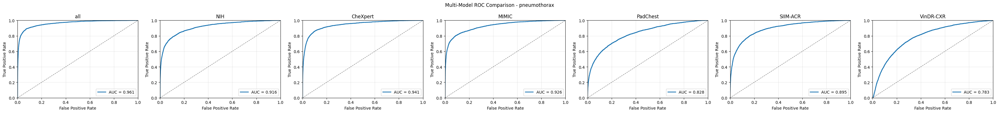

Saved plot: results/public_external_test/multi_model_roc_support_devices.png


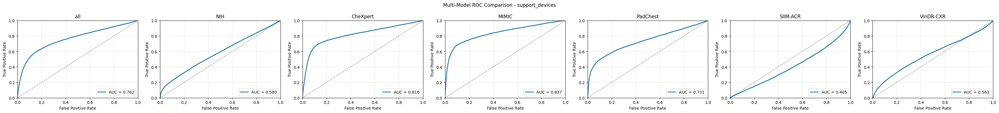

Saved plot: results/public_external_test/multi_model_roc_no_finding.png


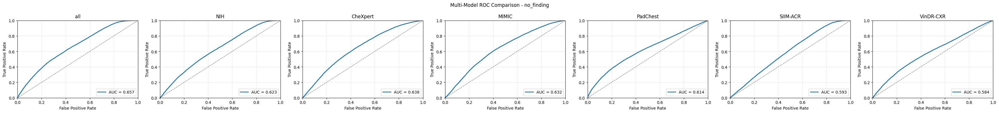

📈 Plotting Multi-Model PR Curves...
Saved plot: results/public_external_test/multi_model_pr_pneumothorax.png


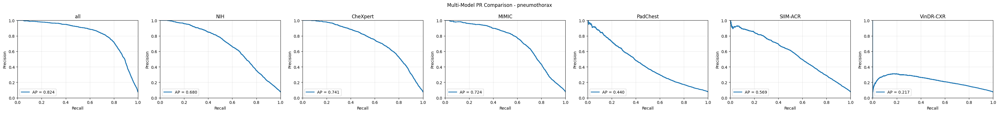

Saved plot: results/public_external_test/multi_model_pr_support_devices.png


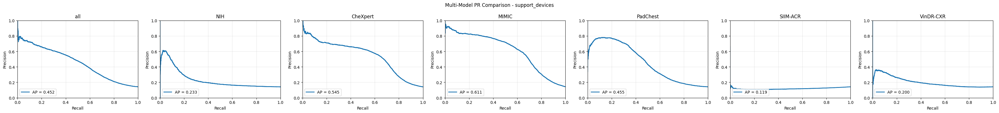

Saved plot: results/public_external_test/multi_model_pr_no_finding.png


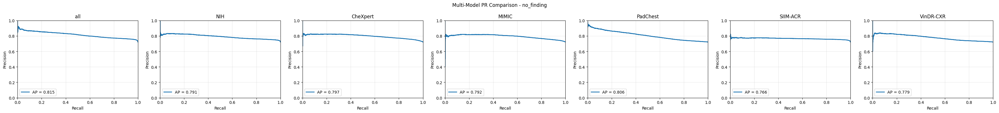

📈 Plotting Multi-Model ROC Curves with Datasets...
Saved plot: results/public_external_test/multi_model_roc_with_datasets_pneumothorax.png


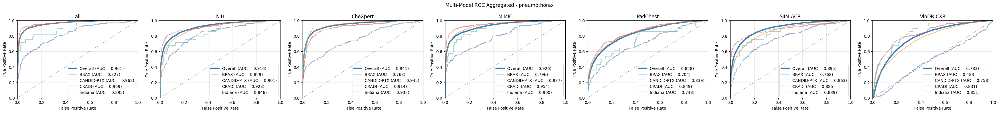

Saved plot: results/public_external_test/multi_model_roc_with_datasets_support_devices.png


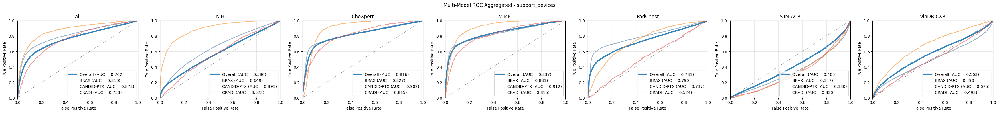

Saved plot: results/public_external_test/multi_model_roc_with_datasets_no_finding.png


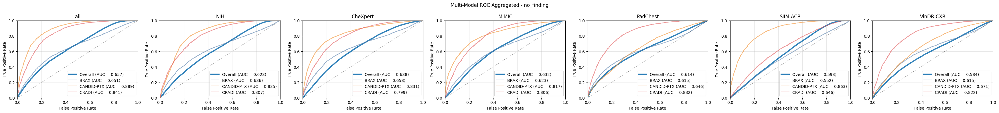

📈 Plotting Multi-Model PR Curves with Datasets...
Saved plot: results/public_external_test/multi_model_pr_with_datasets_pneumothorax.png


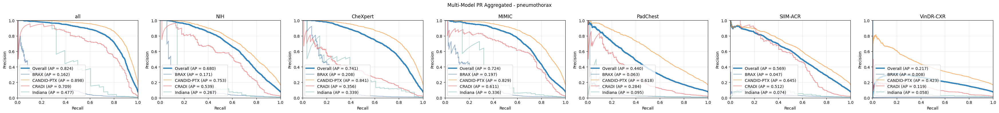

Saved plot: results/public_external_test/multi_model_pr_with_datasets_support_devices.png


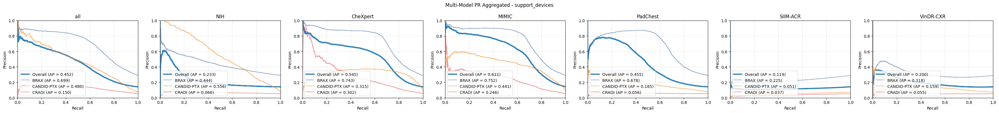

Saved plot: results/public_external_test/multi_model_pr_with_datasets_no_finding.png


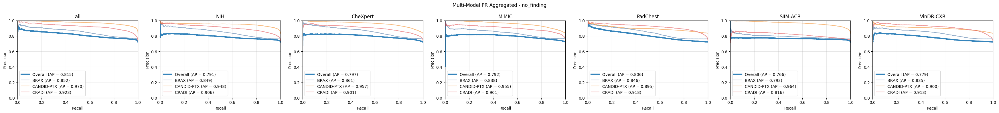

📊 Plotting Multi-Model Comparison - Sensitivity (Recall)...
Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_pneumothorax.png


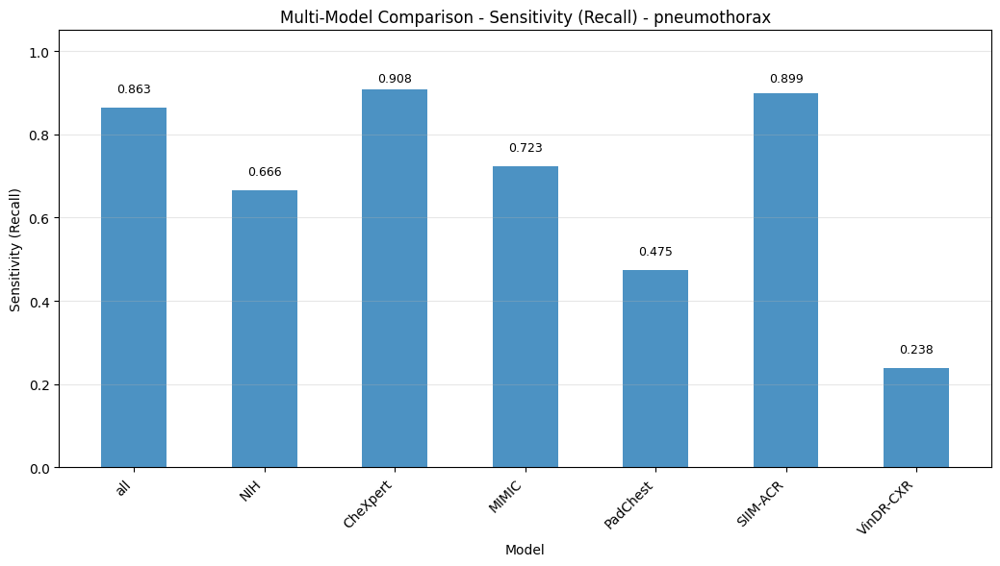

Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_support_devices.png


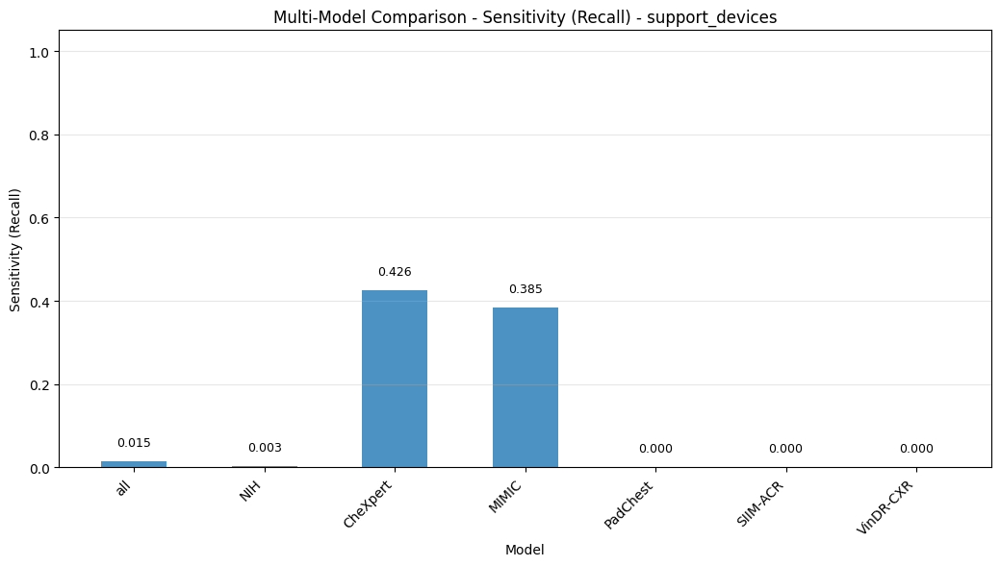

Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_no_finding.png


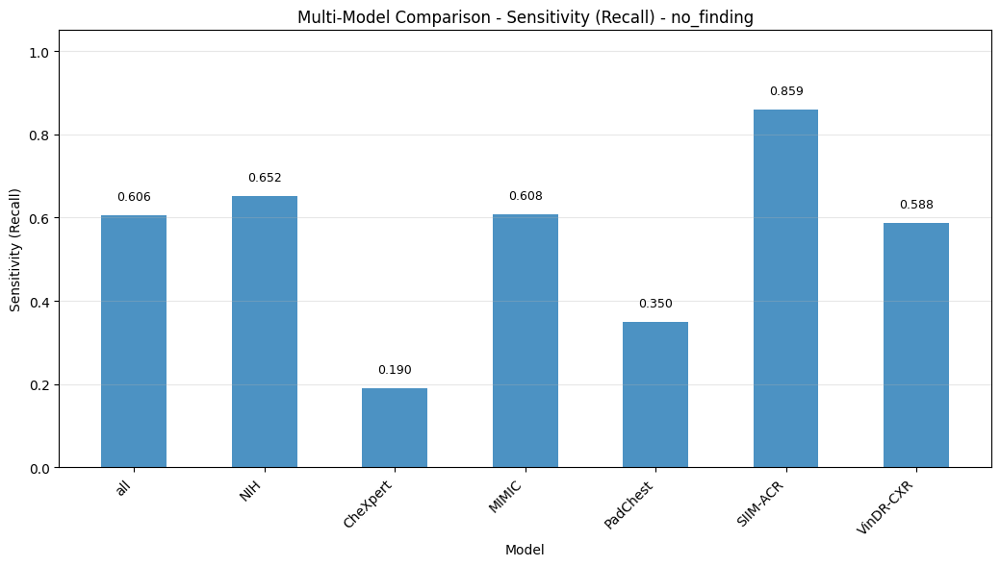

📊 Plotting Multi-Model Comparison - Specificity...
Saved plot: results/public_external_test/multi_model_comparison_Specificity_pneumothorax.png


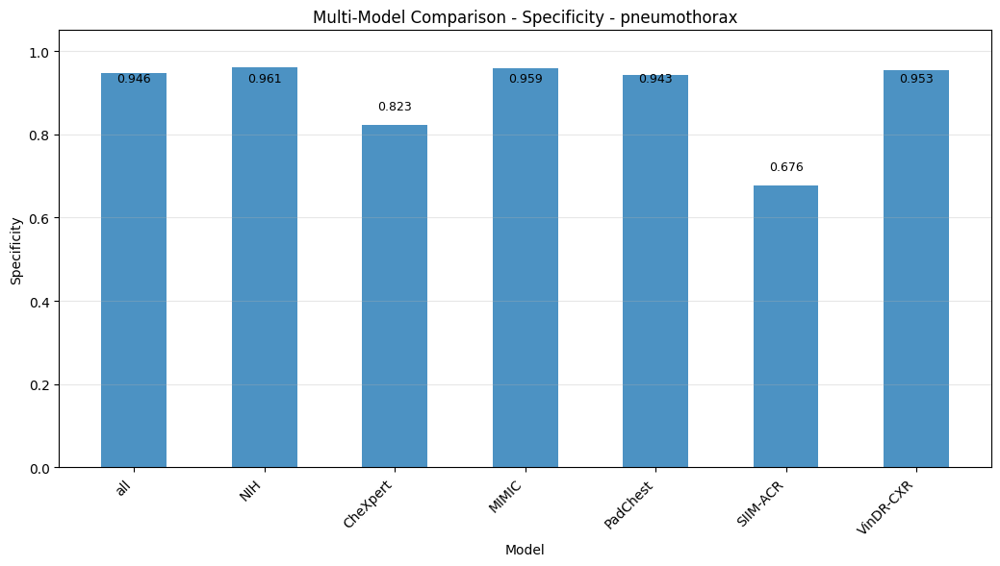

Saved plot: results/public_external_test/multi_model_comparison_Specificity_support_devices.png


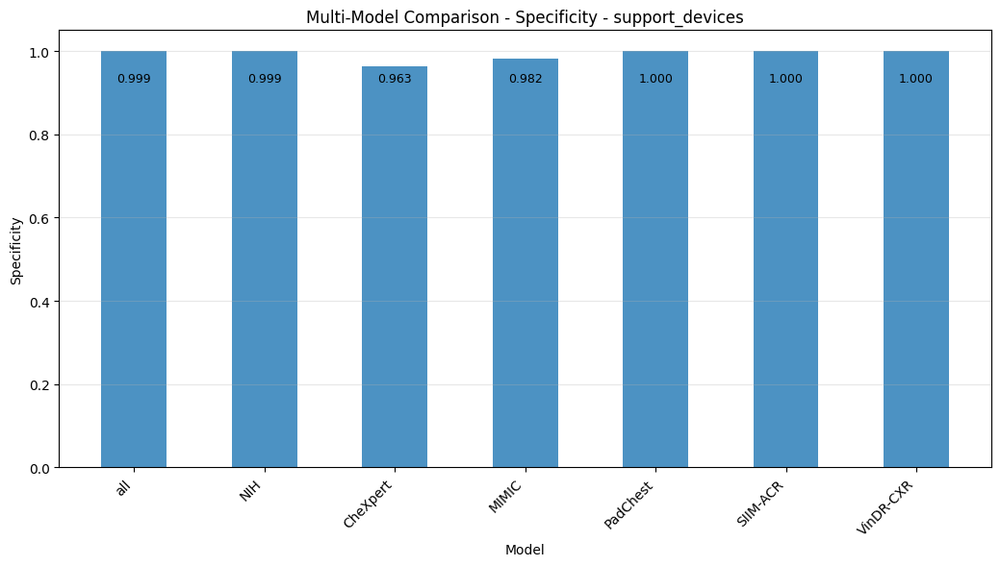

Saved plot: results/public_external_test/multi_model_comparison_Specificity_no_finding.png


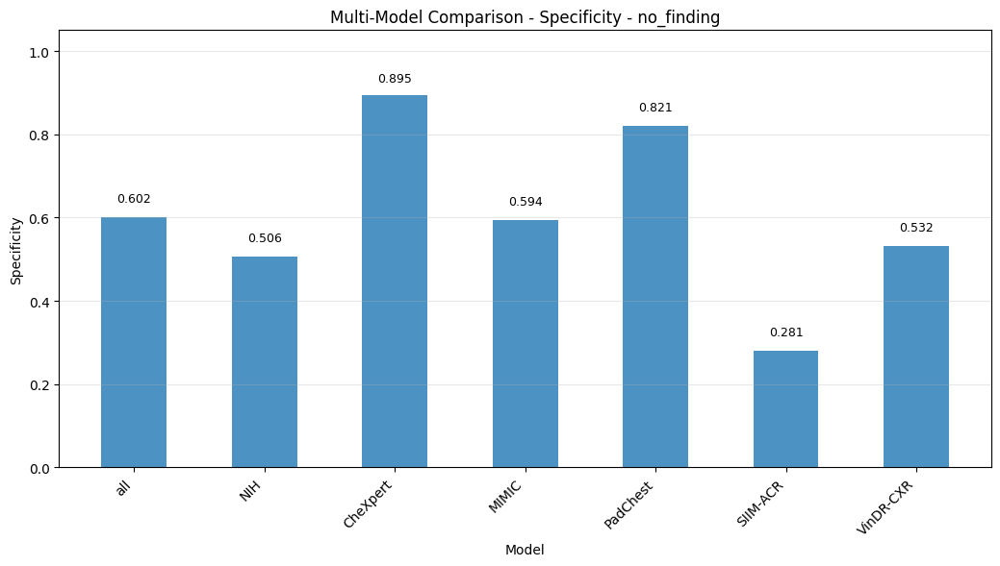

📊 Plotting Multi-Model Comparison - PPV (Precision)...
Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_pneumothorax.png


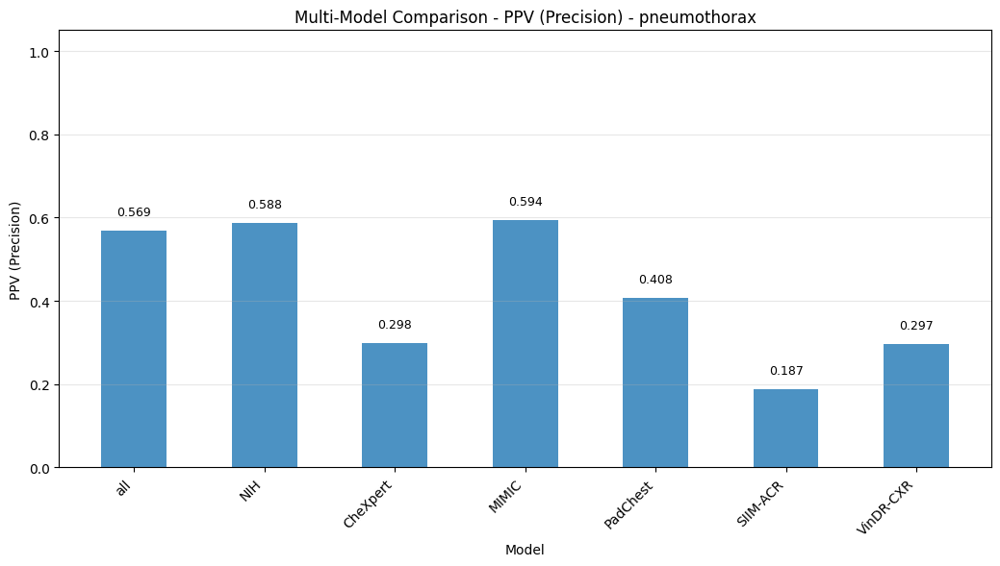

Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_support_devices.png


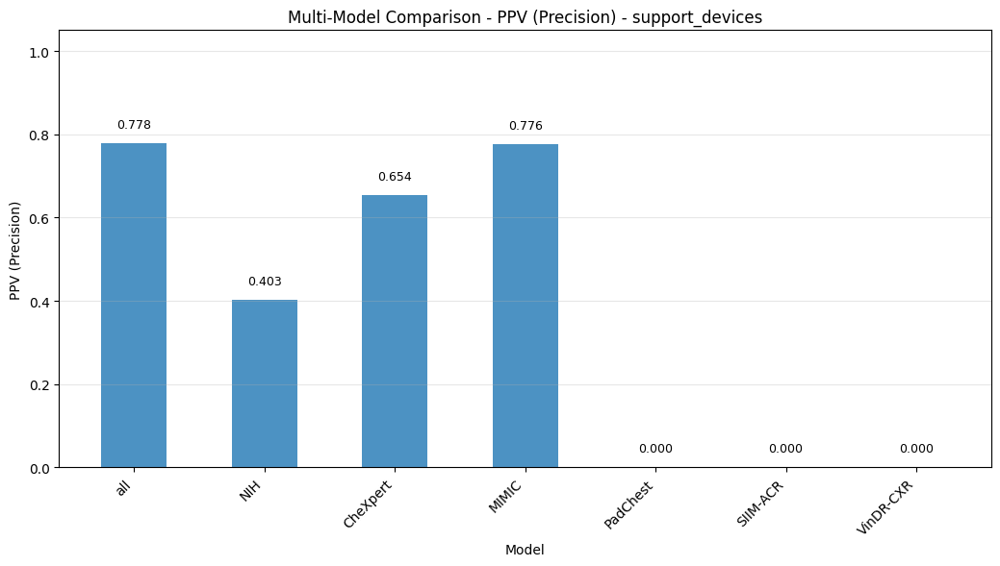

Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_no_finding.png


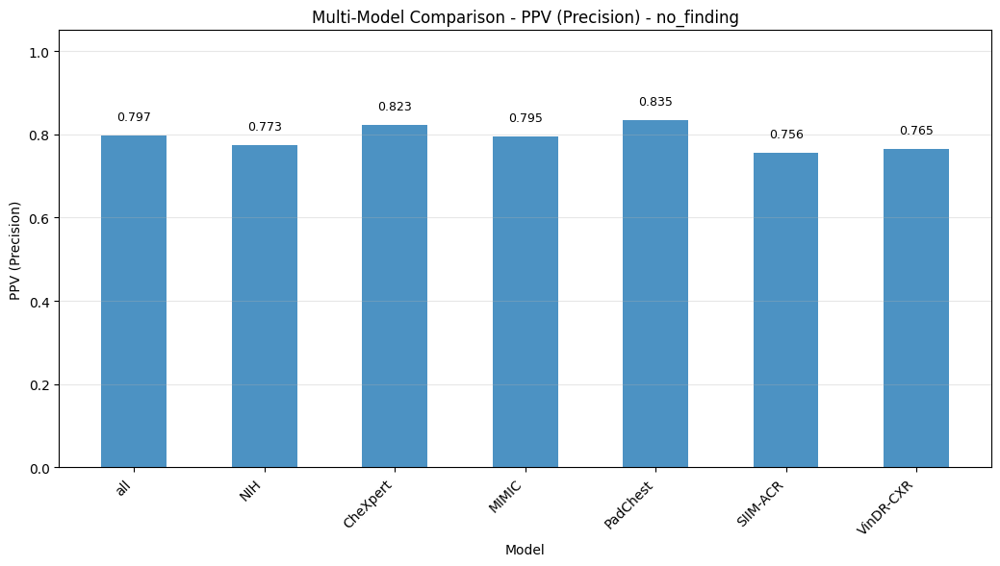

📊 Plotting Multi-Model Comparison - NPV...
Saved plot: results/public_external_test/multi_model_comparison_NPV_pneumothorax.png


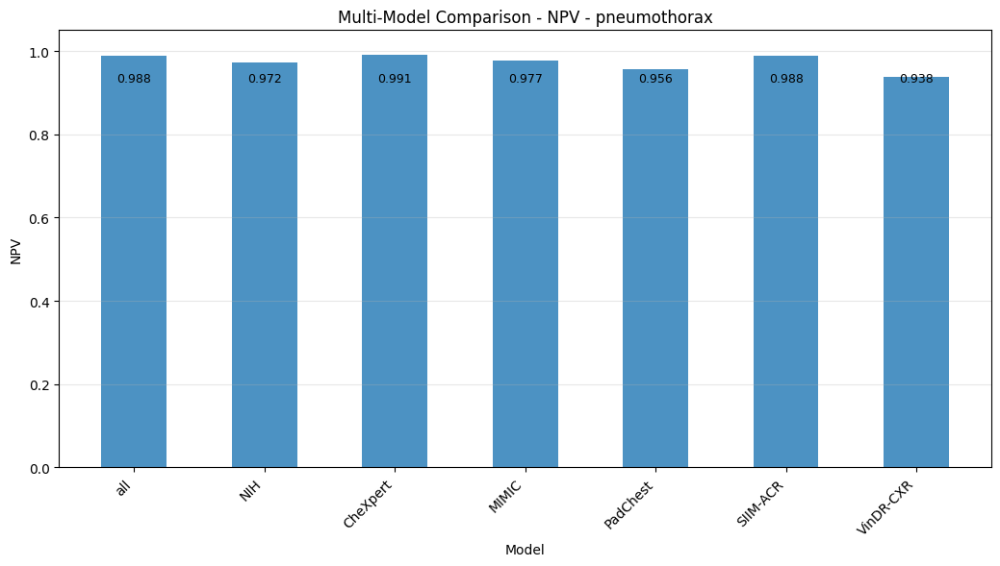

Saved plot: results/public_external_test/multi_model_comparison_NPV_support_devices.png


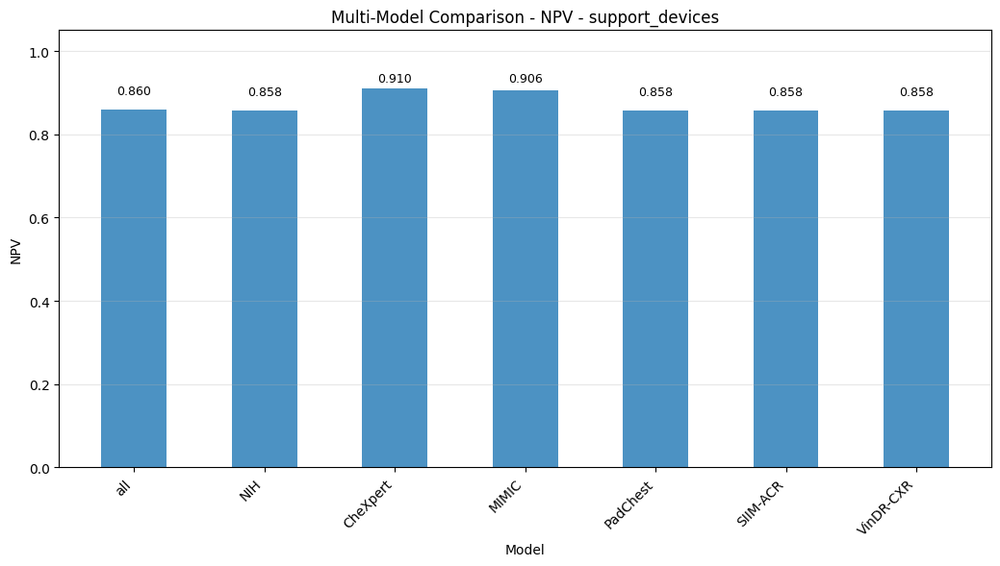

Saved plot: results/public_external_test/multi_model_comparison_NPV_no_finding.png


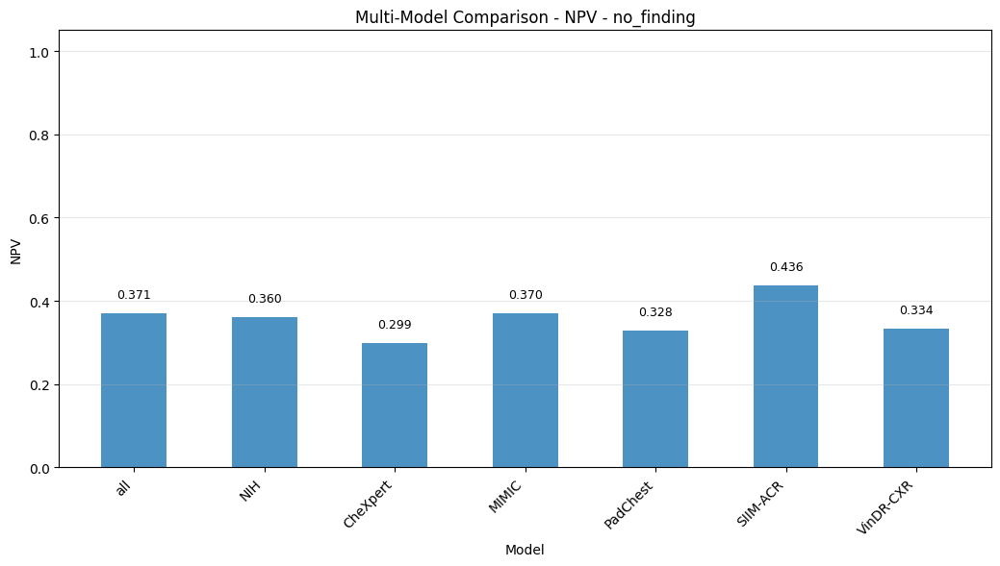

📊 Plotting Multi-Model Comparison - F1-score...
Saved plot: results/public_external_test/multi_model_comparison_F1-score_pneumothorax.png


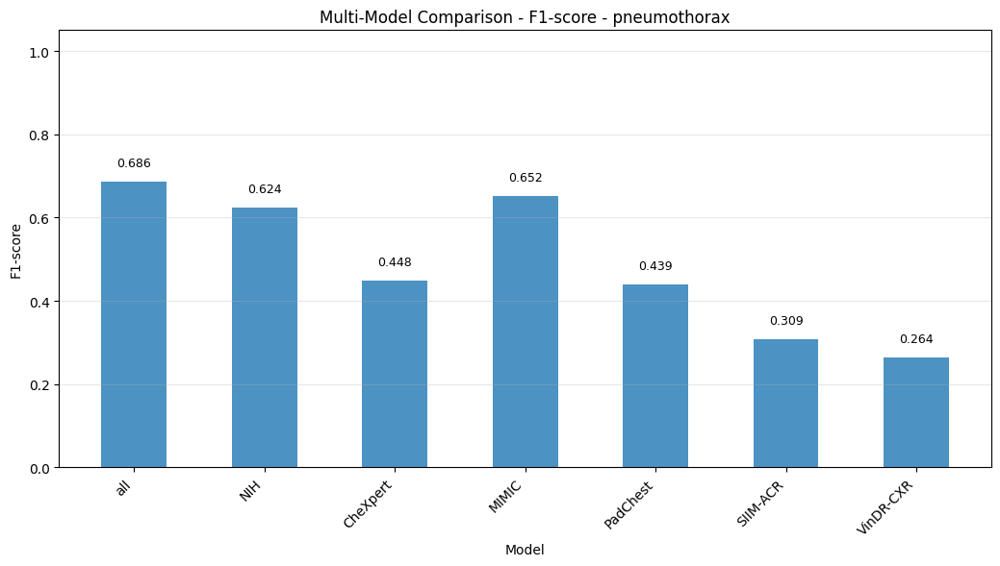

Saved plot: results/public_external_test/multi_model_comparison_F1-score_support_devices.png


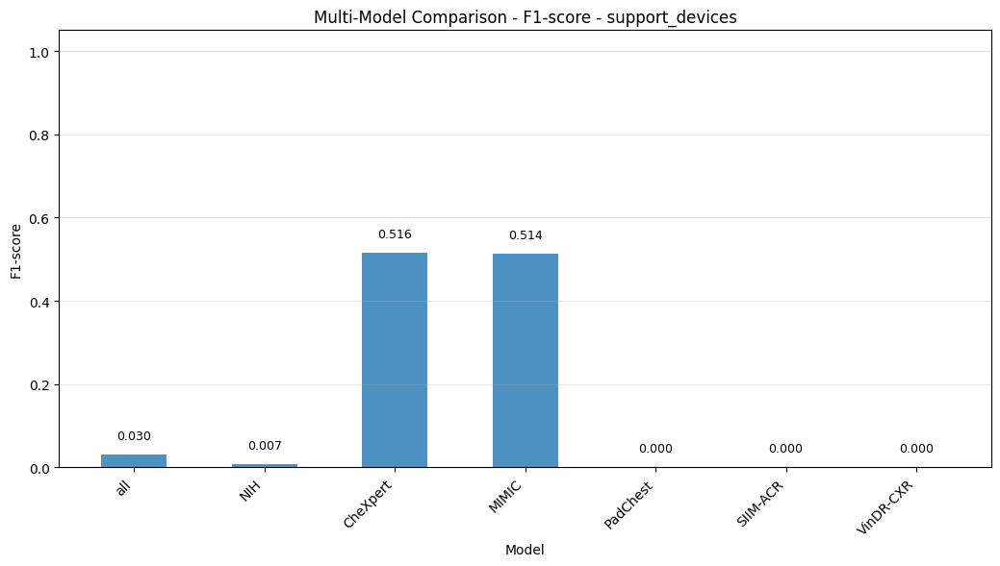

Saved plot: results/public_external_test/multi_model_comparison_F1-score_no_finding.png


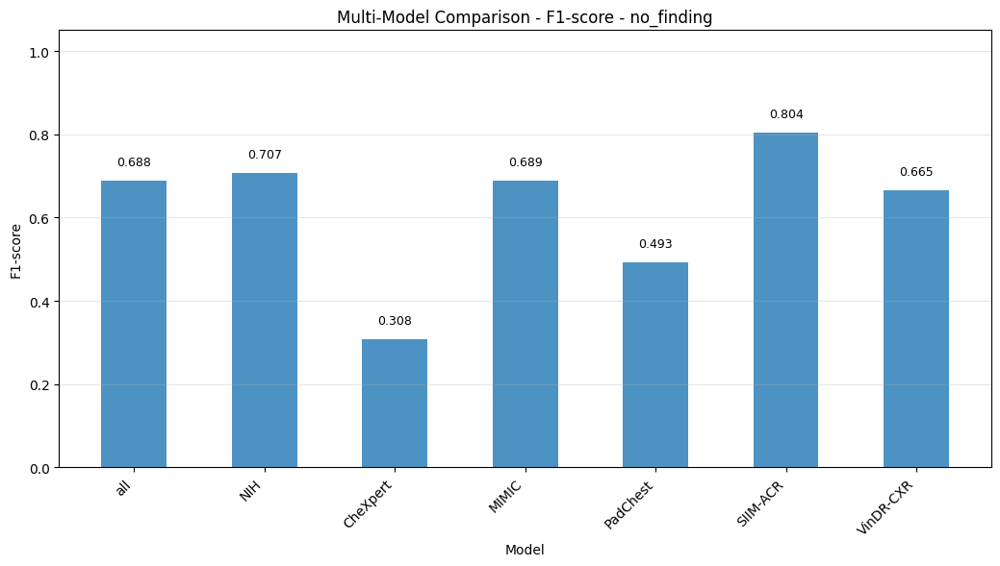

📊 Plotting Multi-Model Comparison - AUC...
Saved plot: results/public_external_test/multi_model_comparison_AUC_pneumothorax.png


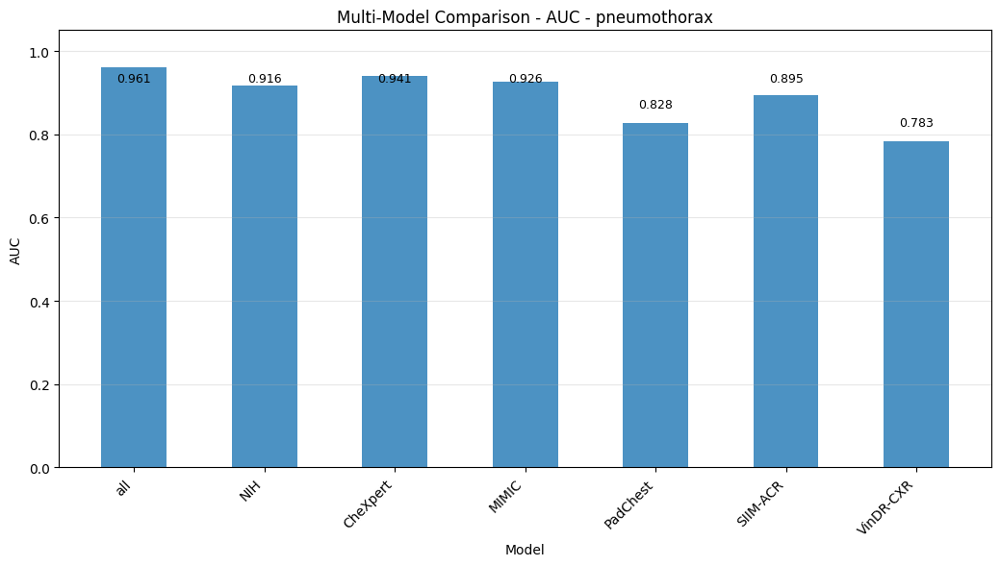

Saved plot: results/public_external_test/multi_model_comparison_AUC_support_devices.png


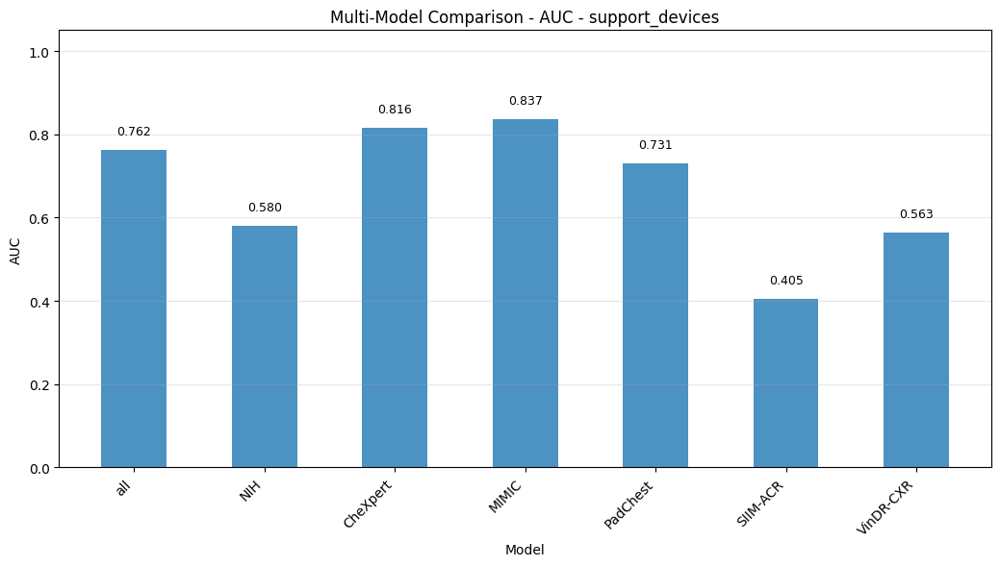

Saved plot: results/public_external_test/multi_model_comparison_AUC_no_finding.png


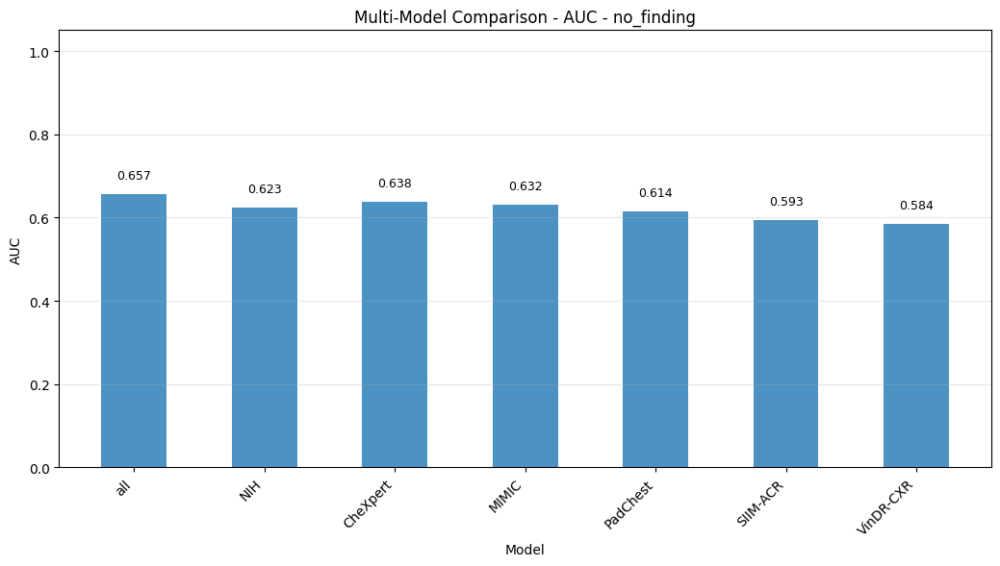

📊 Plotting Multi-Model Comparison - AP...
Saved plot: results/public_external_test/multi_model_comparison_AP_pneumothorax.png


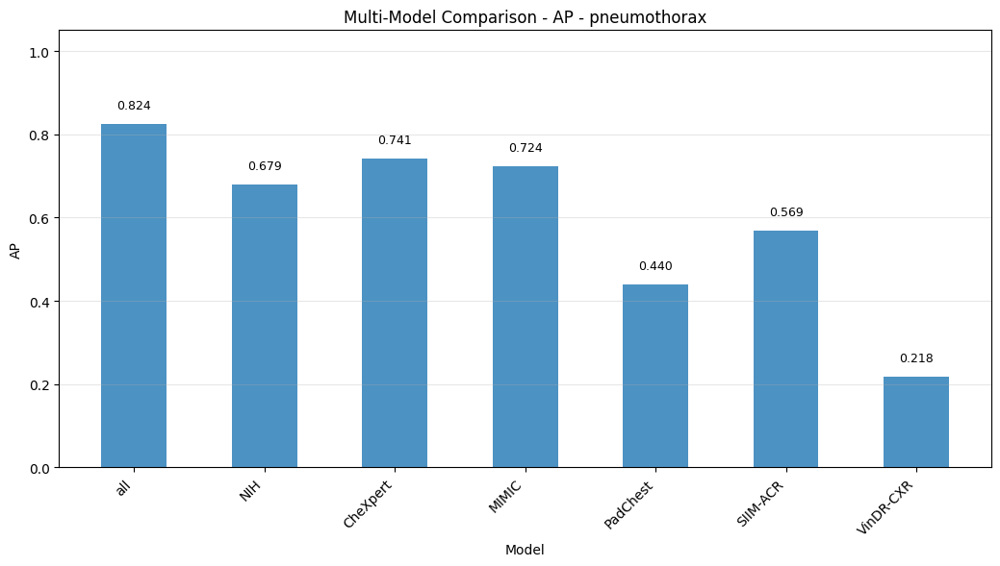

Saved plot: results/public_external_test/multi_model_comparison_AP_support_devices.png


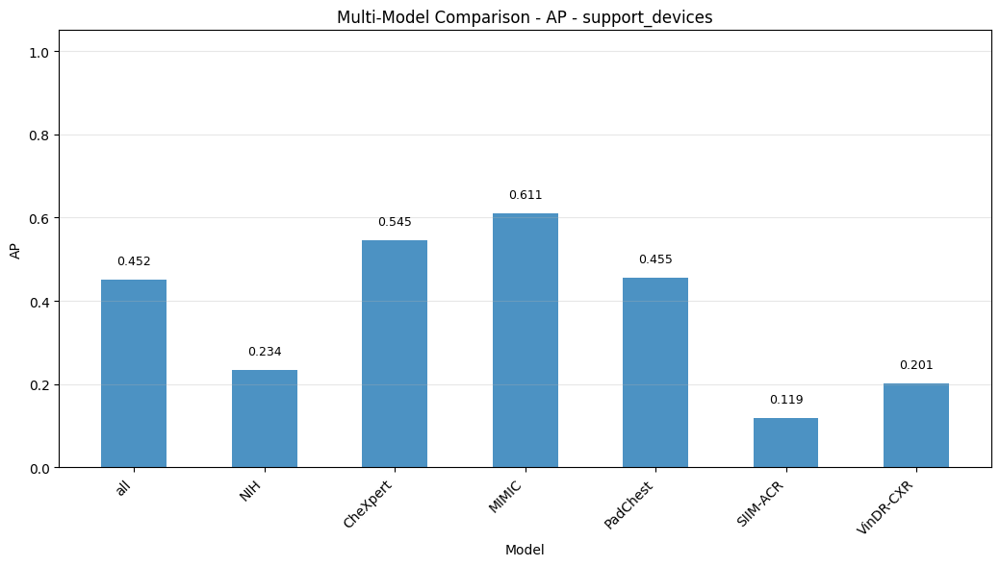

Saved plot: results/public_external_test/multi_model_comparison_AP_no_finding.png


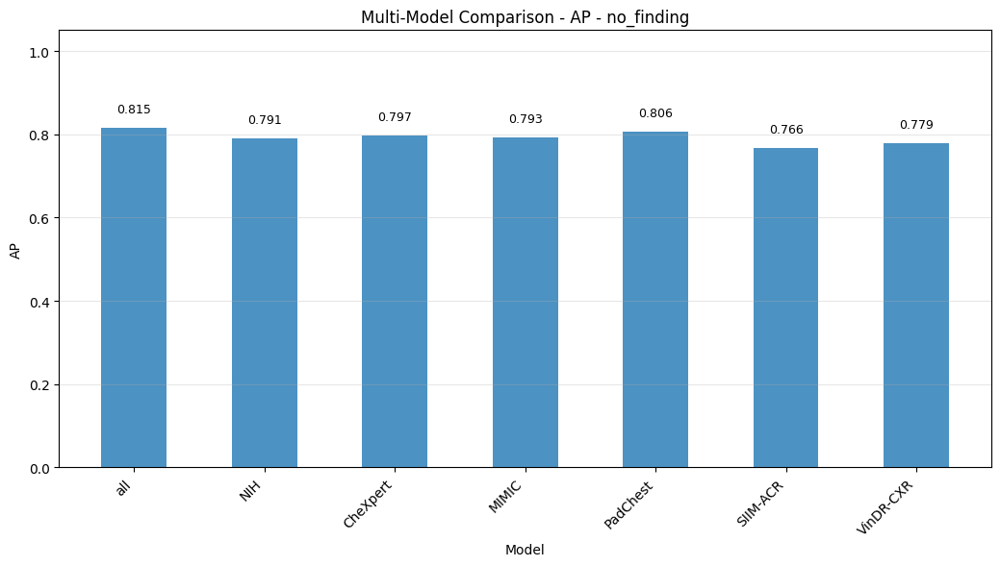

📊 Plotting Multi-Model Comprehensive Comparison...
Saved plot: results/public_external_test/multi_model_comprehensive_pneumothorax.png


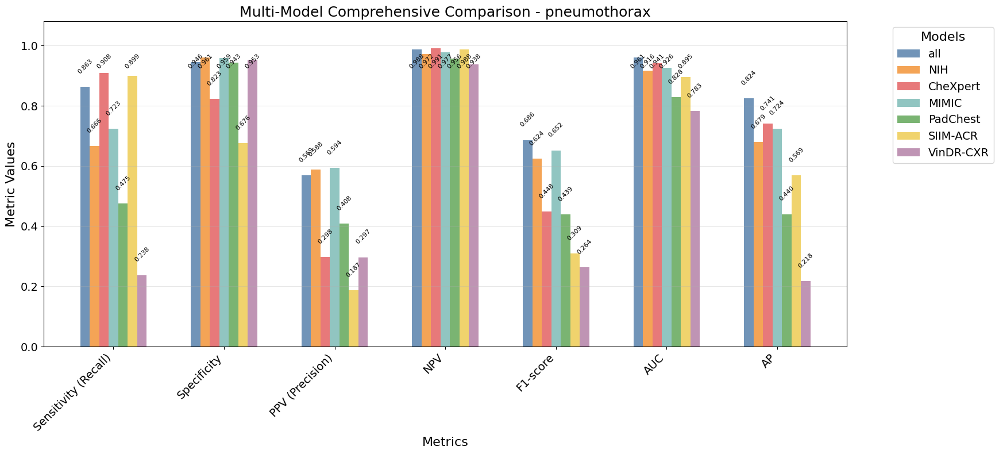

Saved plot: results/public_external_test/multi_model_comprehensive_support_devices.png


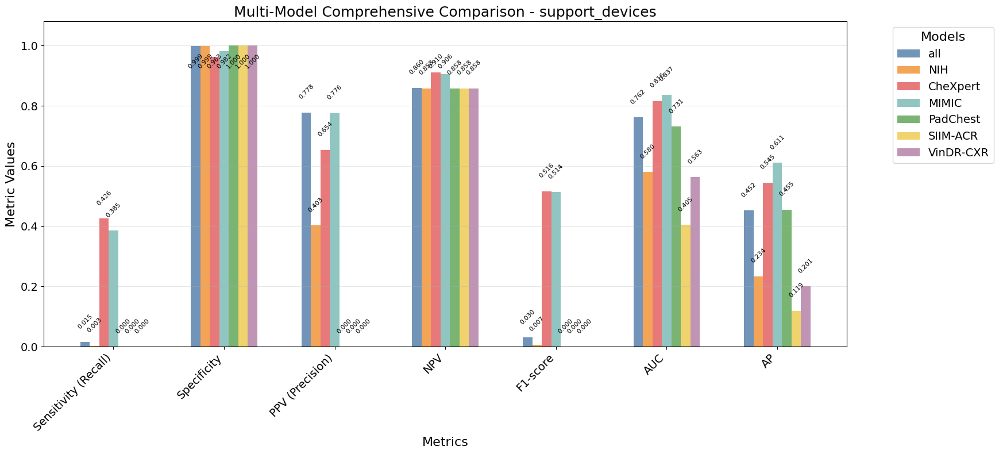

Saved plot: results/public_external_test/multi_model_comprehensive_no_finding.png


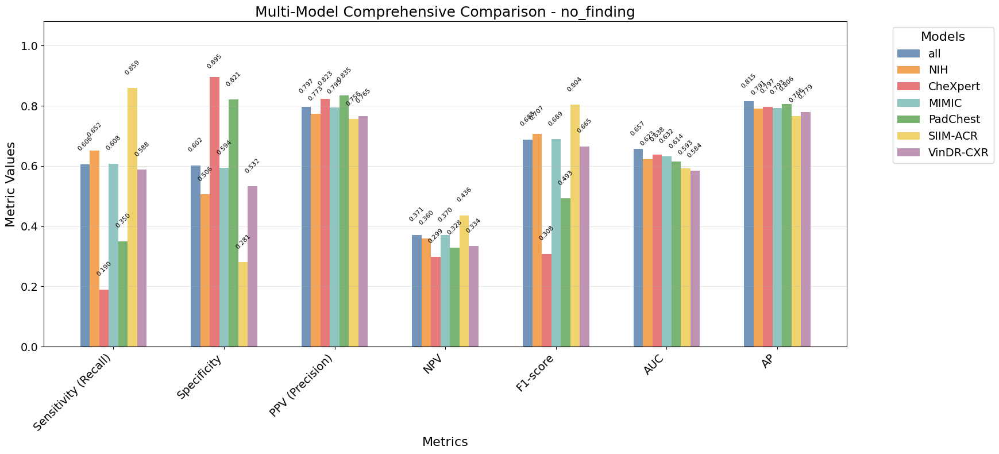

📊 Plotting Multi-Model Confusion Matrices...
Saved plot: results/public_external_test/multi_model_confusion_matrices_pneumothorax.png


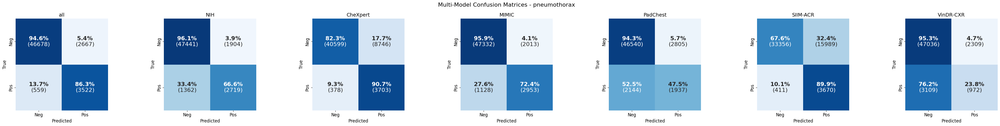

Saved plot: results/public_external_test/multi_model_confusion_matrices_support_devices.png


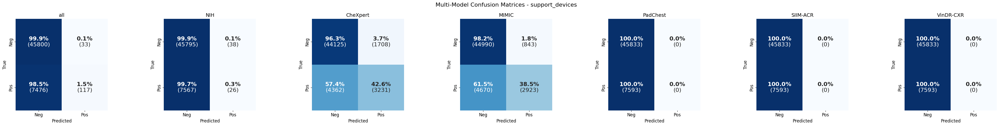

Saved plot: results/public_external_test/multi_model_confusion_matrices_no_finding.png


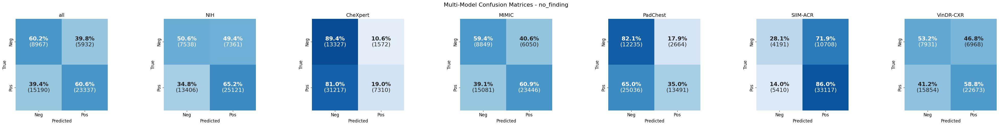

📊 Plotting Multi-Model Dataset Confusion Matrices...


cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_pneumothorax.png


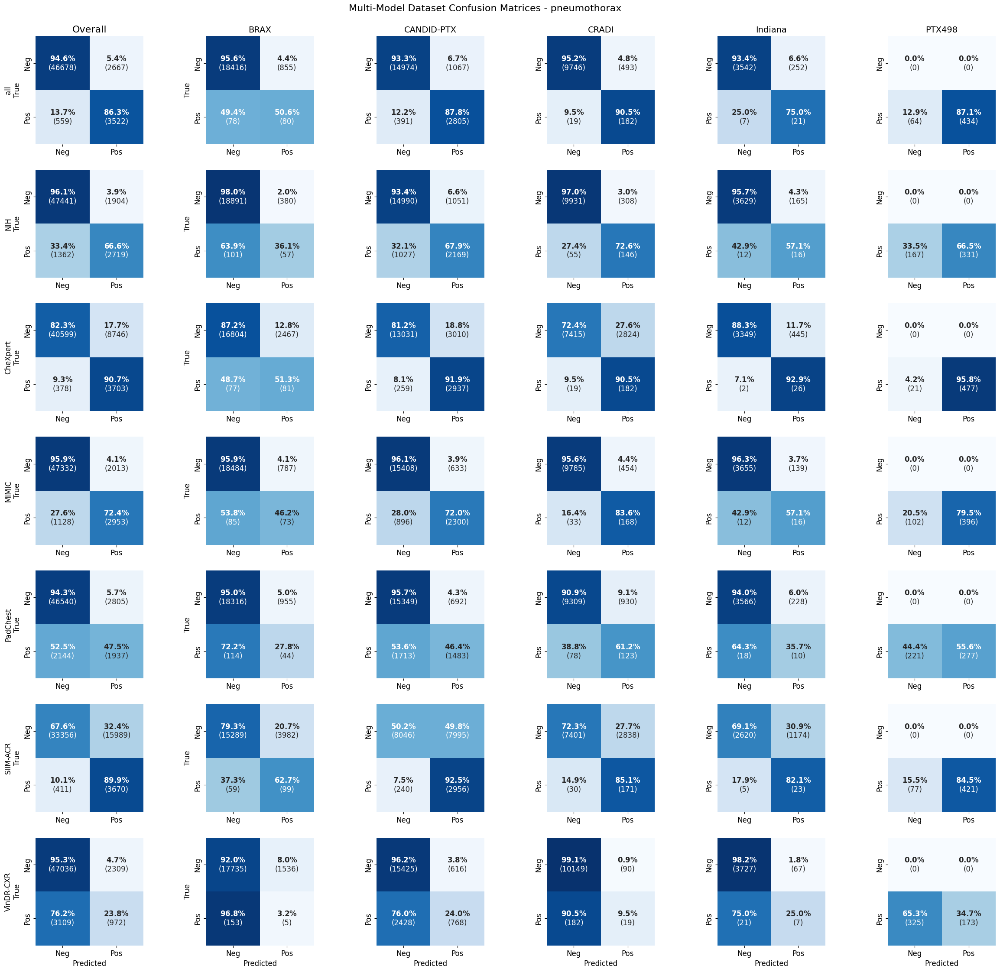

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_support_devices.png


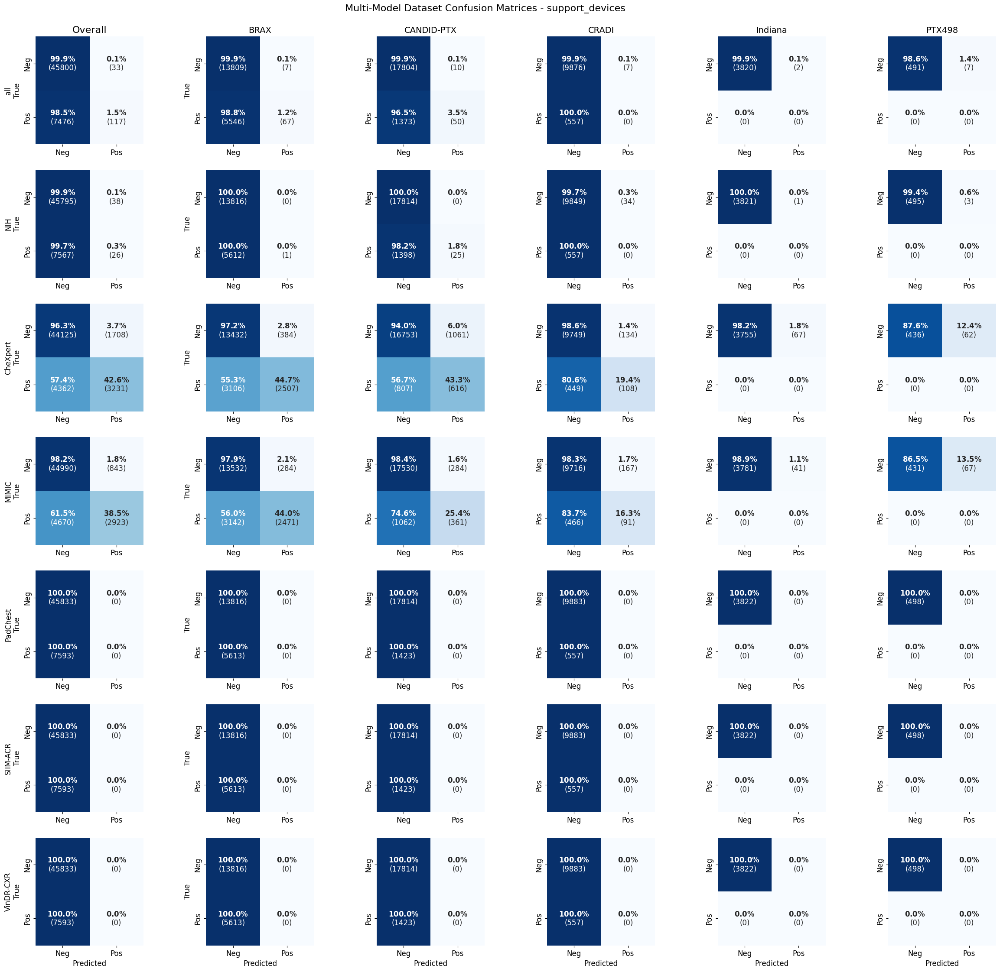

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_no_finding.png


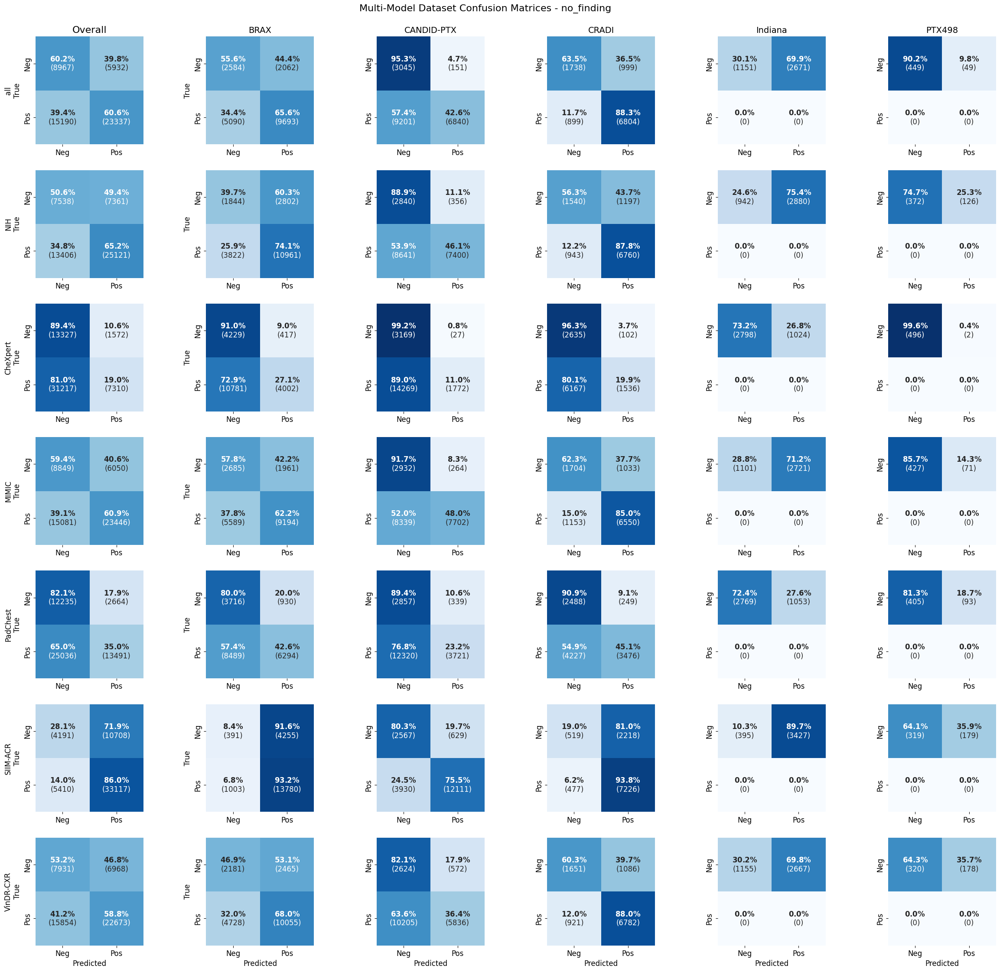


MULTI-MODEL COMPARISON SUMMARY
📊 Aggregated 7 models
📈 Generated ROC and PR comparison plots
📈 Generated ROC and PR plots with individual datasets
📊 Generated comparison plots for 7 metrics
📊 Generated confusion matrix comparison plots
💾 All results saved to: results/public_external_test


In [35]:
# Run comprehensive multi-model evaluation
multi_model_results = evaluate_multiple_models(
    model_evaluation_dict=model_evaluation_dict,
    class_names=class_names,
    save_dir='results/public_external_test',
    log_wandb=False,
    display=True,
    comparison_metrics=None,
)

# Access results
individual_results = multi_model_results['individual_results']
aggregated_results = multi_model_results['aggregated_results']

In [36]:
multi_model_results_bk = multi_model_results.copy()

# Use model trained with also valid set for comparison


In [80]:
# [checkpoint not released] weight_path_dictionary['all_valid'] = 'wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'

In [81]:
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [86]:
weight_path_dictionary_multilabel

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras',
 'all_valid': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'}

In [83]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    if model_name == 'all_valid':
        print(model_name)
        print(f'Loading {model_path}')
        #model.load_weights(model_path_dictionary.get(model_name))
        print('Model loaded successfully')
        
        # LOAD THE MODEL
        y_probs = model.predict(external_test_generator, verbose=1)
        df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
        df.to_csv('test_filled.csv', index = False)
        y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
        dataset_values = df['dataset'].values
    
        # Store evaluation parameters for this model
        model_evaluation_dict[model_name] = {
            'y_true': y_true,
            'y_probs': y_probs,
            'dataset_values': dataset_values,
            'threshold': [0.2, 0.5, 0.5],
            'use_optimal_thresholds': False,
            'n_bootstraps': 1000,
        }



all_valid
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras
2025-05-28 12:19:39 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
6679/6679 [==============================] - 2778s 416ms/step


In [85]:
df['all_pneumothorax_pred'] = df['all_valid_pneumothorax_pred']
df['all_no_finding_pred'] = df['all_valid_no_finding_pred']
df['all_support_devices_pred'] = df['all_valid_support_devices_pred']

In [87]:
model_name = 'all'
y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
dataset_values = df['dataset'].values

In [92]:
from cxr.evaluate import evaluate_model

--- Starting Model Evaluation ---
Dataset-specific evaluation enabled. Found datasets: ['BRAX' 'CANDID-PTX' 'CRADI' 'Indiana' 'PTX498']
Dataset 'BRAX': 19429 samples
Dataset 'CANDID-PTX': 19237 samples
Dataset 'CRADI': 10440 samples
Dataset 'Indiana': 3822 samples
Dataset 'PTX498': 498 samples
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/label_cooccurrence_matrix.png


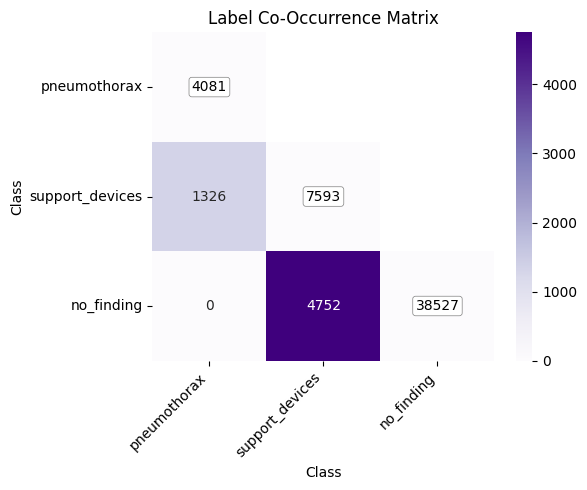


Using provided list/array of thresholds.

OVERALL DATASET EVALUATION

--- Evaluating Dataset: Overall ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (53426, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (53426, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (53426, 3)
DEBUG: Starting bootstrap loop. n_samples: 53426, type: <class 'int'>


Bootstrapping:   0%|                                                                                                                                                                            | 0/1000 [00:00<?, ?it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (53426,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (53426, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (53426, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (53426, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [06:46<00:00,  2.46it/s]



DATASET-SPECIFIC EVALUATION

--- Evaluating Dataset: BRAX ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (19429, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (19429, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (19429, 3)
DEBUG: Starting bootstrap loop. n_samples: 19429, type: <class 'int'>


...


--- Evaluating Dataset: PTX498 ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (498, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (498, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG: Starting bootstrap loop. n_samples: 498, type: <class 'int'>


Bootstrapping:   1%|█▍                                                                                                                                                                  | 9/1000 [00:00<00:11, 82.89it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (498,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (498, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (498, 3)


Bootstrapping: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:12<00:00, 81.68it/s]


Saved combined dataset metrics: results/public_external_test/all/combined_dataset_metrics_summary.csv

============================== METRICS SUMMARY ==============================
🔍 Global Metrics (Mean, 95% CI):
        Category            Accuracy           Precision Recall (Sensitivity)            F1-score                 AUC
         Overall 0.493 (0.489–0.497)                 N/A                  N/A                 N/A                 N/A
   Macro Average                 N/A 0.718 (0.696–0.743)  0.478 (0.474–0.482)  0.456 (0.452–0.46) 0.792 (0.789–0.796)
   Micro Average                 N/A 0.758 (0.754–0.763)    0.5 (0.496–0.505) 0.603 (0.599–0.607)                 N/A
Weighted Average                 N/A  0.781 (0.77–0.792)    0.5 (0.496–0.505)  0.565 (0.56–0.569)  0.695 (0.69–0.699)

📊 Per-Class Metrics (Mean, 95% CI):
          Class          Prevalence Sensitivity (Recall)         Specificity     PPV (Precision)                 NPV            F1-score                 AUC   

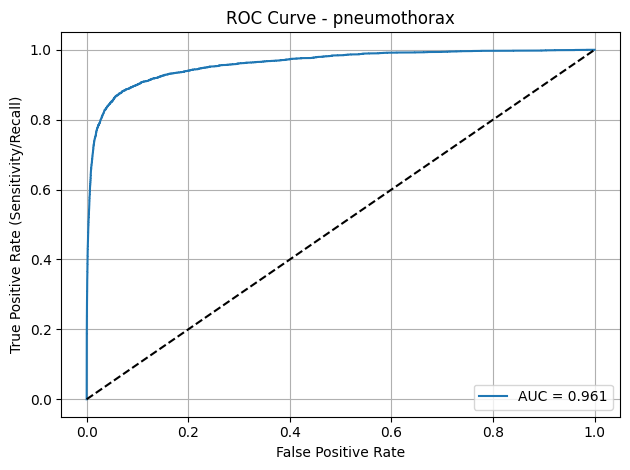

Saved plot: results/public_external_test/all/roc_curve_support_devices.png


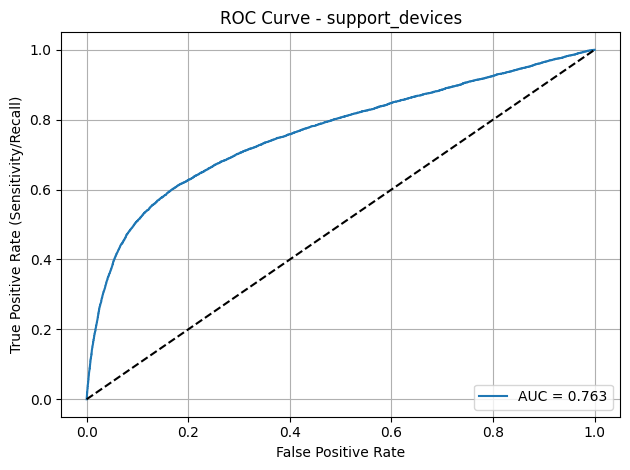

Saved plot: results/public_external_test/all/roc_curve_no_finding.png


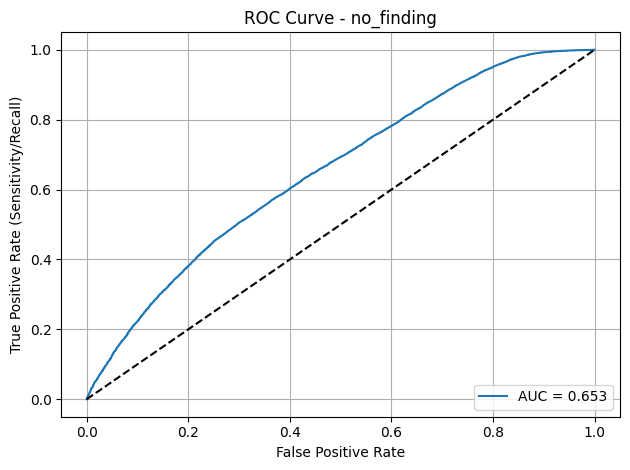

📈 Plotting Precision-Recall Curves...
Saved plot: results/public_external_test/all/pr_curve_pneumothorax.png


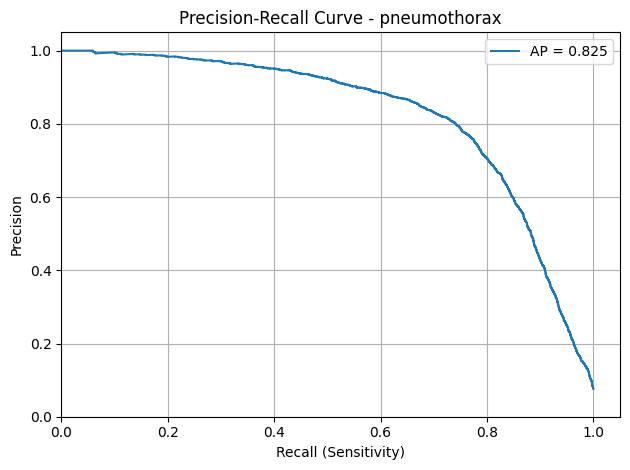

Saved plot: results/public_external_test/all/pr_curve_support_devices.png


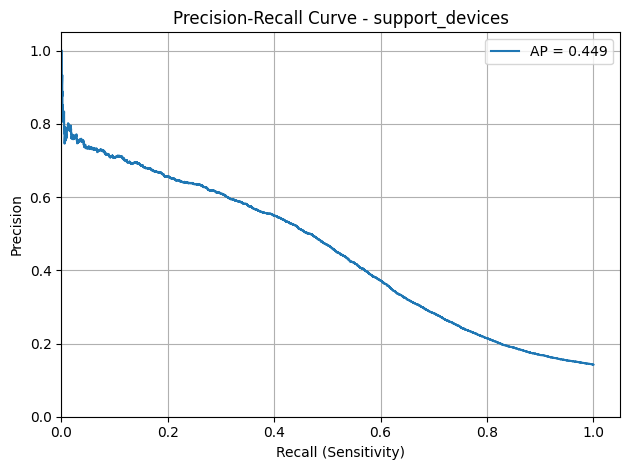

Saved plot: results/public_external_test/all/pr_curve_no_finding.png


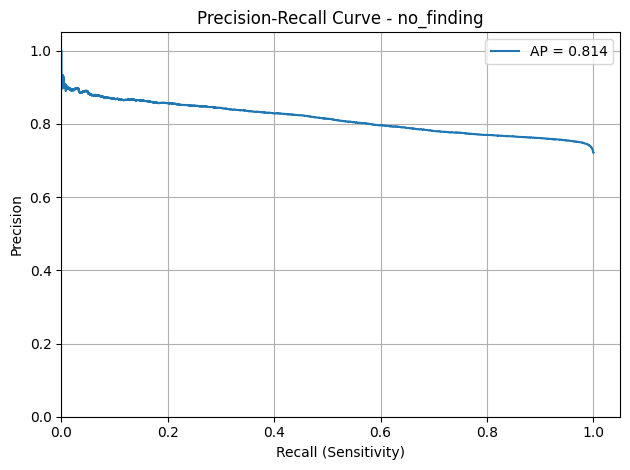

📊 Plotting Confusion Matrices...
Saved plot: results/public_external_test/all/confusion_matrix_norm_pneumothorax.png


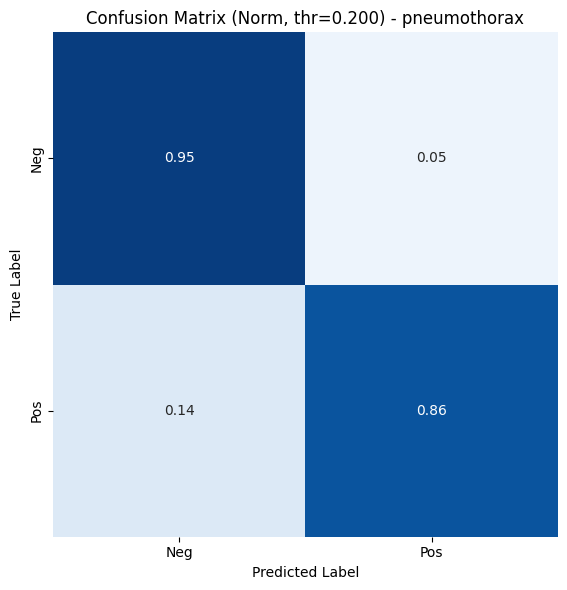

Saved plot: results/public_external_test/all/confusion_matrix_raw_pneumothorax.png


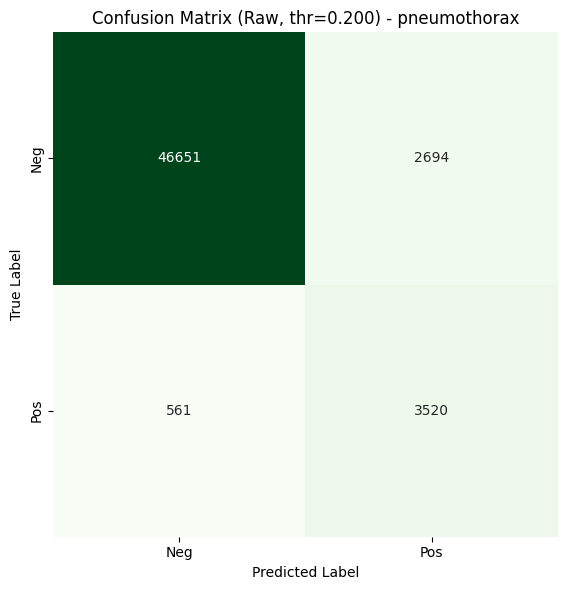

Saved plot: results/public_external_test/all/confusion_matrix_combined_pneumothorax.png


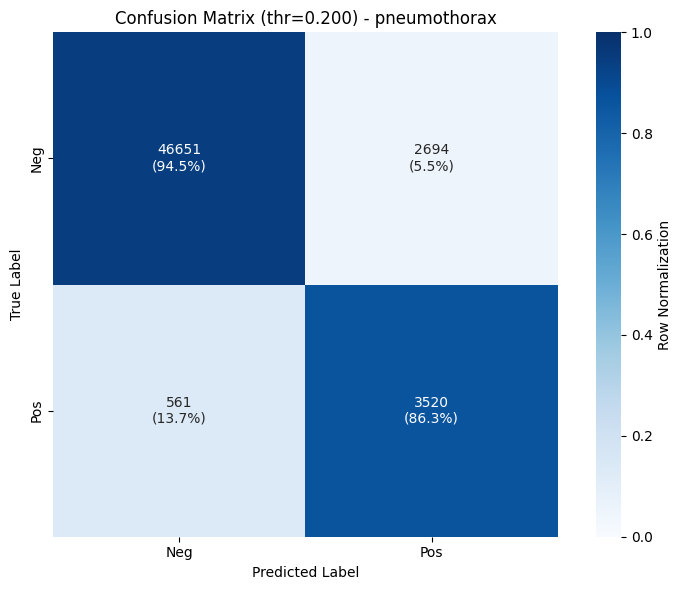

Saved plot: results/public_external_test/all/confusion_matrix_norm_support_devices.png


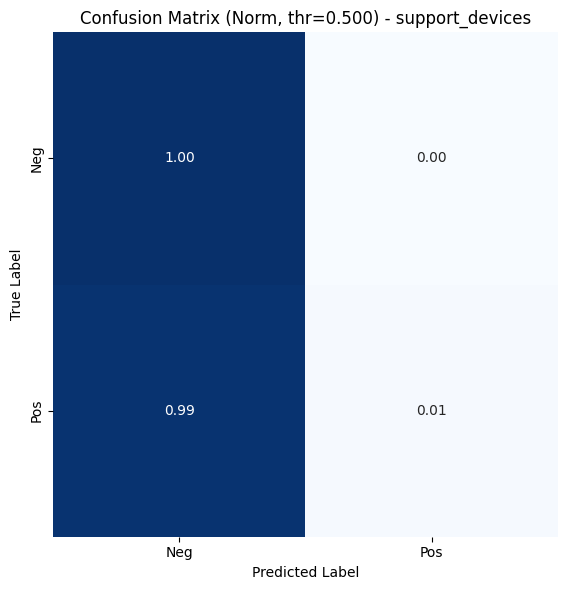

Saved plot: results/public_external_test/all/confusion_matrix_raw_support_devices.png


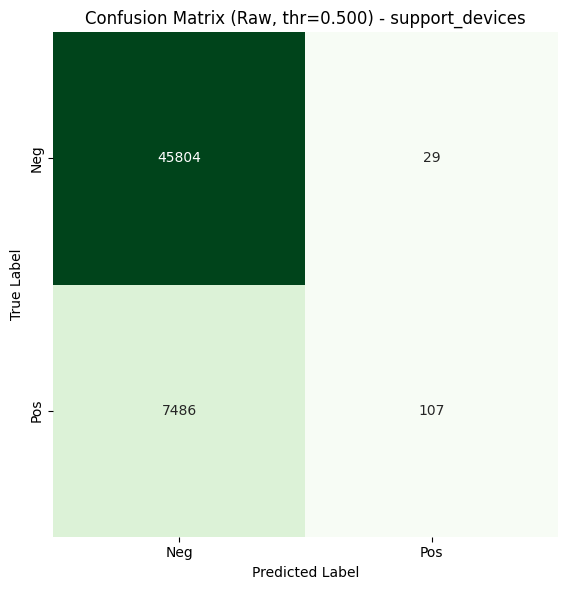

Saved plot: results/public_external_test/all/confusion_matrix_combined_support_devices.png


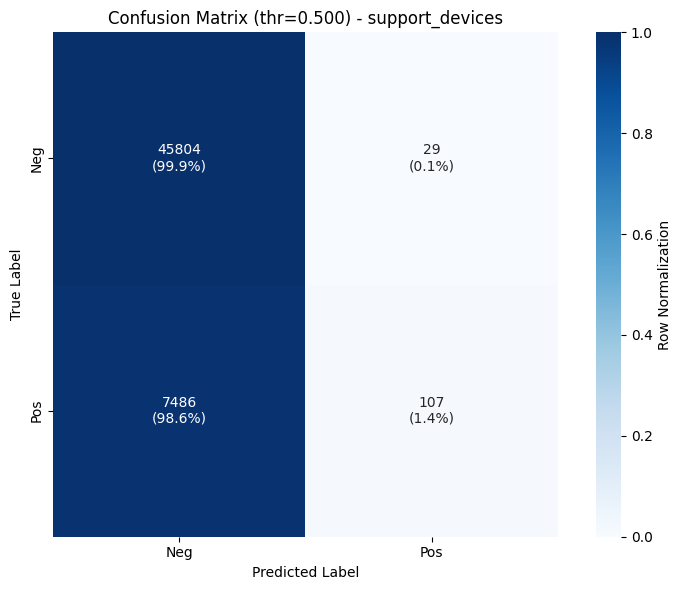

Saved plot: results/public_external_test/all/confusion_matrix_norm_no_finding.png


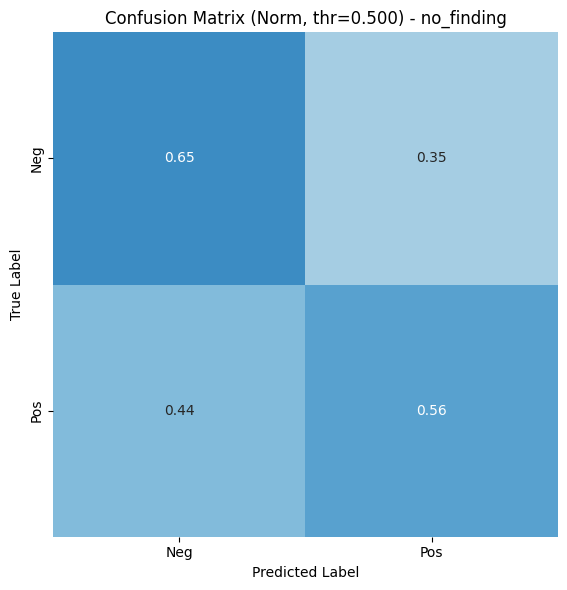

Saved plot: results/public_external_test/all/confusion_matrix_raw_no_finding.png


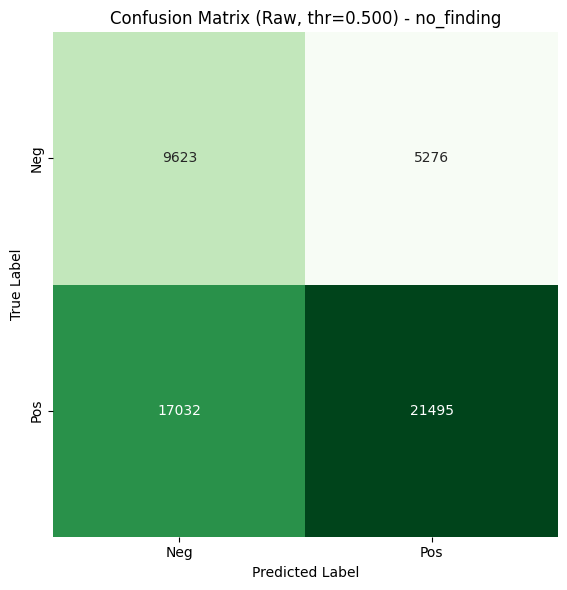

Saved plot: results/public_external_test/all/confusion_matrix_combined_no_finding.png


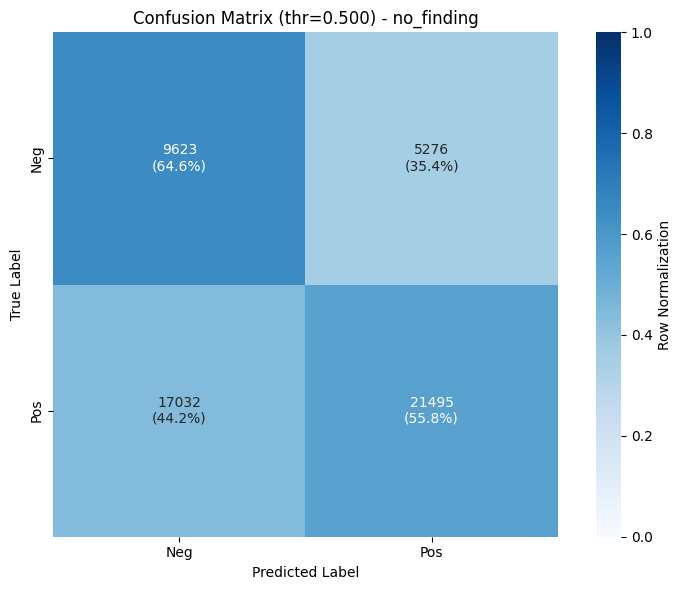

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/threshold_sweep_pneumothorax.png


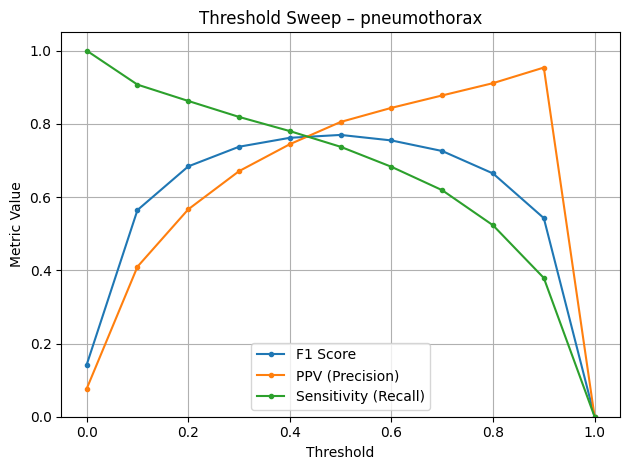

Saved plot: results/public_external_test/all/threshold_sweep_support_devices.png


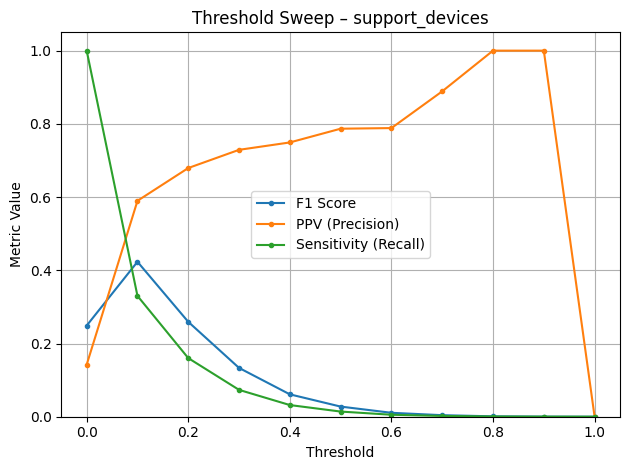

Saved plot: results/public_external_test/all/threshold_sweep_no_finding.png


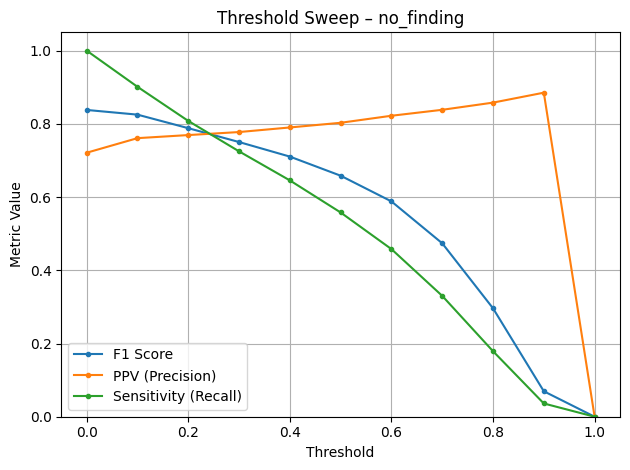

Saved threshold sweep table: results/public_external_test/all/threshold_sweep_table.csv

Generating dataset-specific plots...

Plots for dataset: BRAX
📈 Plotting ROC Curves - BRAX...
Saved plot: results/public_external_test/all/dataset_BRAX/roc_curve_pneumothorax.png


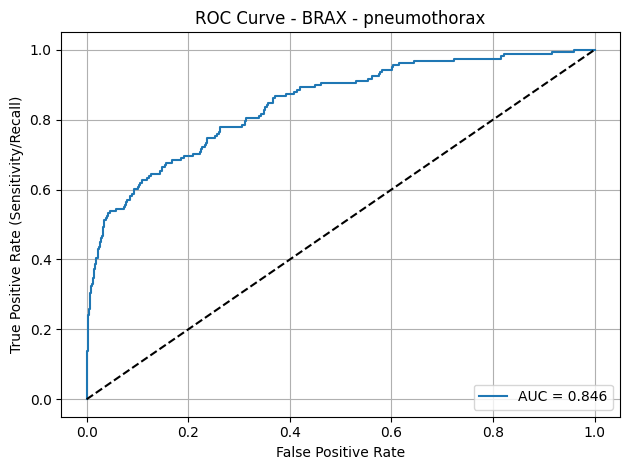

Saved plot: results/public_external_test/all/dataset_BRAX/roc_curve_support_devices.png


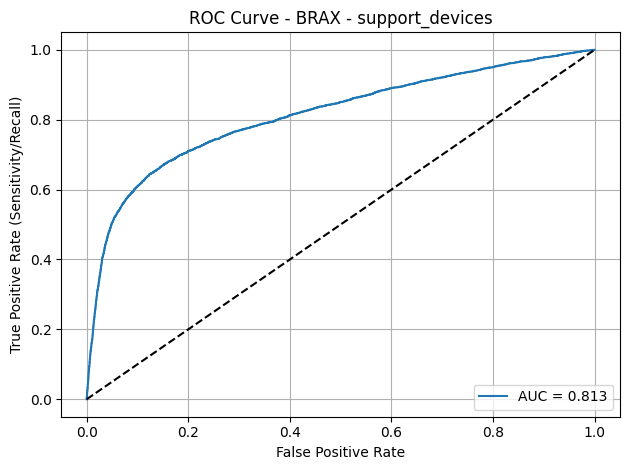

Saved plot: results/public_external_test/all/dataset_BRAX/roc_curve_no_finding.png


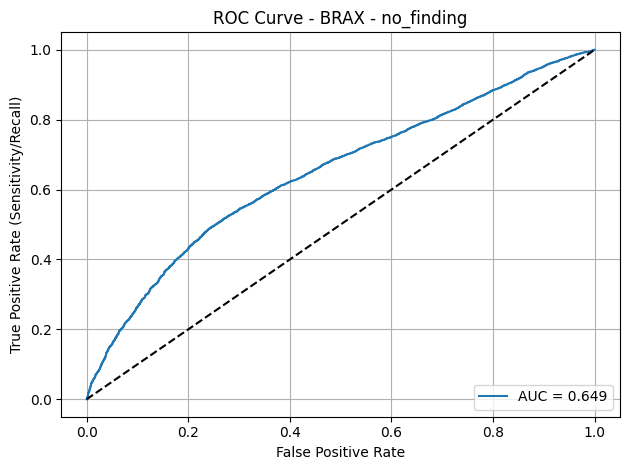

📈 Plotting Precision-Recall Curves - BRAX...
Saved plot: results/public_external_test/all/dataset_BRAX/pr_curve_pneumothorax.png


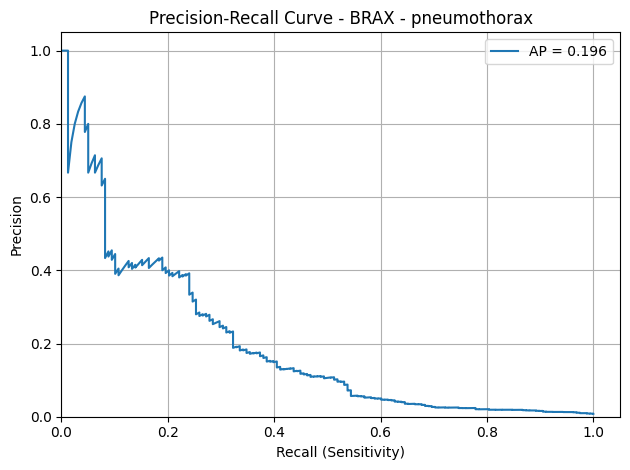

Saved plot: results/public_external_test/all/dataset_BRAX/pr_curve_support_devices.png


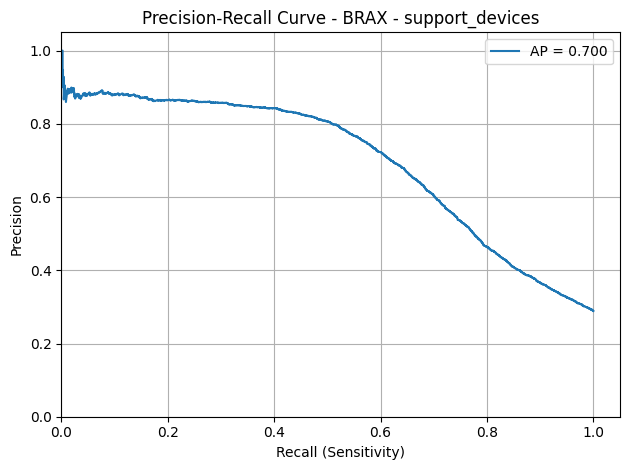

Saved plot: results/public_external_test/all/dataset_BRAX/pr_curve_no_finding.png


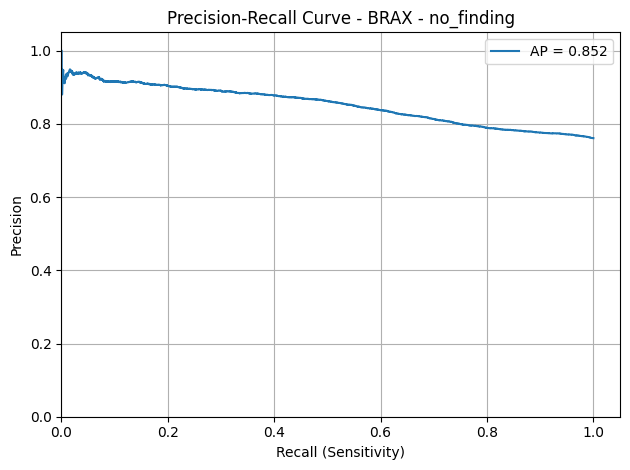

📊 Plotting Confusion Matrices - BRAX...
Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_norm_pneumothorax.png


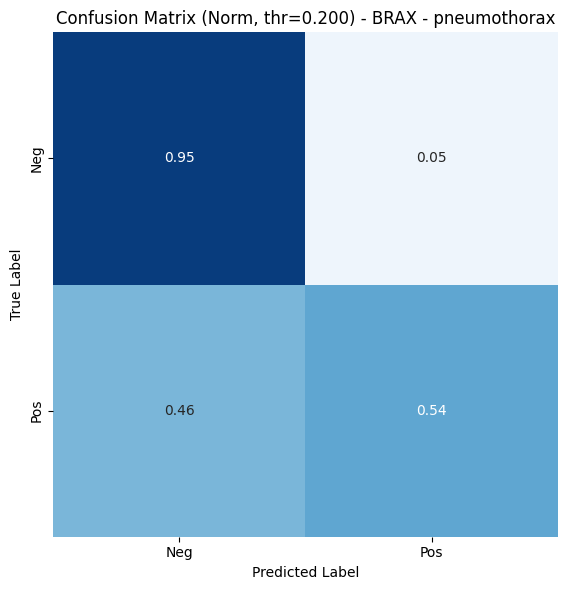

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_raw_pneumothorax.png


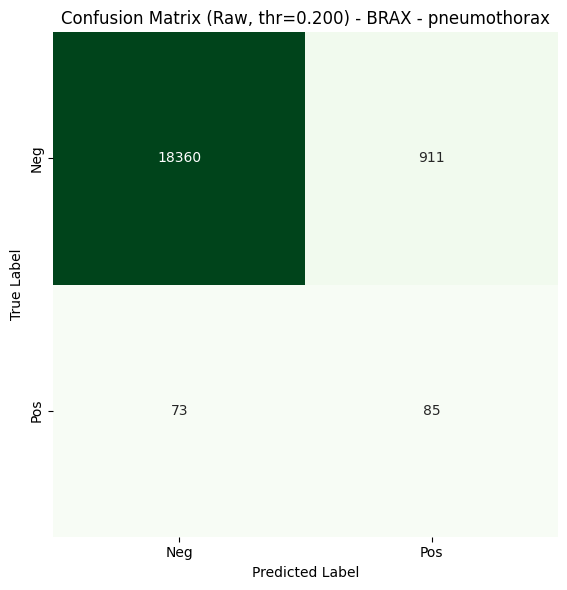

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_combined_pneumothorax.png


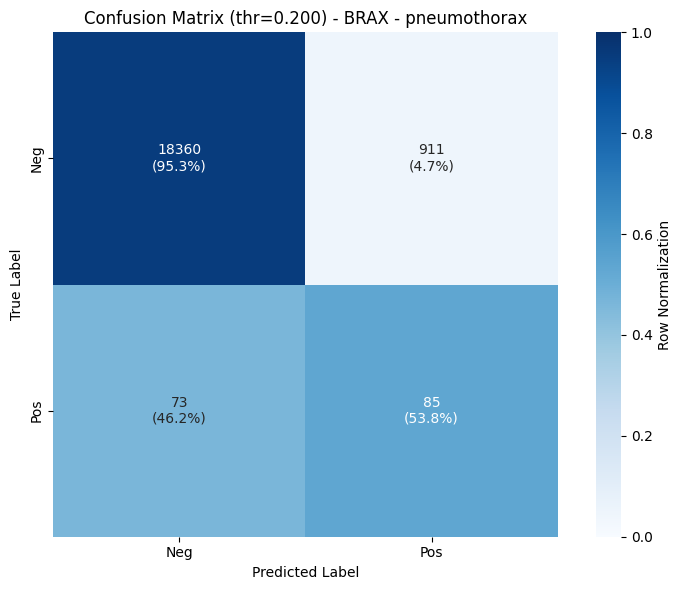

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_norm_support_devices.png


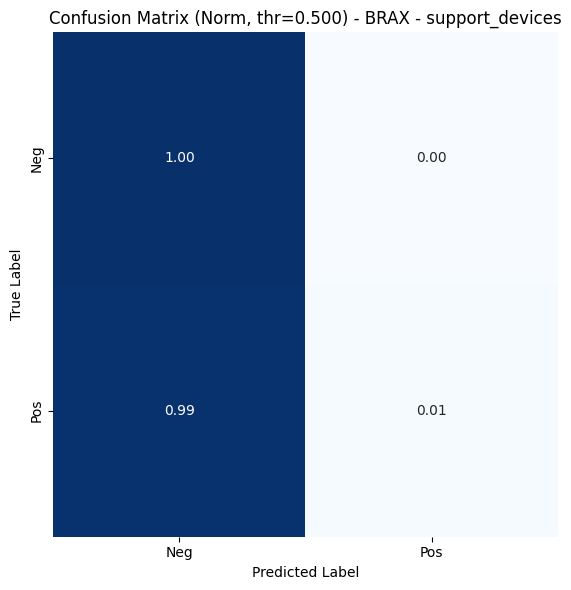

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_raw_support_devices.png


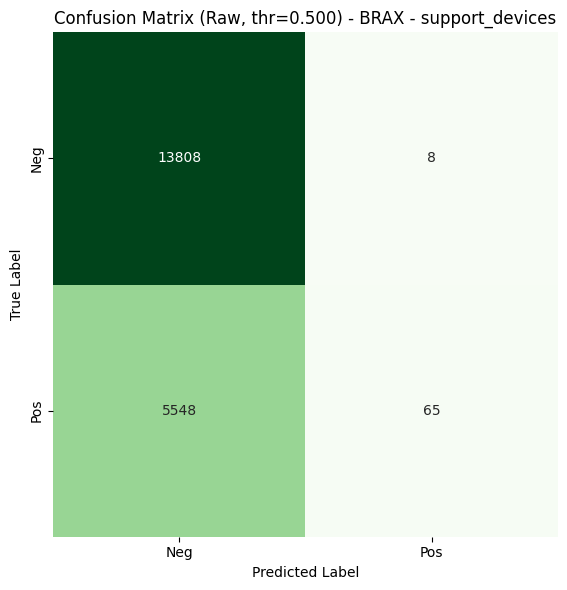

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_combined_support_devices.png


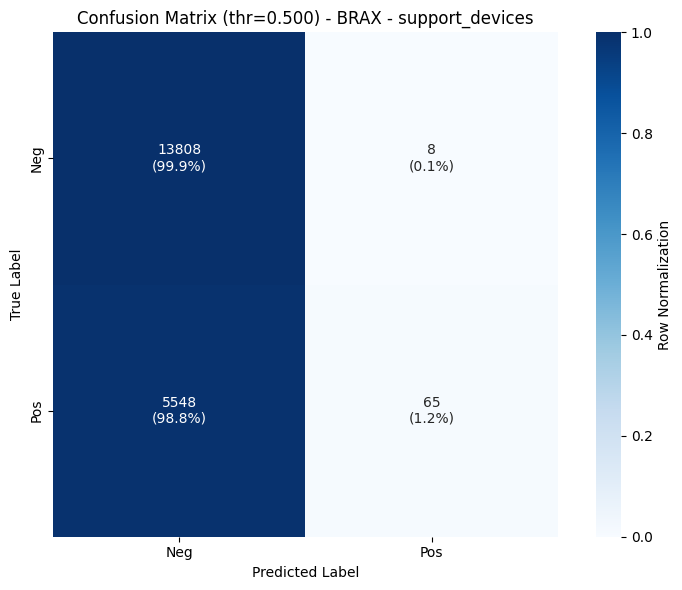

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_norm_no_finding.png


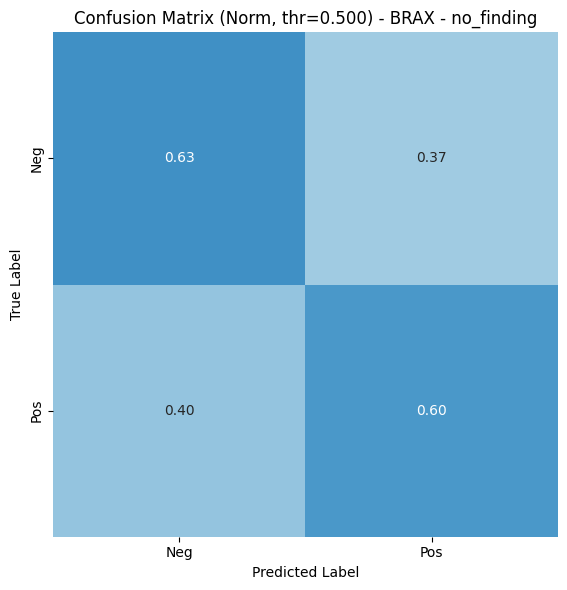

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_raw_no_finding.png


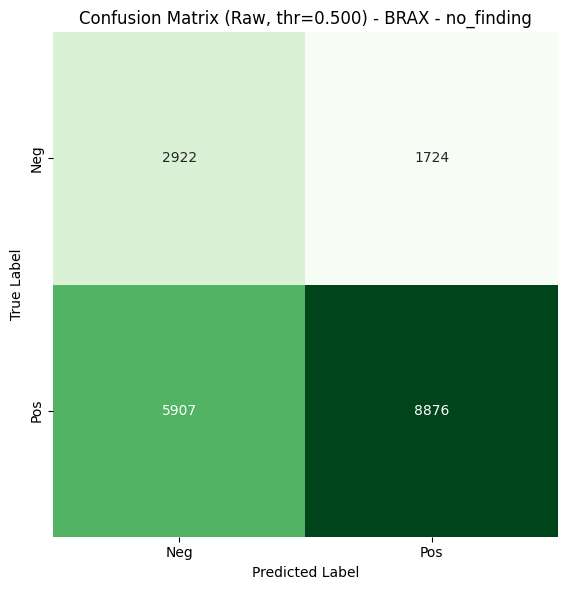

Saved plot: results/public_external_test/all/dataset_BRAX/confusion_matrix_combined_no_finding.png


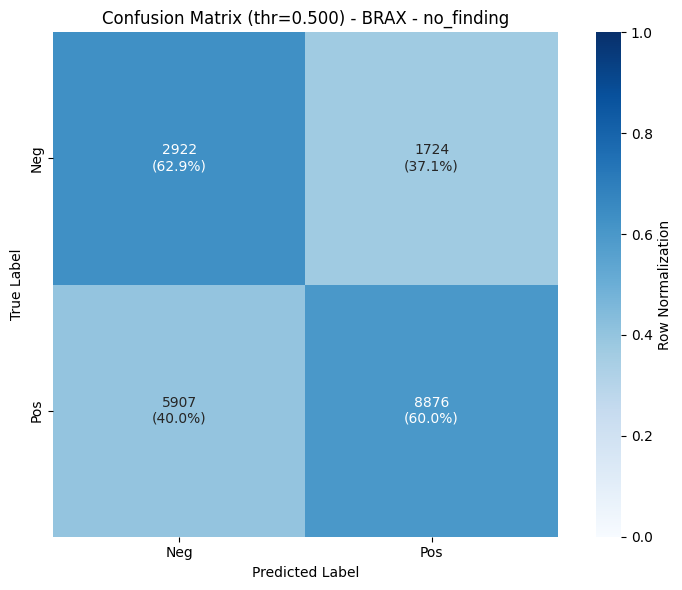

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/dataset_BRAX/threshold_sweep_pneumothorax.png


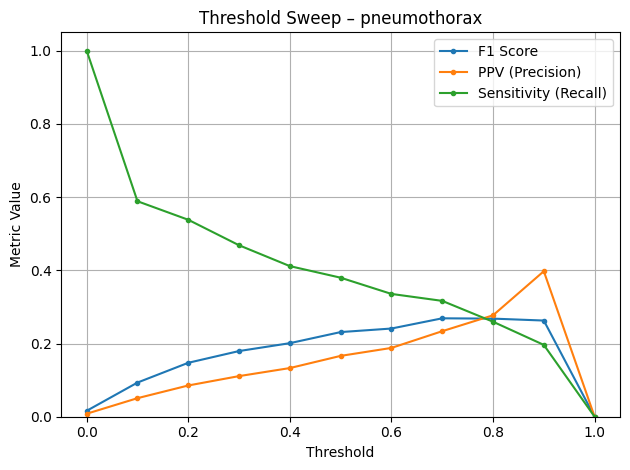

Saved plot: results/public_external_test/all/dataset_BRAX/threshold_sweep_support_devices.png


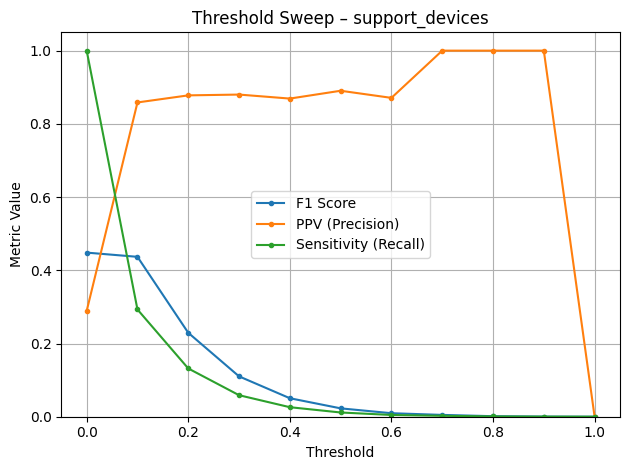

Saved plot: results/public_external_test/all/dataset_BRAX/threshold_sweep_no_finding.png


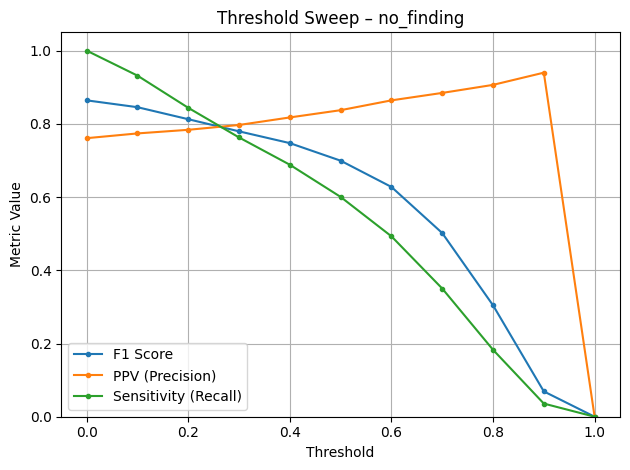

Saved threshold sweep table: results/public_external_test/all/dataset_BRAX/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/dataset_BRAX/label_cooccurrence_matrix.png


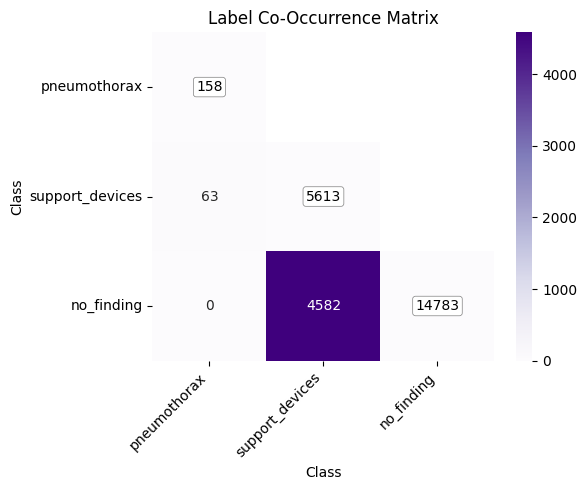


Plots for dataset: CANDID-PTX
📈 Plotting ROC Curves - CANDID-PTX...
Saved plot: results/public_external_test/all/dataset_CANDID-PTX/roc_curve_pneumothorax.png


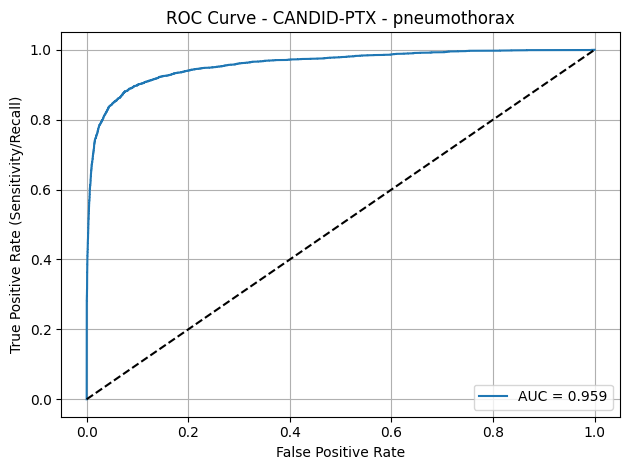

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/roc_curve_support_devices.png


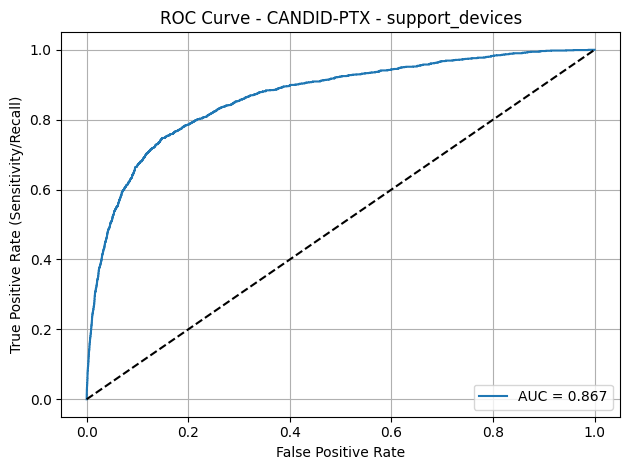

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/roc_curve_no_finding.png


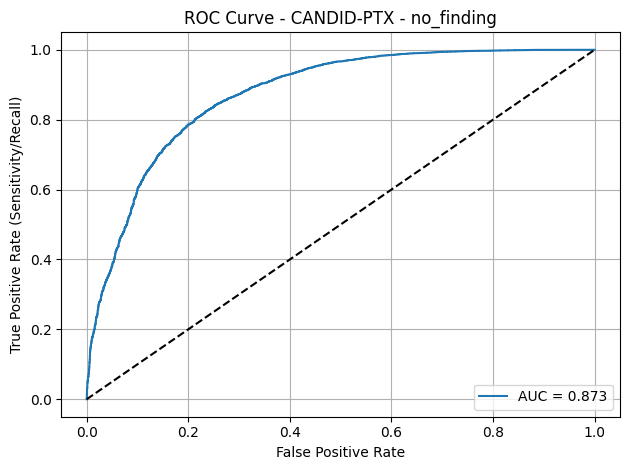

📈 Plotting Precision-Recall Curves - CANDID-PTX...
Saved plot: results/public_external_test/all/dataset_CANDID-PTX/pr_curve_pneumothorax.png


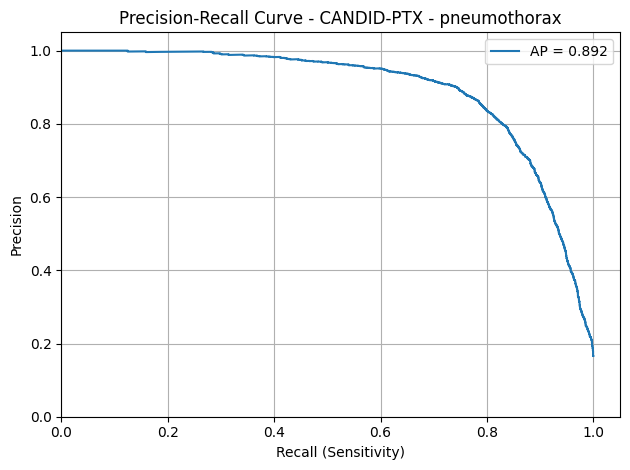

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/pr_curve_support_devices.png


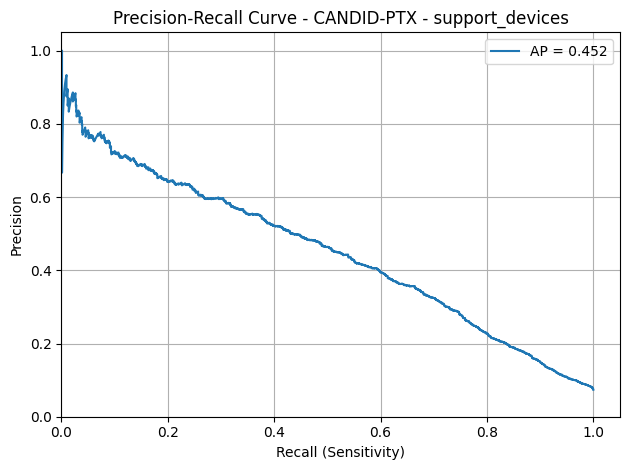

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/pr_curve_no_finding.png


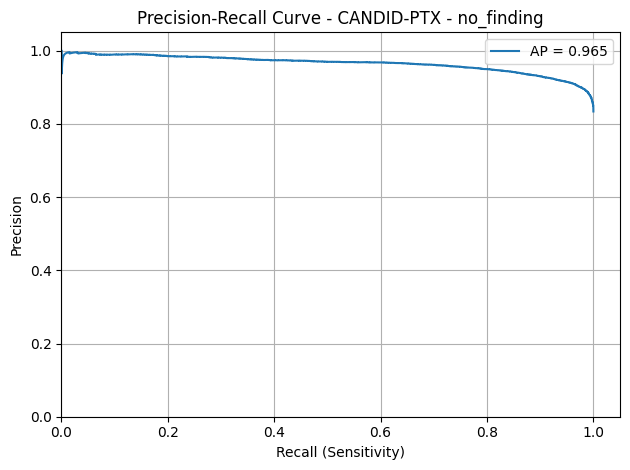

📊 Plotting Confusion Matrices - CANDID-PTX...
Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_norm_pneumothorax.png


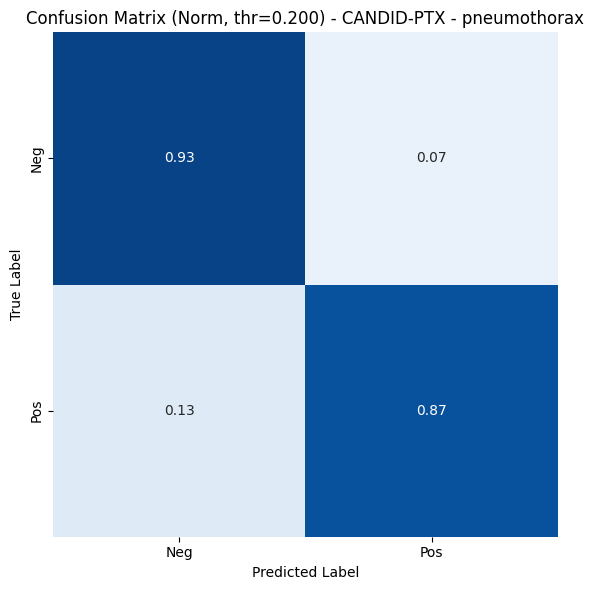

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_raw_pneumothorax.png


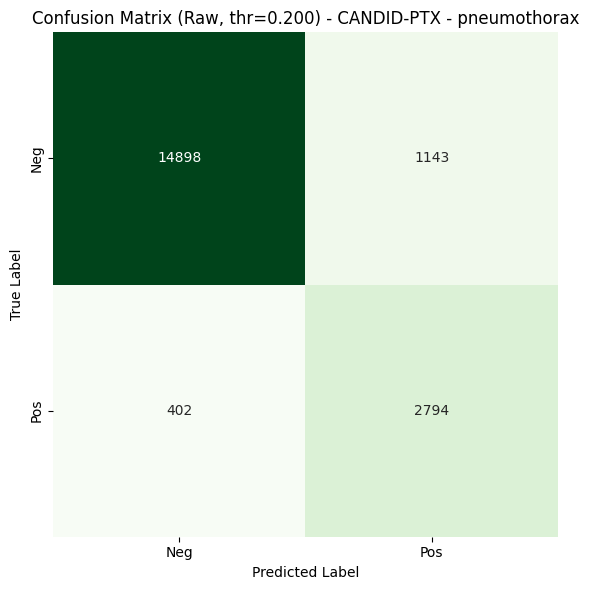

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_combined_pneumothorax.png


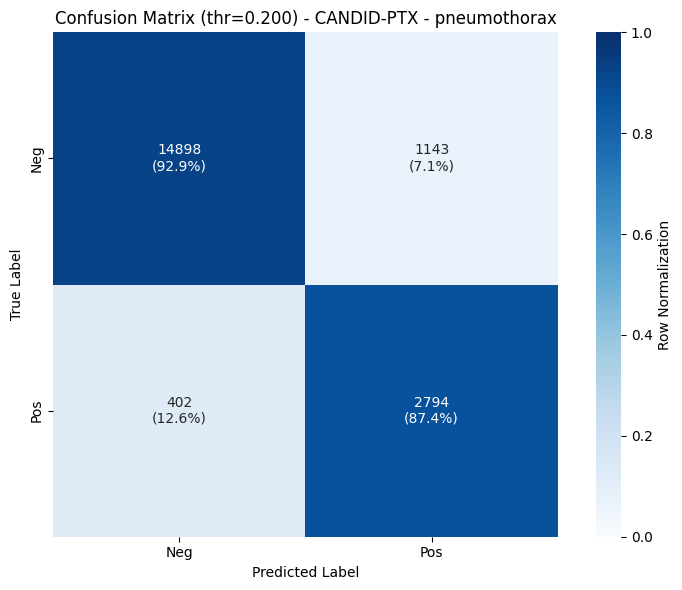

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_norm_support_devices.png


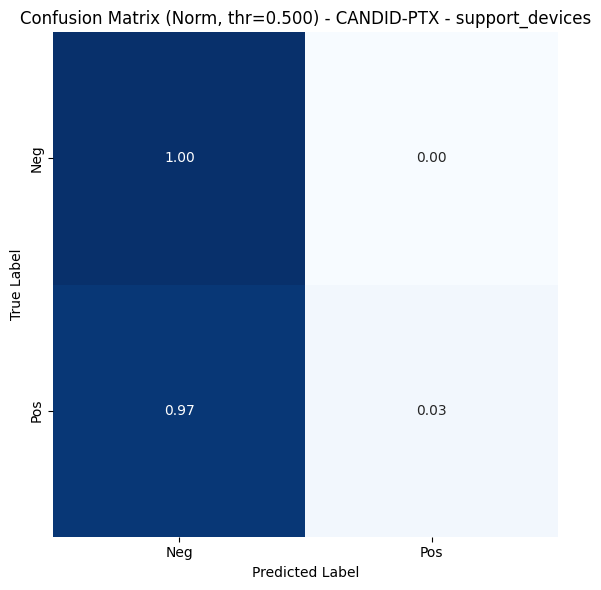

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_raw_support_devices.png


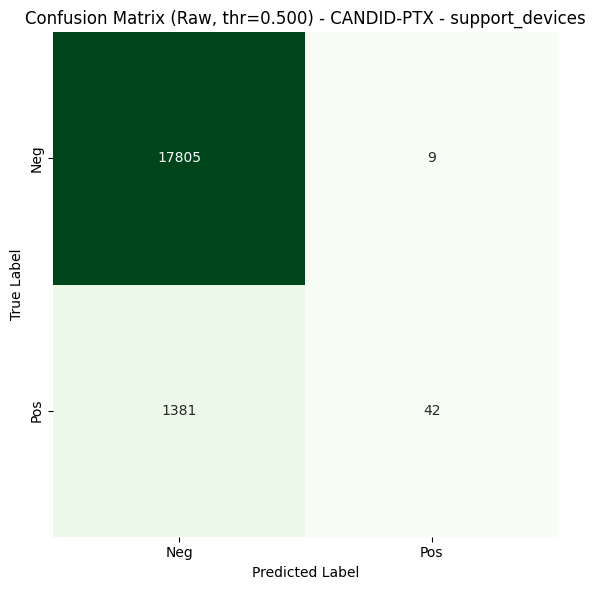

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_combined_support_devices.png


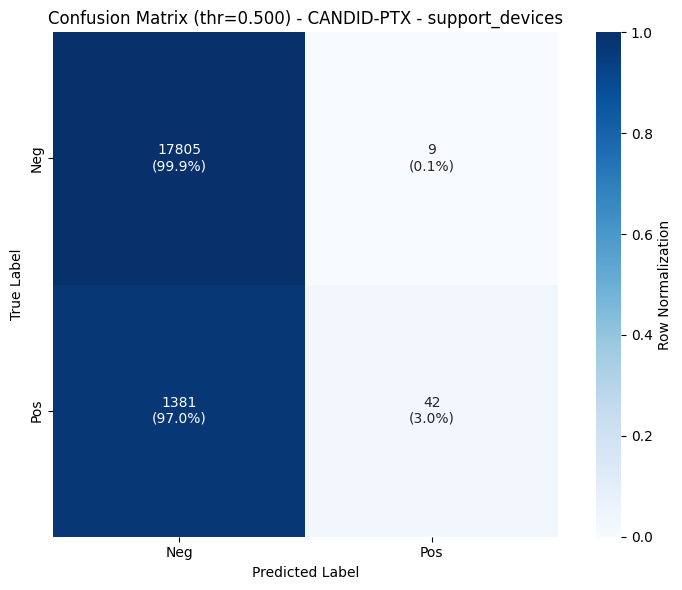

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_norm_no_finding.png


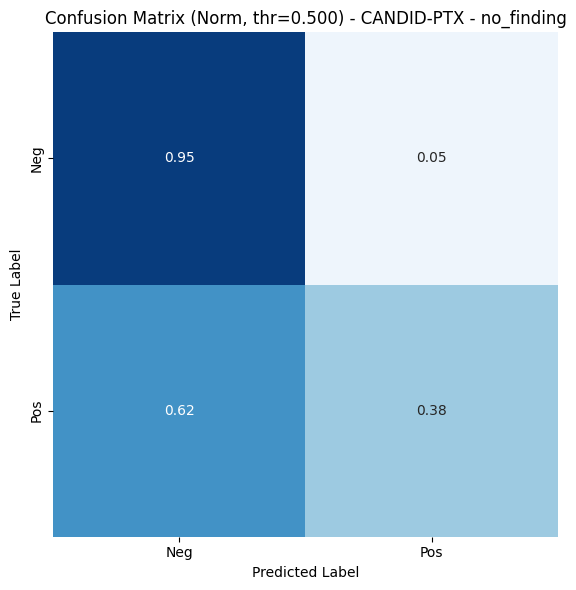

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_raw_no_finding.png


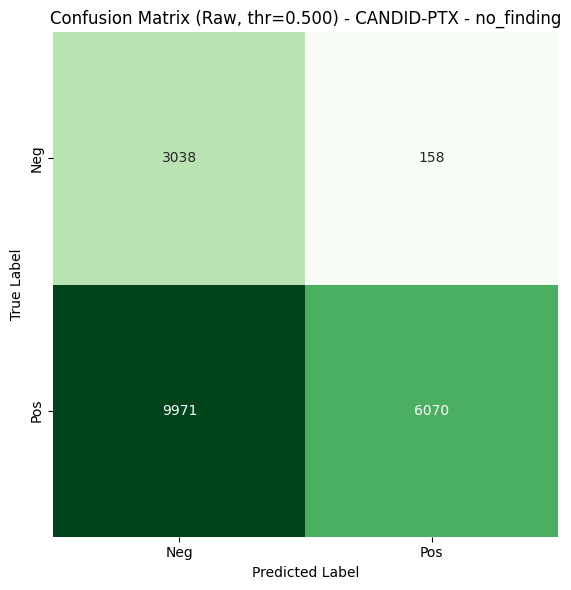

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/confusion_matrix_combined_no_finding.png


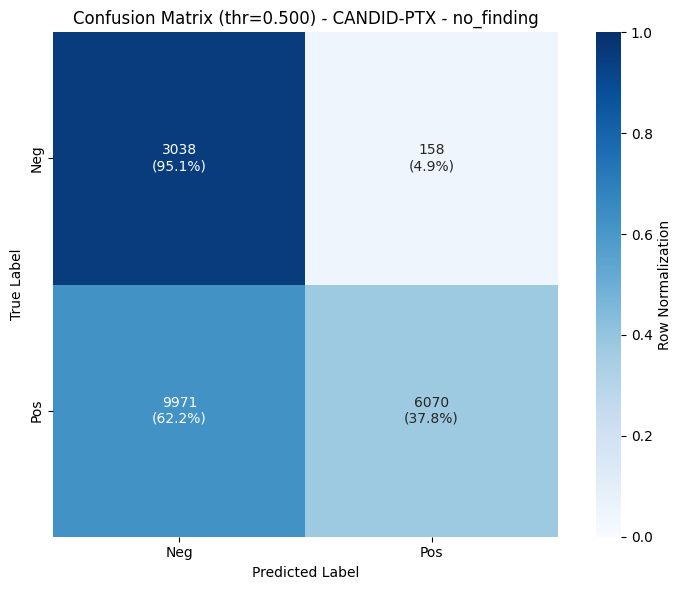

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/dataset_CANDID-PTX/threshold_sweep_pneumothorax.png


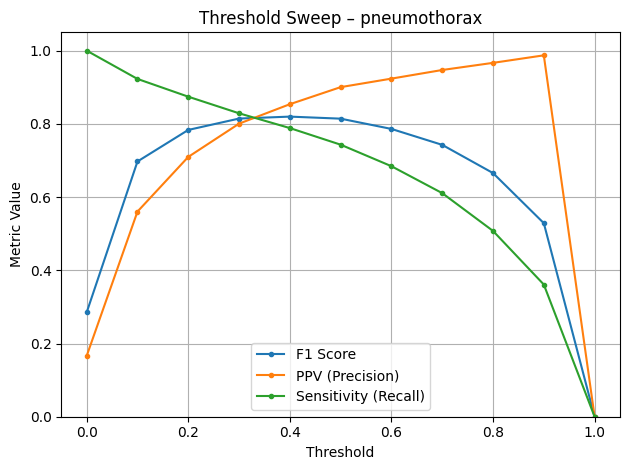

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/threshold_sweep_support_devices.png


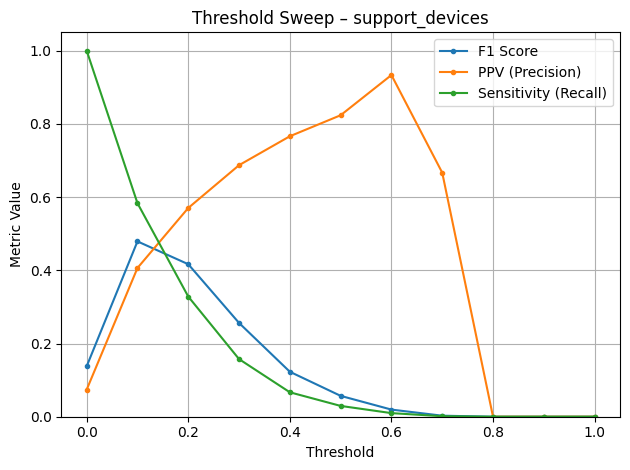

Saved plot: results/public_external_test/all/dataset_CANDID-PTX/threshold_sweep_no_finding.png


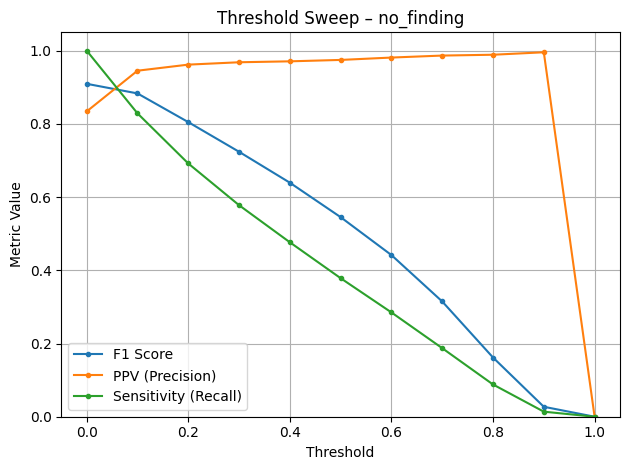

Saved threshold sweep table: results/public_external_test/all/dataset_CANDID-PTX/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/dataset_CANDID-PTX/label_cooccurrence_matrix.png


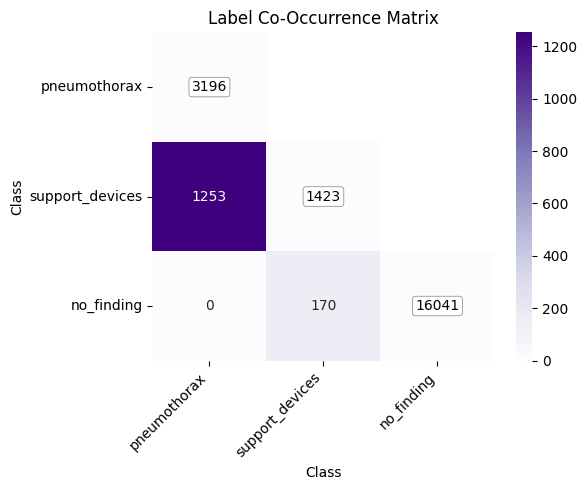


Plots for dataset: CRADI
📈 Plotting ROC Curves - CRADI...
Saved plot: results/public_external_test/all/dataset_CRADI/roc_curve_pneumothorax.png


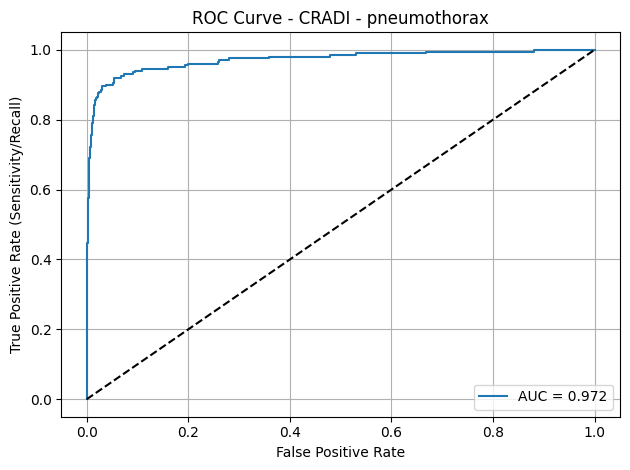

Saved plot: results/public_external_test/all/dataset_CRADI/roc_curve_support_devices.png


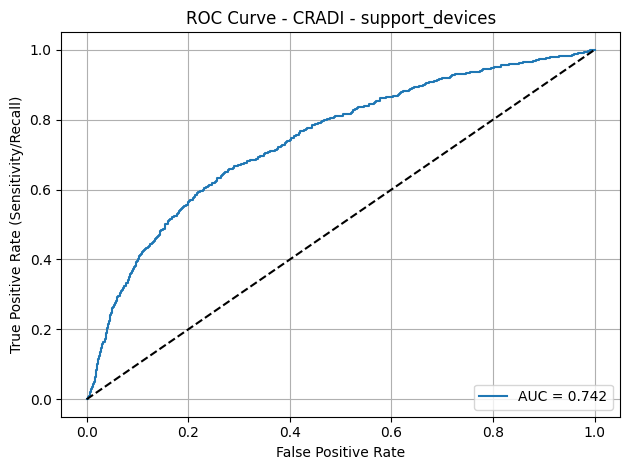

Saved plot: results/public_external_test/all/dataset_CRADI/roc_curve_no_finding.png


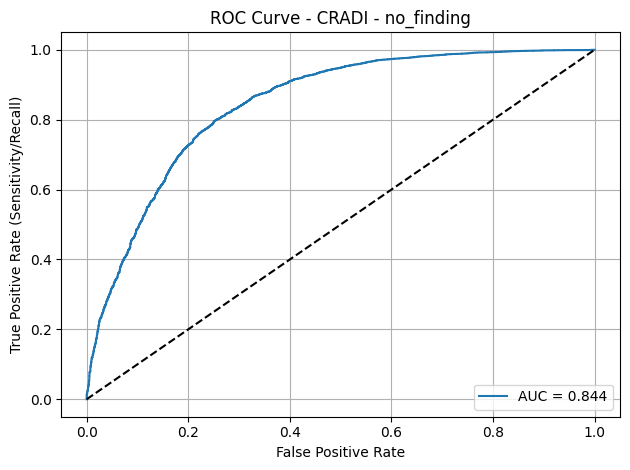

📈 Plotting Precision-Recall Curves - CRADI...
Saved plot: results/public_external_test/all/dataset_CRADI/pr_curve_pneumothorax.png


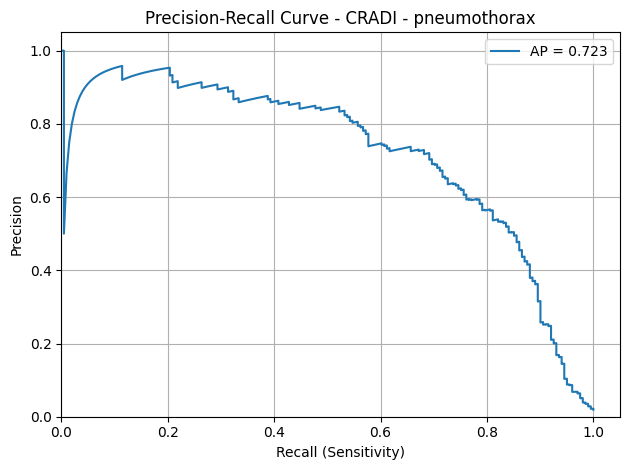

Saved plot: results/public_external_test/all/dataset_CRADI/pr_curve_support_devices.png


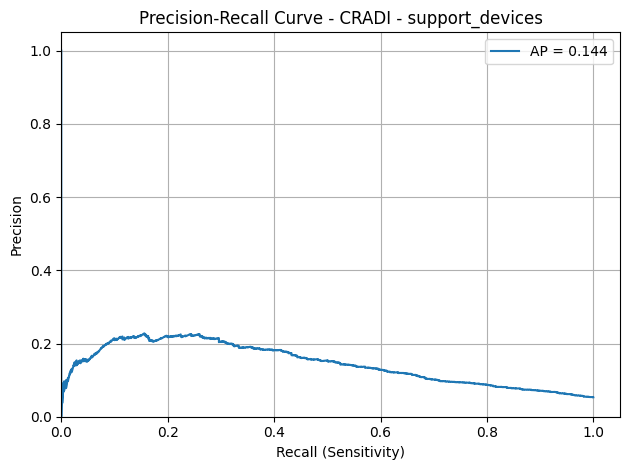

Saved plot: results/public_external_test/all/dataset_CRADI/pr_curve_no_finding.png


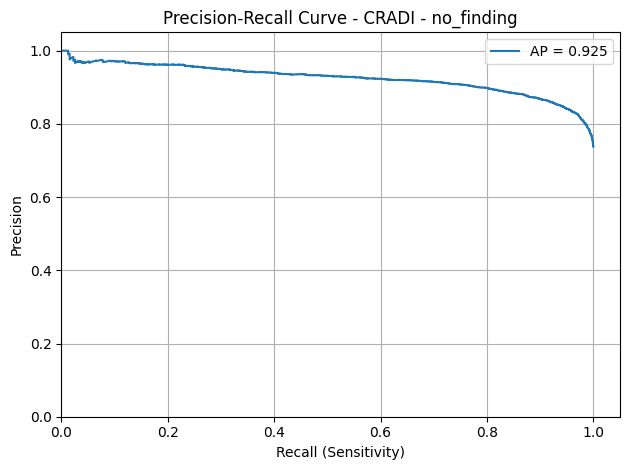

📊 Plotting Confusion Matrices - CRADI...
Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_norm_pneumothorax.png


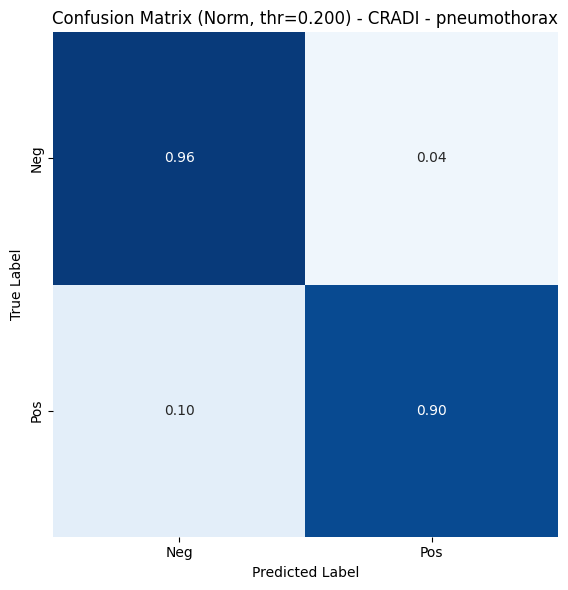

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_raw_pneumothorax.png


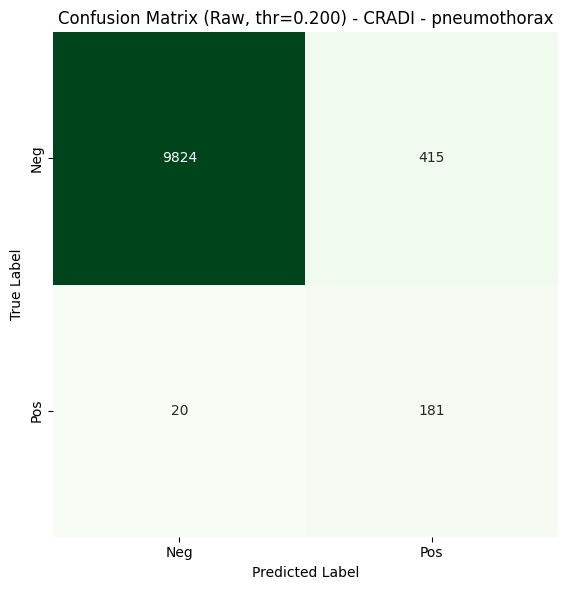

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_combined_pneumothorax.png


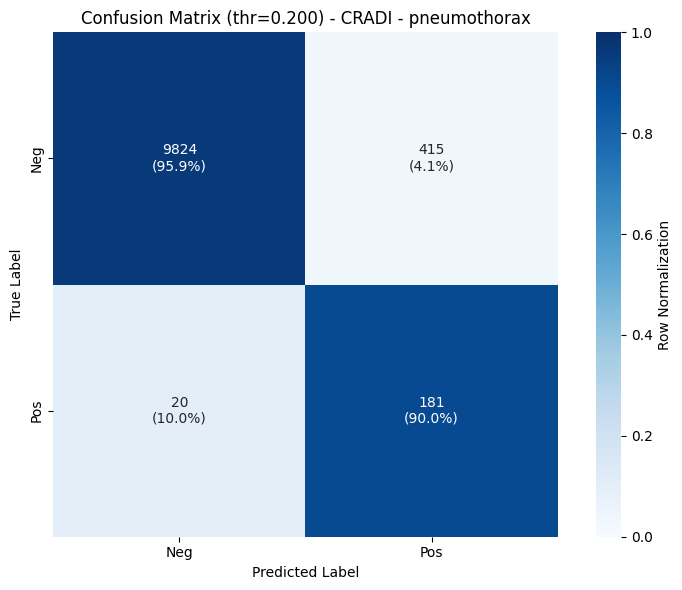

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_norm_support_devices.png


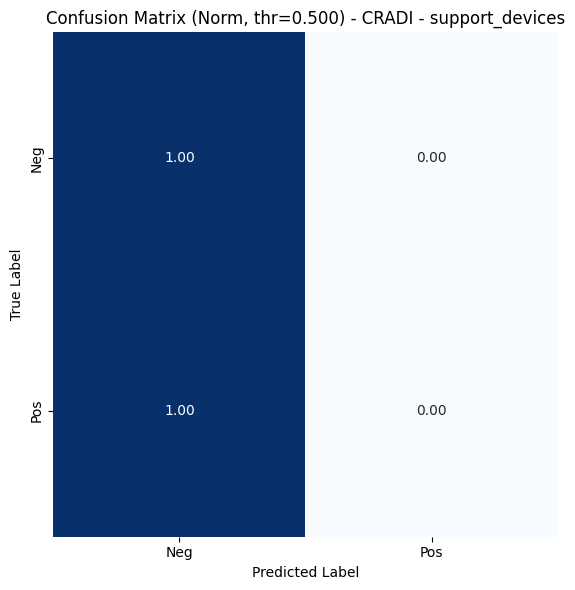

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_raw_support_devices.png


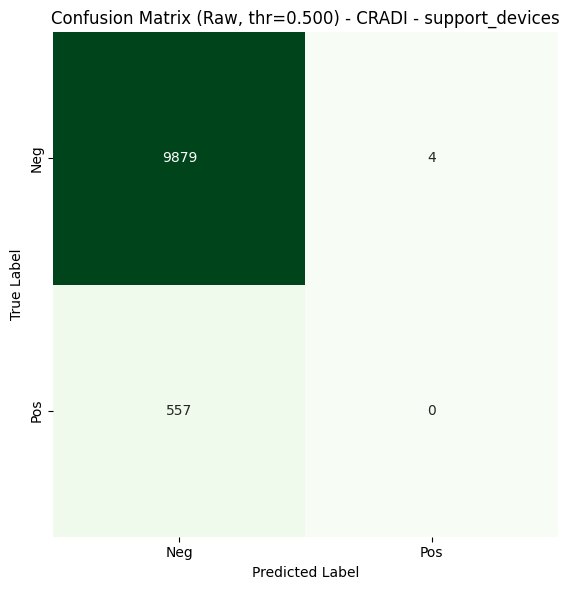

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_combined_support_devices.png


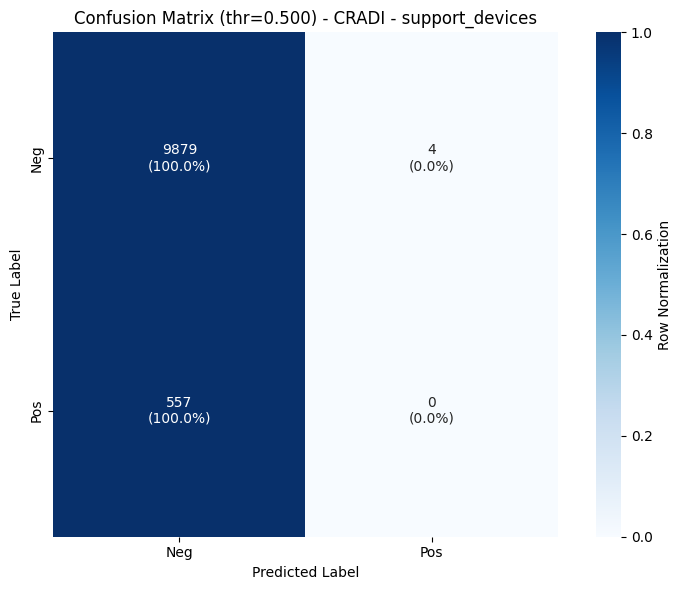

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_norm_no_finding.png


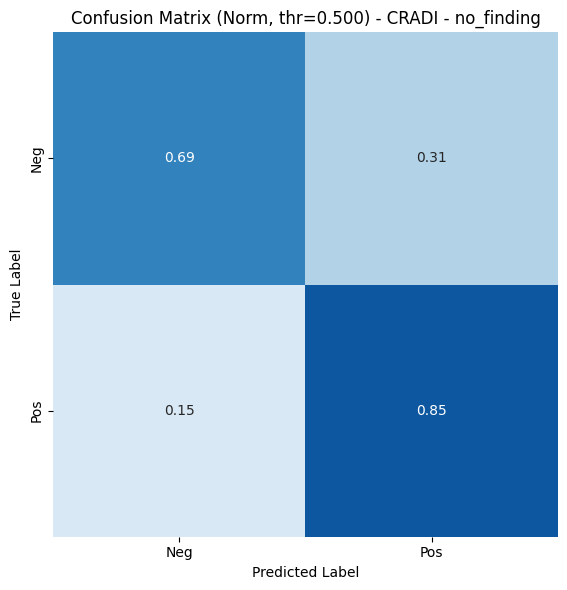

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_raw_no_finding.png


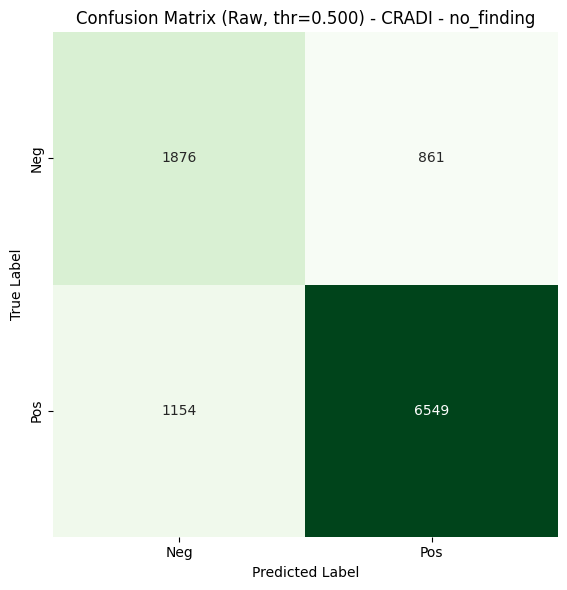

Saved plot: results/public_external_test/all/dataset_CRADI/confusion_matrix_combined_no_finding.png


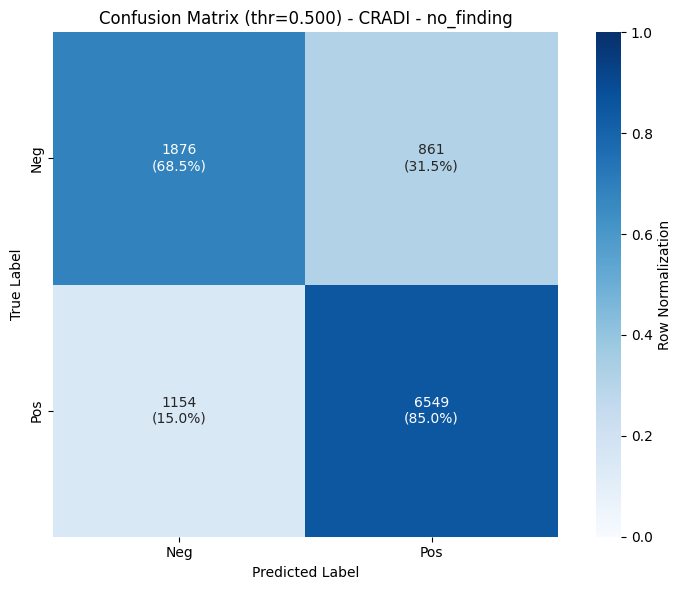

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/dataset_CRADI/threshold_sweep_pneumothorax.png


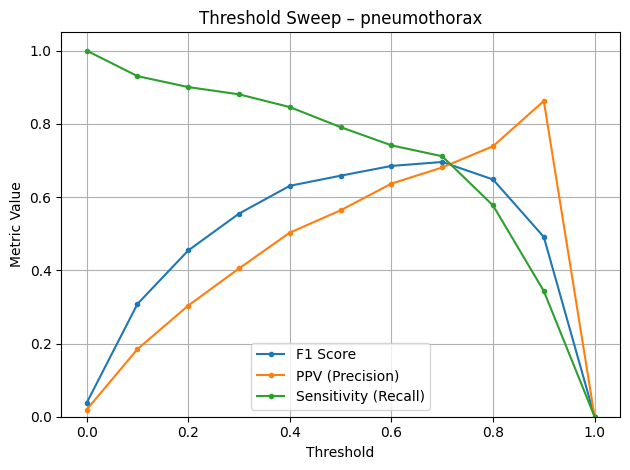

Saved plot: results/public_external_test/all/dataset_CRADI/threshold_sweep_support_devices.png


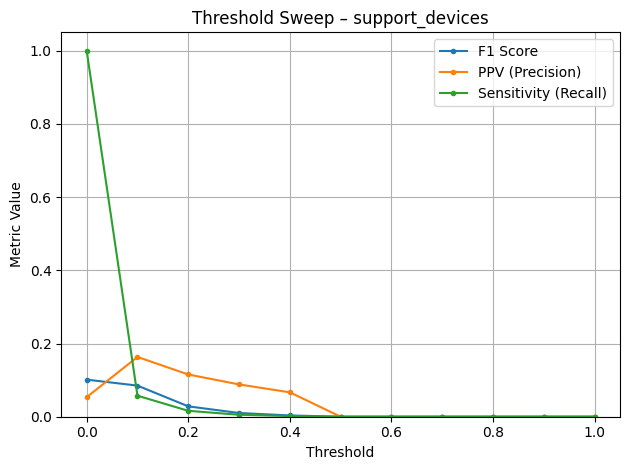

Saved plot: results/public_external_test/all/dataset_CRADI/threshold_sweep_no_finding.png


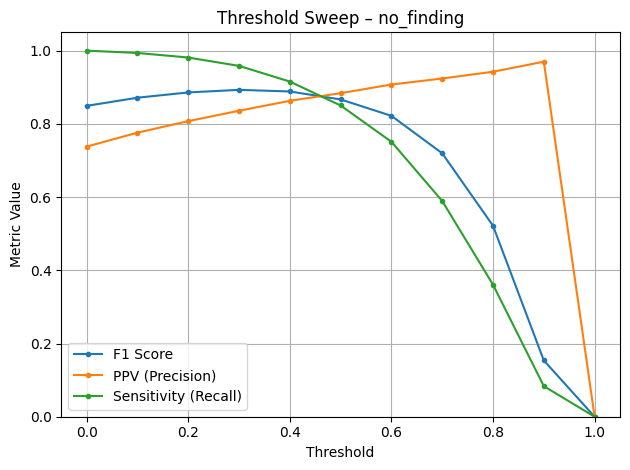

Saved threshold sweep table: results/public_external_test/all/dataset_CRADI/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/dataset_CRADI/label_cooccurrence_matrix.png


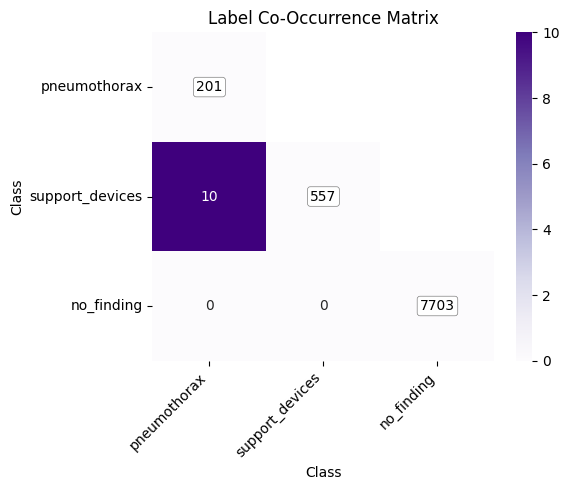


Plots for dataset: Indiana
📈 Plotting ROC Curves - Indiana...
Saved plot: results/public_external_test/all/dataset_Indiana/roc_curve_pneumothorax.png


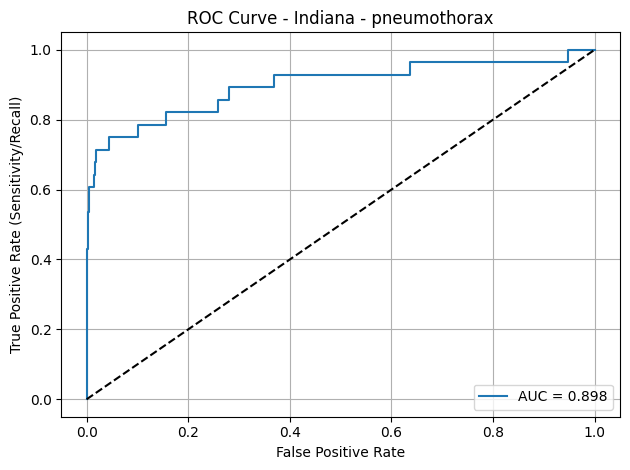

📈 Plotting Precision-Recall Curves - Indiana...
Saved plot: results/public_external_test/all/dataset_Indiana/pr_curve_pneumothorax.png


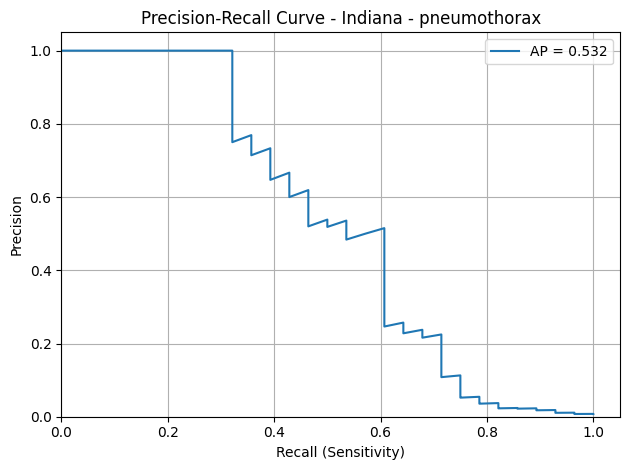

📊 Plotting Confusion Matrices - Indiana...
Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_norm_pneumothorax.png


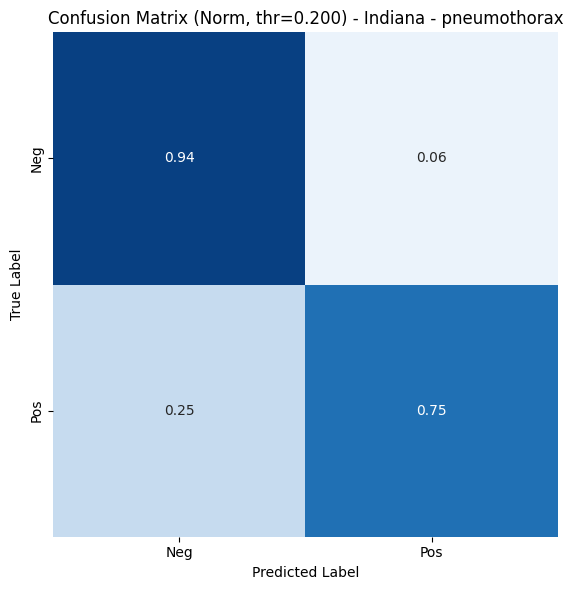

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_raw_pneumothorax.png


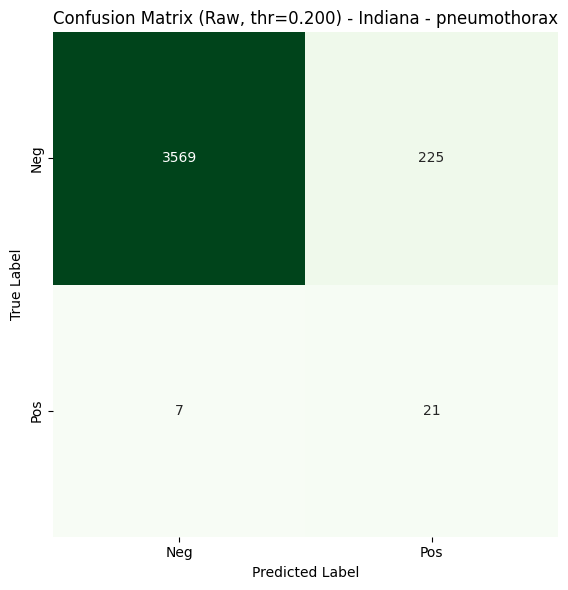

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_combined_pneumothorax.png


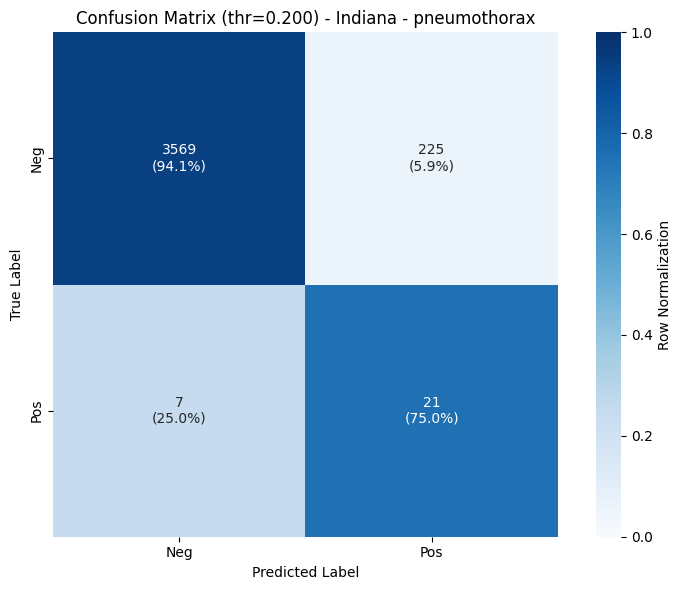

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_norm_support_devices.png


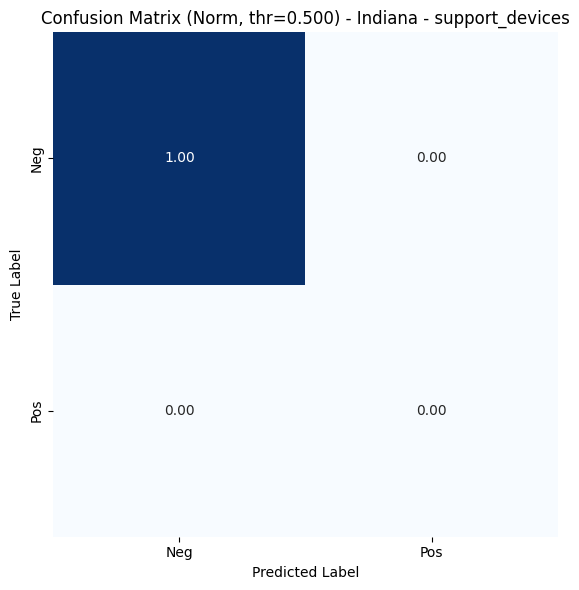

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_raw_support_devices.png


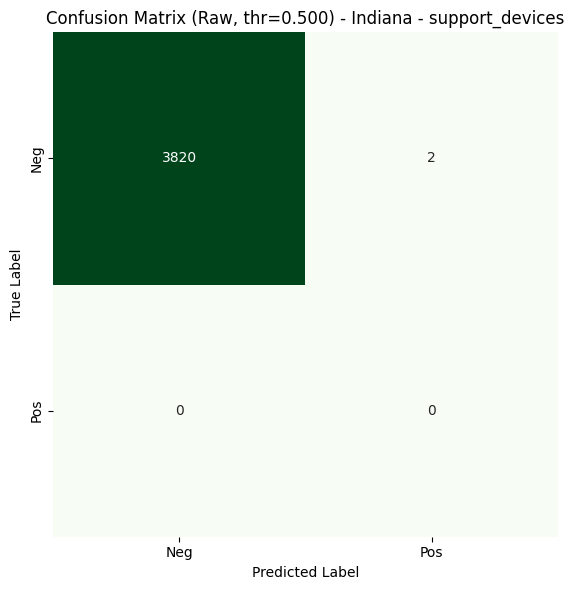

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_combined_support_devices.png


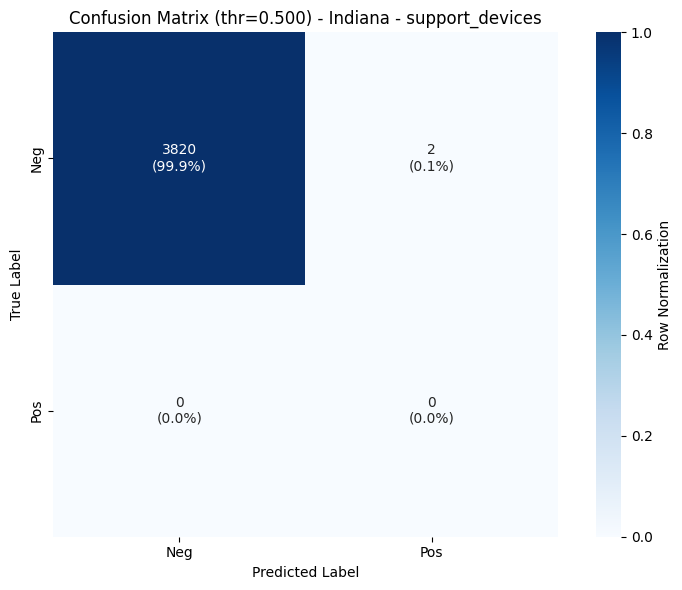

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_norm_no_finding.png


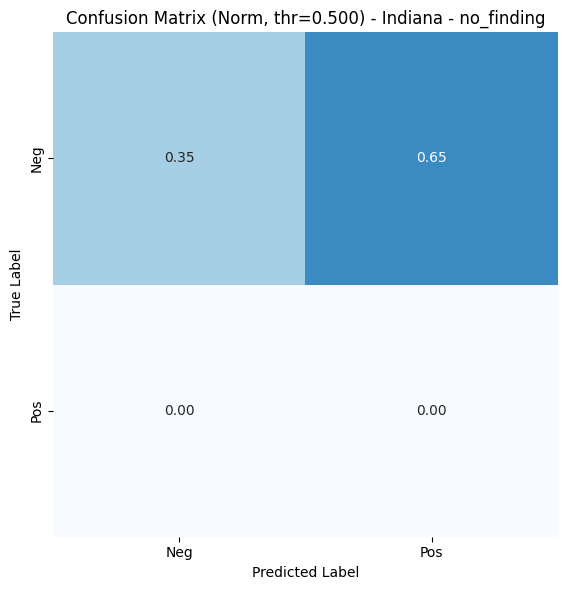

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_raw_no_finding.png


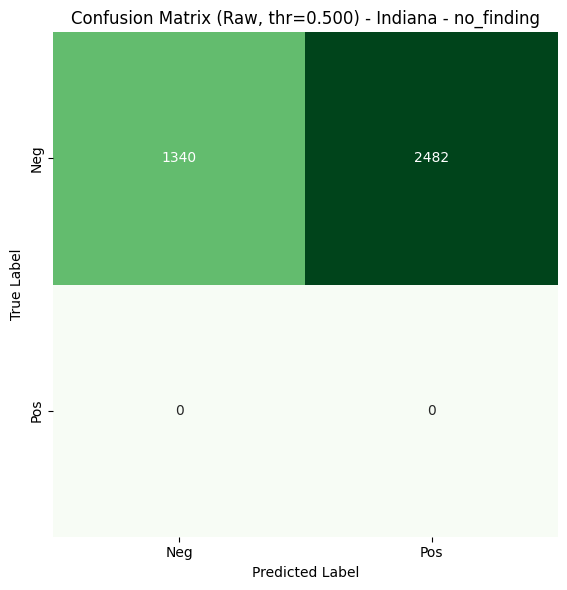

Saved plot: results/public_external_test/all/dataset_Indiana/confusion_matrix_combined_no_finding.png


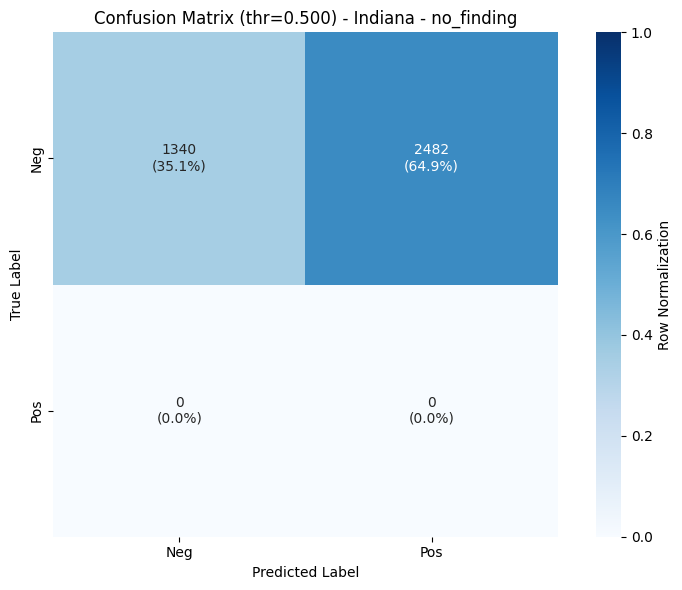

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/dataset_Indiana/threshold_sweep_pneumothorax.png


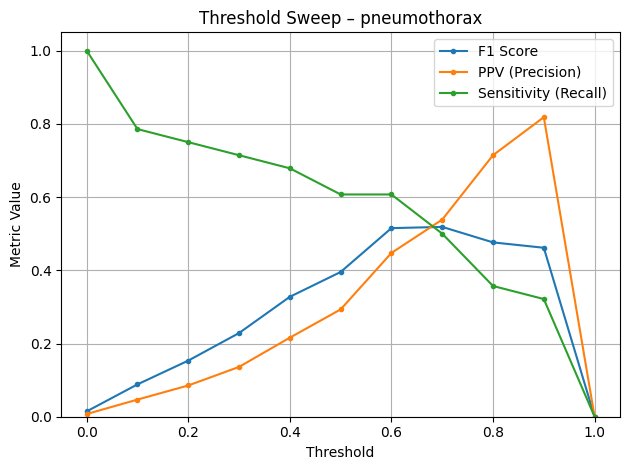

Saved plot: results/public_external_test/all/dataset_Indiana/threshold_sweep_support_devices.png


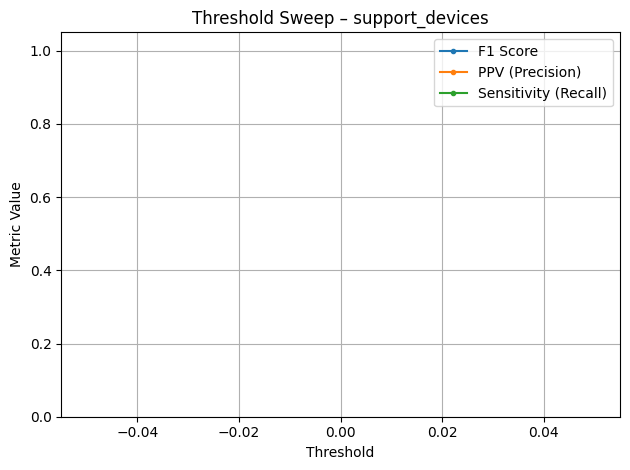

Saved plot: results/public_external_test/all/dataset_Indiana/threshold_sweep_no_finding.png


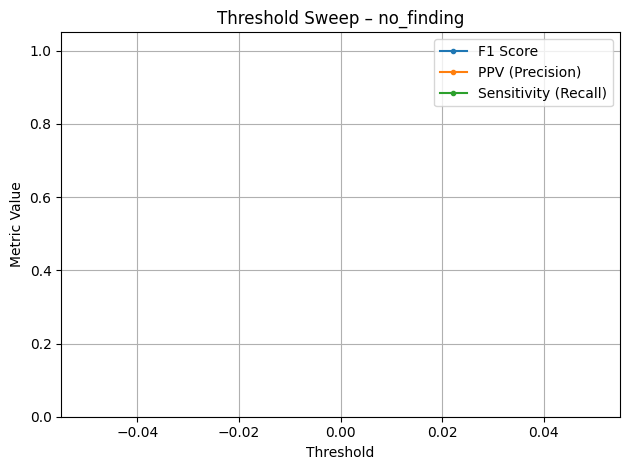

Saved threshold sweep table: results/public_external_test/all/dataset_Indiana/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/dataset_Indiana/label_cooccurrence_matrix.png


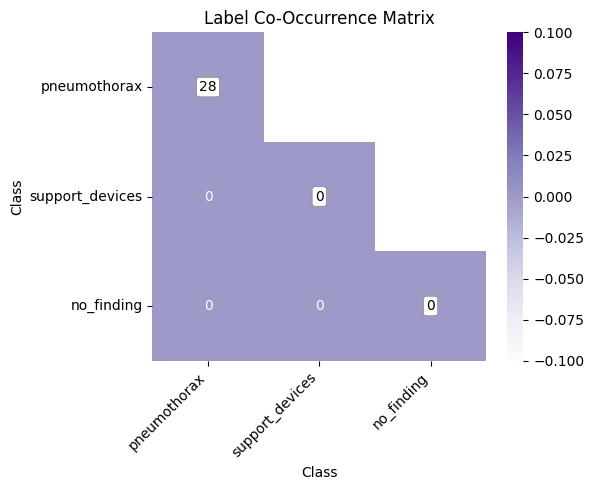


Plots for dataset: PTX498
📈 Plotting ROC Curves - PTX498...
📈 Plotting Precision-Recall Curves - PTX498...
📊 Plotting Confusion Matrices - PTX498...
Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_norm_pneumothorax.png


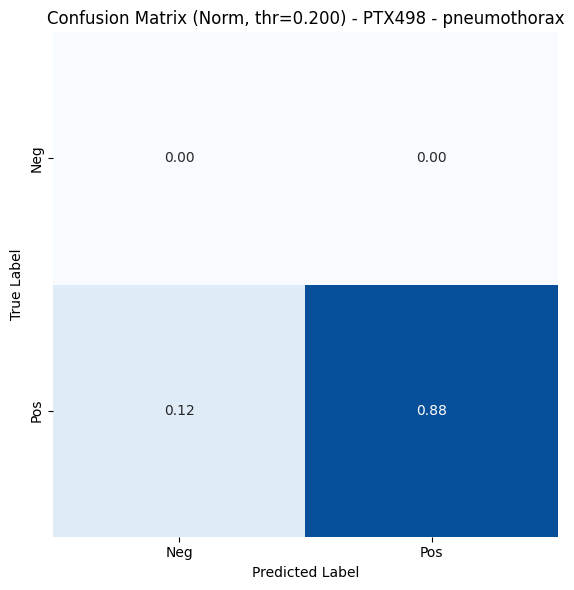

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_raw_pneumothorax.png


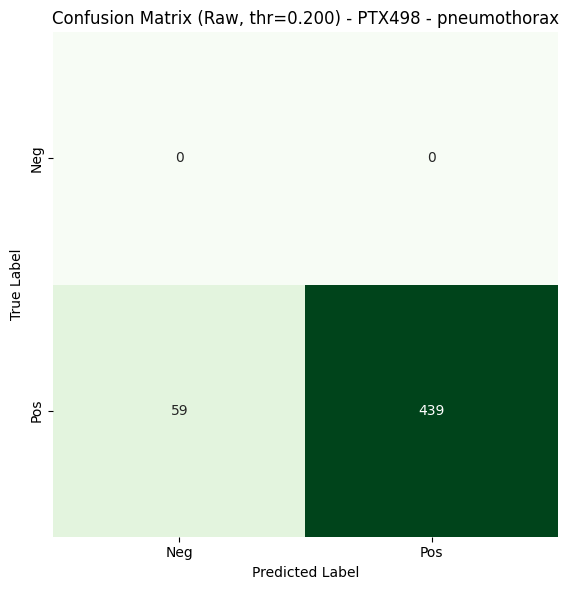

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_combined_pneumothorax.png


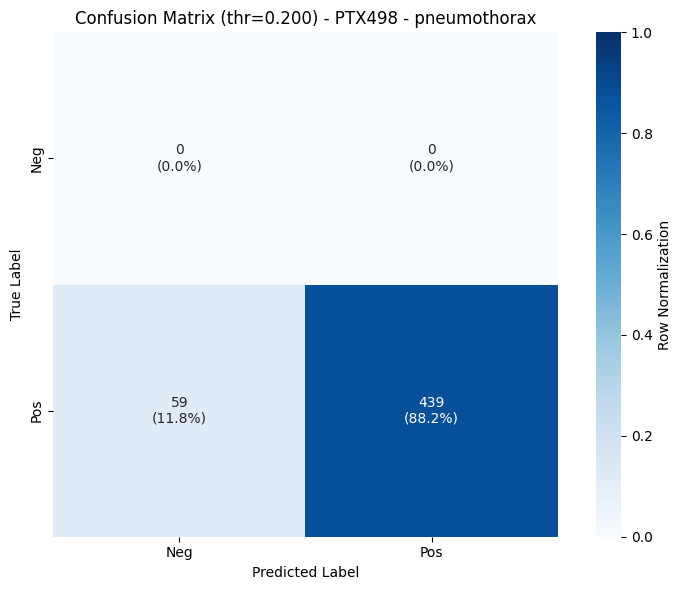

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_norm_support_devices.png


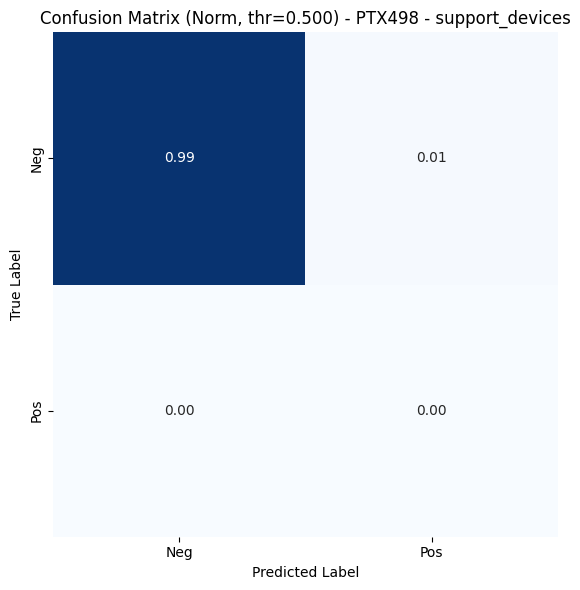

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_raw_support_devices.png


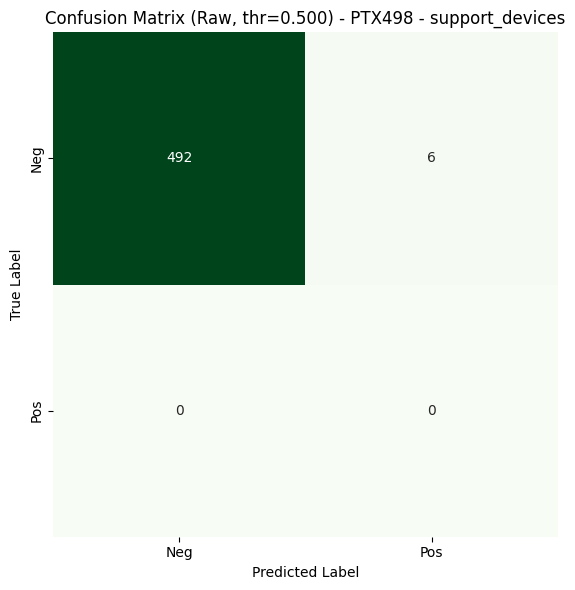

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_combined_support_devices.png


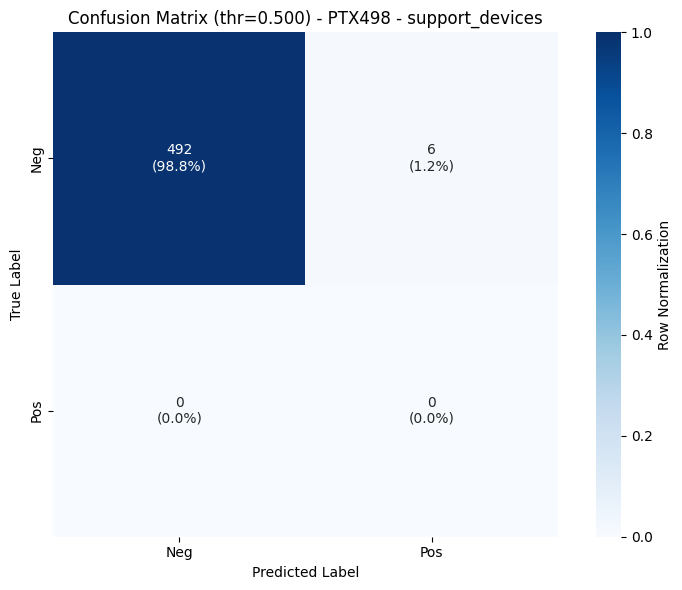

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_norm_no_finding.png


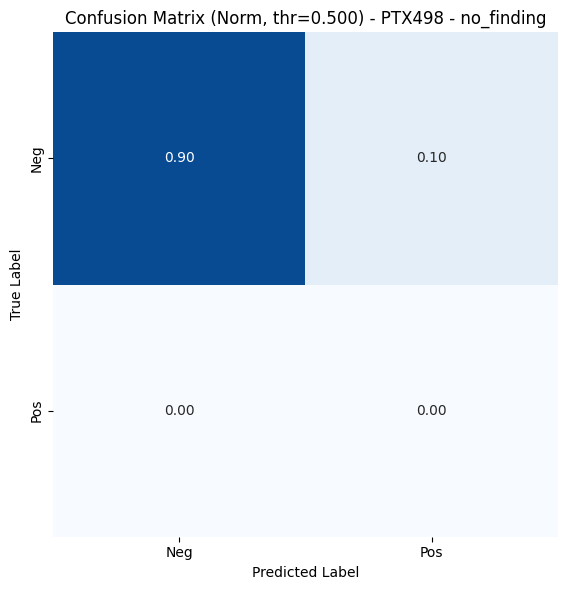

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_raw_no_finding.png


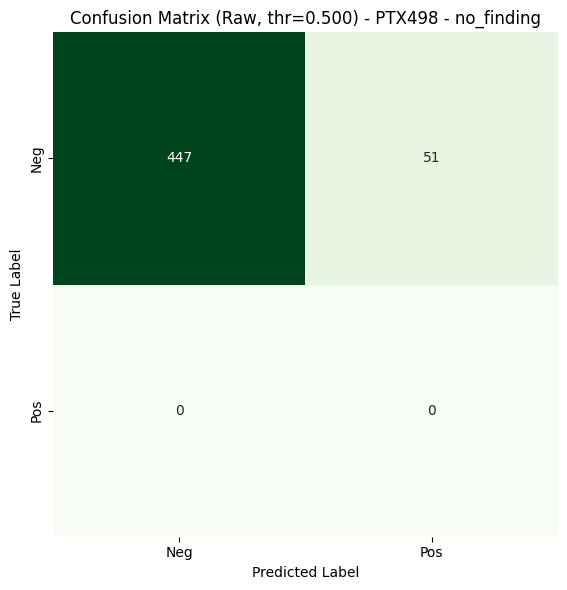

Saved plot: results/public_external_test/all/dataset_PTX498/confusion_matrix_combined_no_finding.png


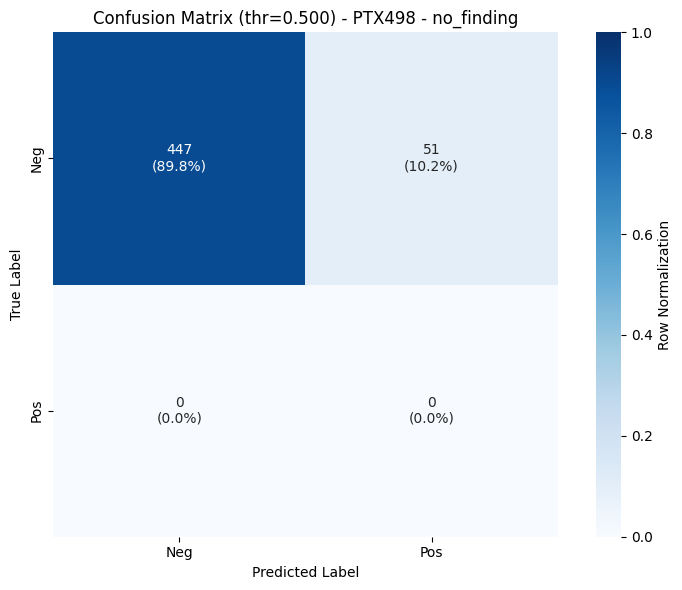

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/public_external_test/all/dataset_PTX498/threshold_sweep_pneumothorax.png


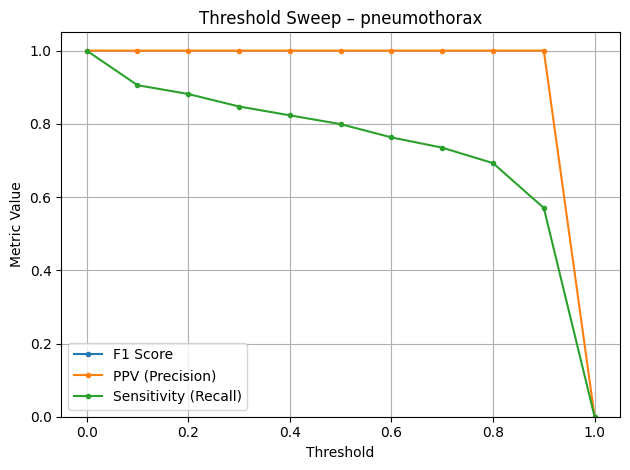

Saved plot: results/public_external_test/all/dataset_PTX498/threshold_sweep_support_devices.png


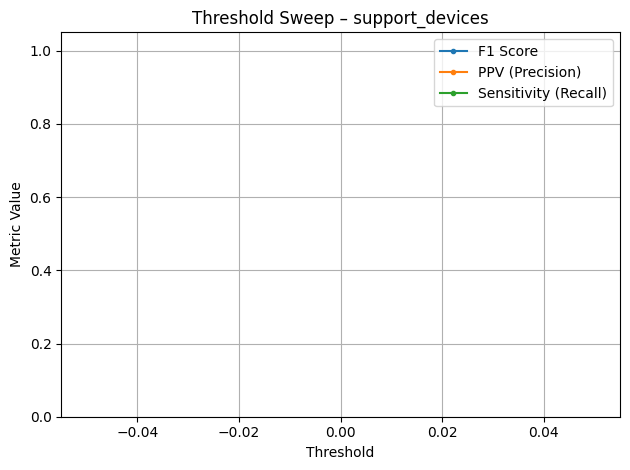

Saved plot: results/public_external_test/all/dataset_PTX498/threshold_sweep_no_finding.png


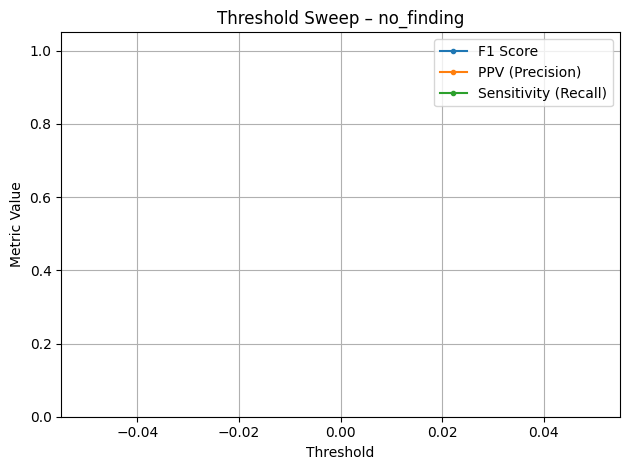

Saved threshold sweep table: results/public_external_test/all/dataset_PTX498/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/public_external_test/all/dataset_PTX498/label_cooccurrence_matrix.png


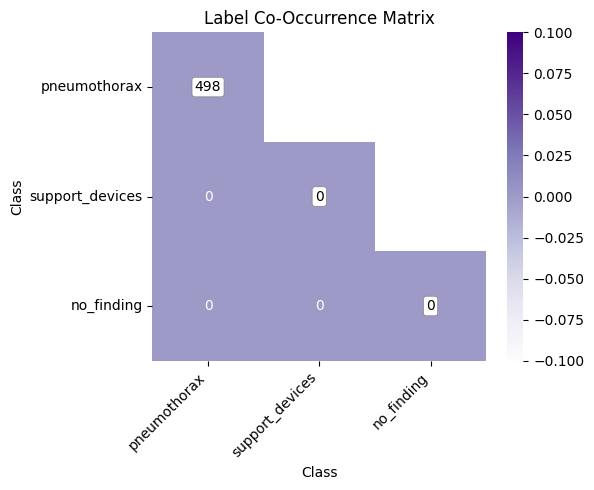


Generating combined dataset plots...
📈 Plotting Combined ROC Curves...
Saved plot: results/public_external_test/all/combined_roc_curve_pneumothorax.png


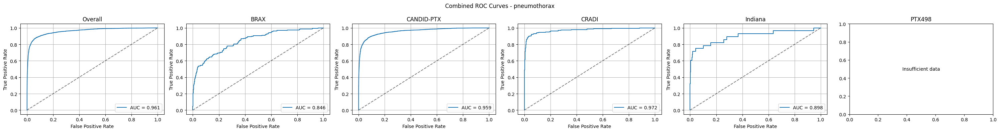

Saved plot: results/public_external_test/all/combined_roc_curve_support_devices.png


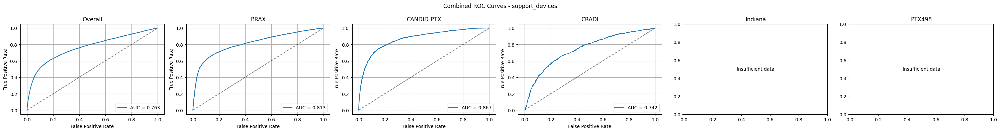

Saved plot: results/public_external_test/all/combined_roc_curve_no_finding.png


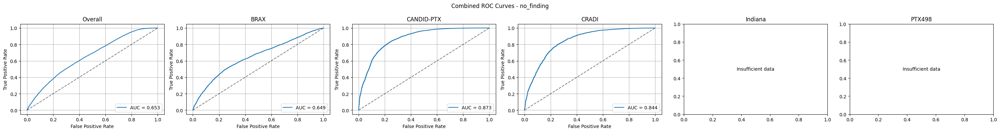

📈 Plotting Combined PR Curves...
Saved plot: results/public_external_test/all/combined_pr_curve_pneumothorax.png


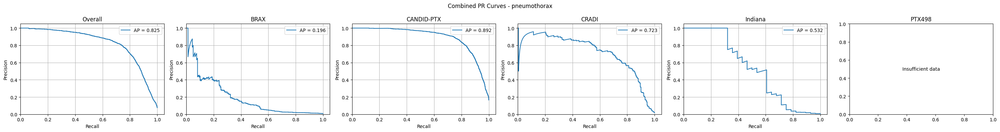

Saved plot: results/public_external_test/all/combined_pr_curve_support_devices.png


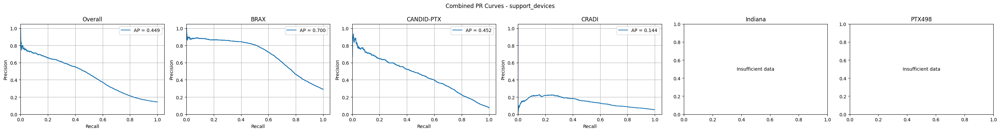

Saved plot: results/public_external_test/all/combined_pr_curve_no_finding.png


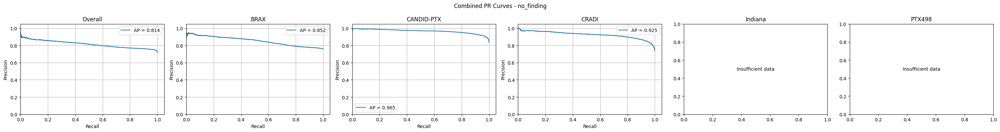

📊 Plotting Combined Confusion Matrices...
Saved plot: results/public_external_test/all/combined_confusion_matrix_pneumothorax.png


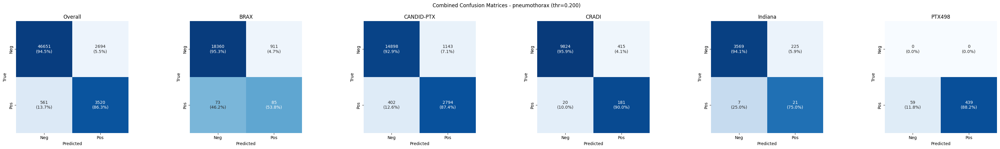

Saved plot: results/public_external_test/all/combined_confusion_matrix_support_devices.png


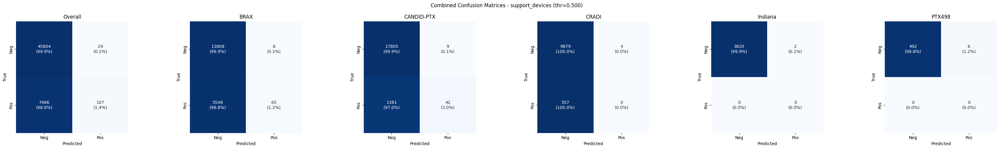

Saved plot: results/public_external_test/all/combined_confusion_matrix_no_finding.png


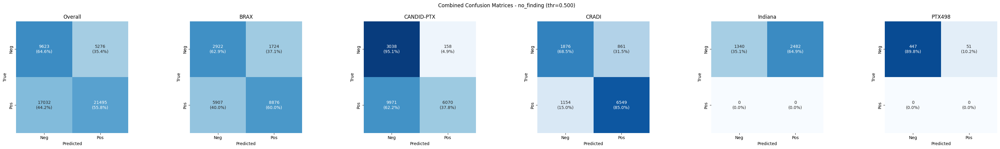


Generating single plots with all datasets...
📈 Plotting Single ROC Curves (All Datasets)...
Saved plot: results/public_external_test/all/single_roc_curve_pneumothorax.png


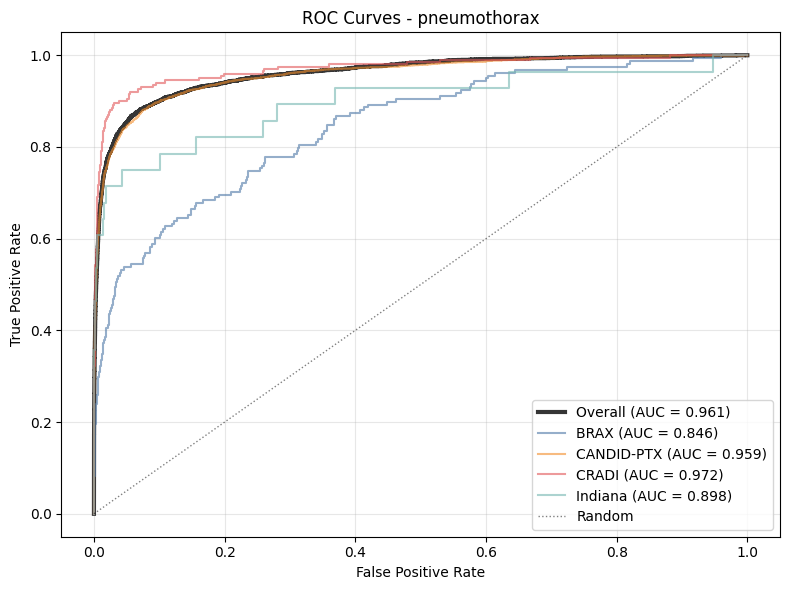

Saved plot: results/public_external_test/all/single_roc_curve_support_devices.png


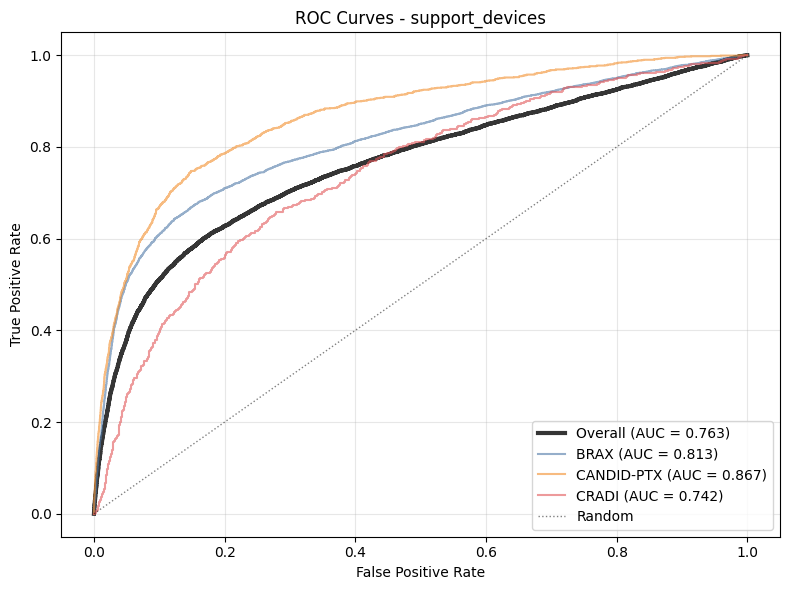

Saved plot: results/public_external_test/all/single_roc_curve_no_finding.png


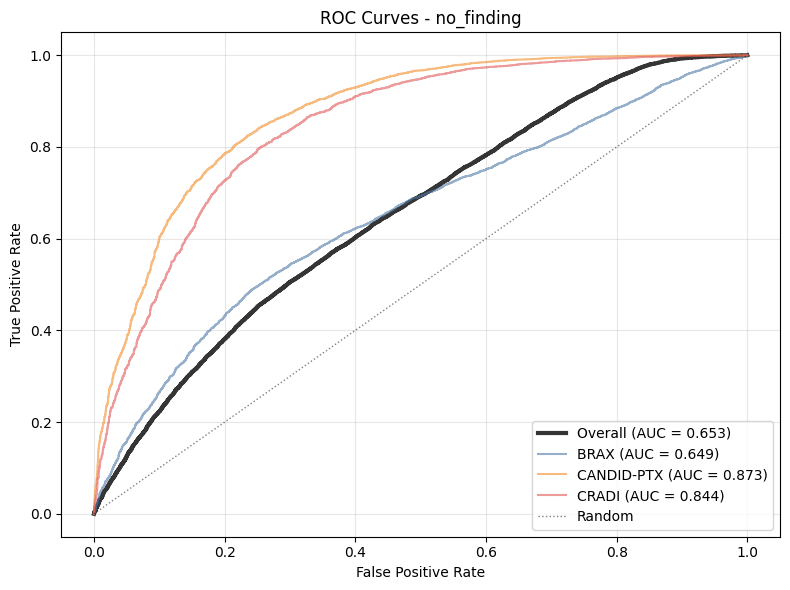

📈 Plotting Single PR Curves (All Datasets)...
Saved plot: results/public_external_test/all/single_pr_curve_pneumothorax.png


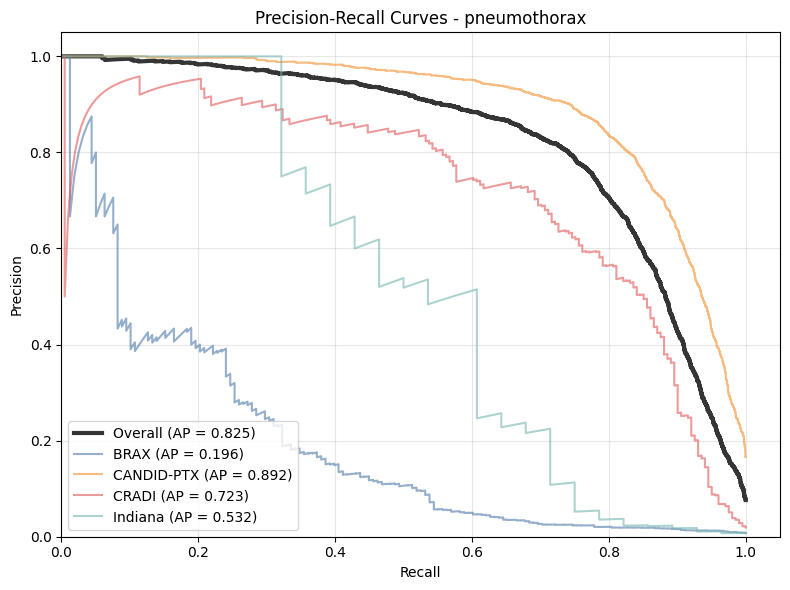

Saved plot: results/public_external_test/all/single_pr_curve_support_devices.png


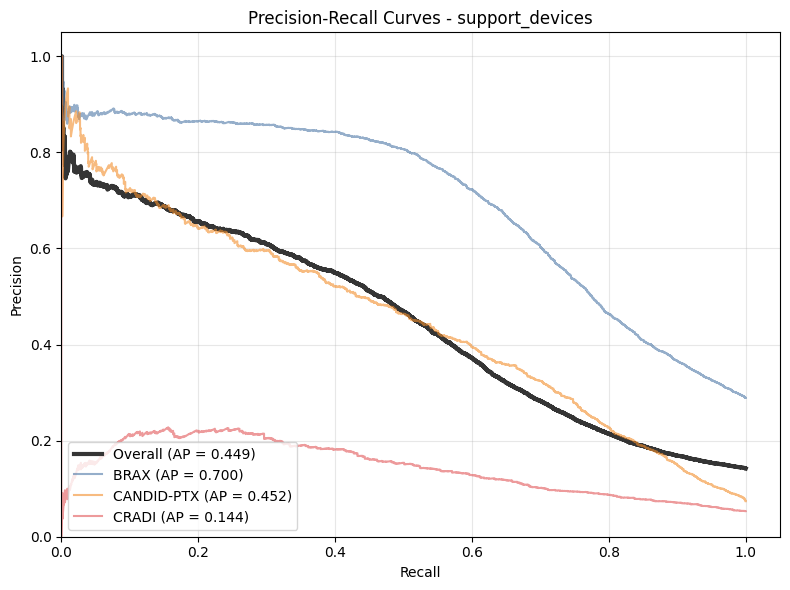

Saved plot: results/public_external_test/all/single_pr_curve_no_finding.png


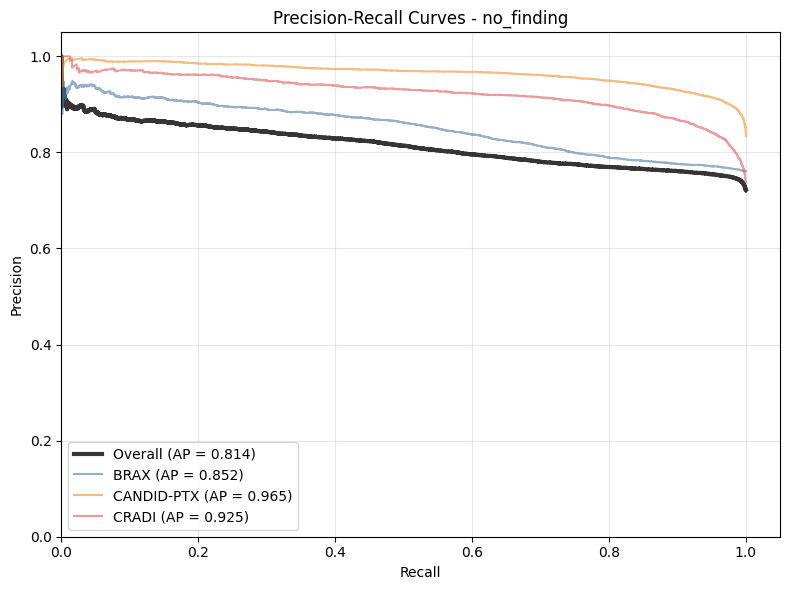


🔍 Analyzing Precision-Recall Tradeoffs...

Precision-Recall Tradeoffs:
          Class Target Metric  Target Value Achieved Metric  Achieved Value  Actual Precision  Threshold  Actual Recall
   pneumothorax     Precision         0.900          Recall           0.555             0.900      0.766            N/A
   pneumothorax     Precision         0.950          Recall           0.405             0.950      0.885            N/A
   pneumothorax        Recall         0.800       Precision           0.706               N/A      0.344          0.800
   pneumothorax        Recall         0.850       Precision           0.596               N/A      0.226          0.850
   pneumothorax        Recall         0.900       Precision           0.428               N/A      0.110          0.900
support_devices     Precision         0.900          Recall           0.002             0.933      0.704            N/A
support_devices     Precision         0.950          Recall           0.001             

In [94]:
all_valid_results = evaluate_model(y_true, y_probs, class_names, threshold = [0.2, 0.5, 0.5], save_dir = 'results/public_external_test/all', use_optimal_thresholds=False, log_wandb=False, display = True, dataset_values=dataset_values)

In [109]:
individual_results['all'] = all_valid_results
individual_results['all']['y_true'] = y_true
individual_results['all']['y_probs'] = y_probs
individual_results['all']['dataset_values'] = dataset_values


AGGREGATING MULTI-MODEL RESULTS

📊 Dataset Availability Check:
✅ Models with dataset information: ['all', 'NIH', 'CheXpert', 'MIMIC', 'PadChest', 'SIIM-ACR', 'VinDR-CXR']
❌ Models without dataset information: []
🔄 Aggregating results from multiple models...
Creating per-metric CSV files...
  Creating CSV for metric: Sensitivity (Recall)
    Saved: results/public_external_test/metric_Sensitivity_Recall_models_vs_datasets.csv
  Creating CSV for metric: Specificity
    Saved: results/public_external_test/metric_Specificity_models_vs_datasets.csv
  Creating CSV for metric: PPV (Precision)
    Saved: results/public_external_test/metric_PPV_Precision_models_vs_datasets.csv
  Creating CSV for metric: NPV
    Saved: results/public_external_test/metric_NPV_models_vs_datasets.csv
  Creating CSV for metric: F1-score
    Saved: results/public_external_test/metric_F1-score_models_vs_datasets.csv
  Creating CSV for metric: AUC
    Saved: results/public_external_test/metric_AUC_models_vs_datasets.cs

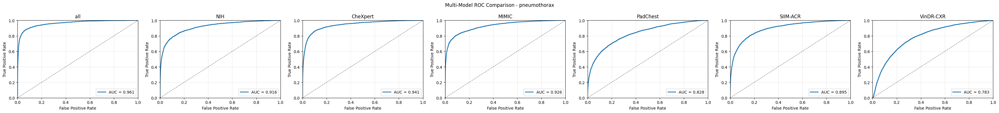

Saved plot: results/public_external_test/multi_model_roc_support_devices.png


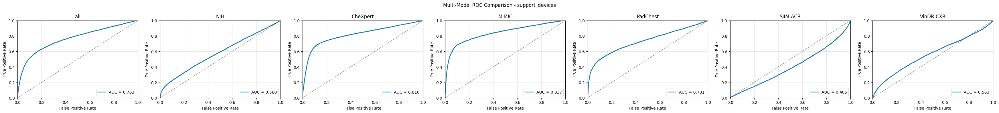

Saved plot: results/public_external_test/multi_model_roc_no_finding.png


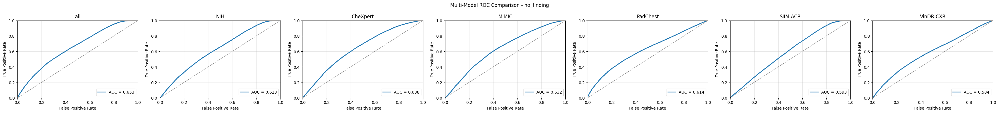

📈 Plotting Multi-Model PR Curves...
Saved plot: results/public_external_test/multi_model_pr_pneumothorax.png


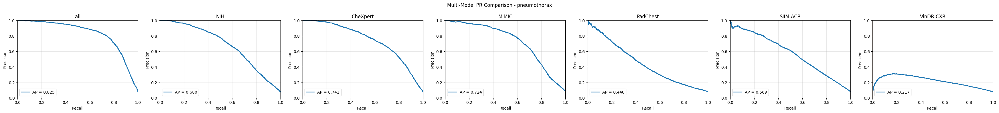

Saved plot: results/public_external_test/multi_model_pr_support_devices.png


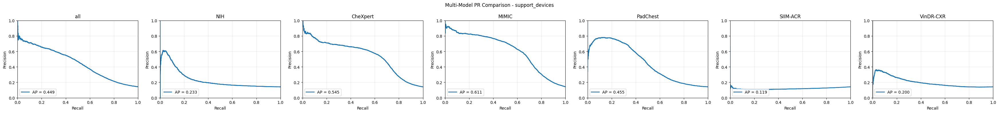

Saved plot: results/public_external_test/multi_model_pr_no_finding.png


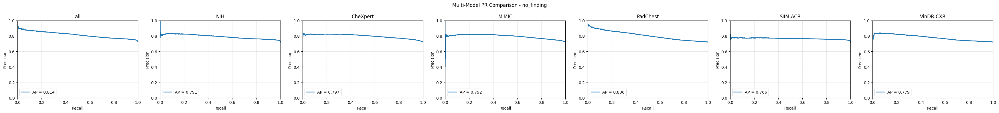

📈 Plotting Multi-Model ROC Curves with Datasets...
Saved plot: results/public_external_test/multi_model_roc_with_datasets_pneumothorax.png


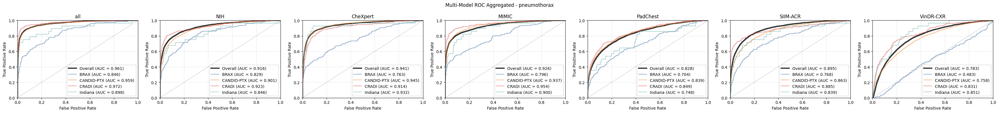

Saved plot: results/public_external_test/multi_model_roc_with_datasets_support_devices.png


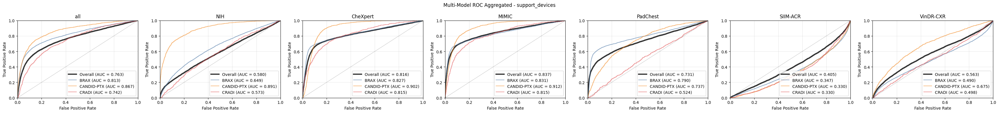

Saved plot: results/public_external_test/multi_model_roc_with_datasets_no_finding.png


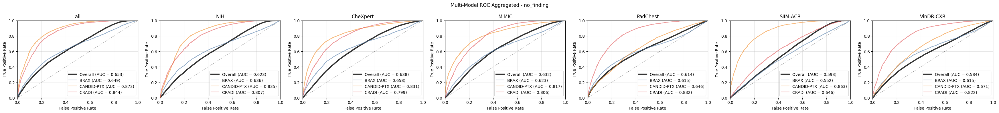

📈 Plotting Multi-Model PR Curves with Datasets...
Saved plot: results/public_external_test/multi_model_pr_with_datasets_pneumothorax.png


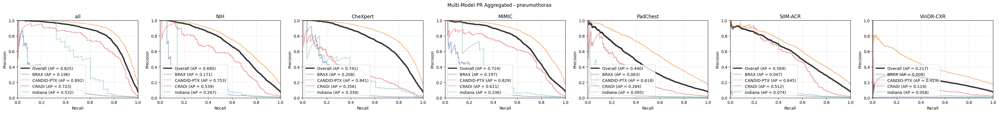

Saved plot: results/public_external_test/multi_model_pr_with_datasets_support_devices.png


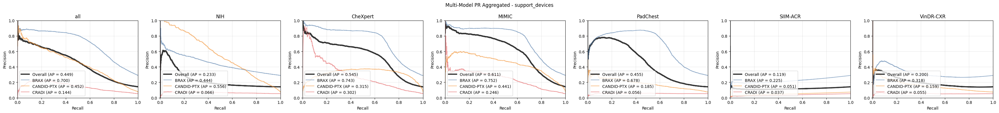

Saved plot: results/public_external_test/multi_model_pr_with_datasets_no_finding.png


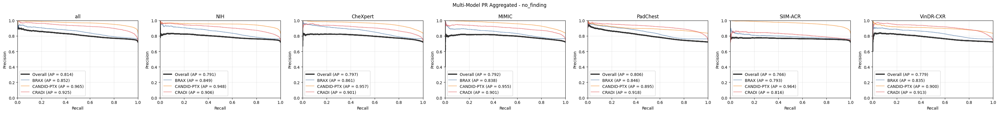

📊 Plotting Multi-Model Comparison - AUC...
Saved plot: results/public_external_test/multi_model_comparison_AUC_pneumothorax.png


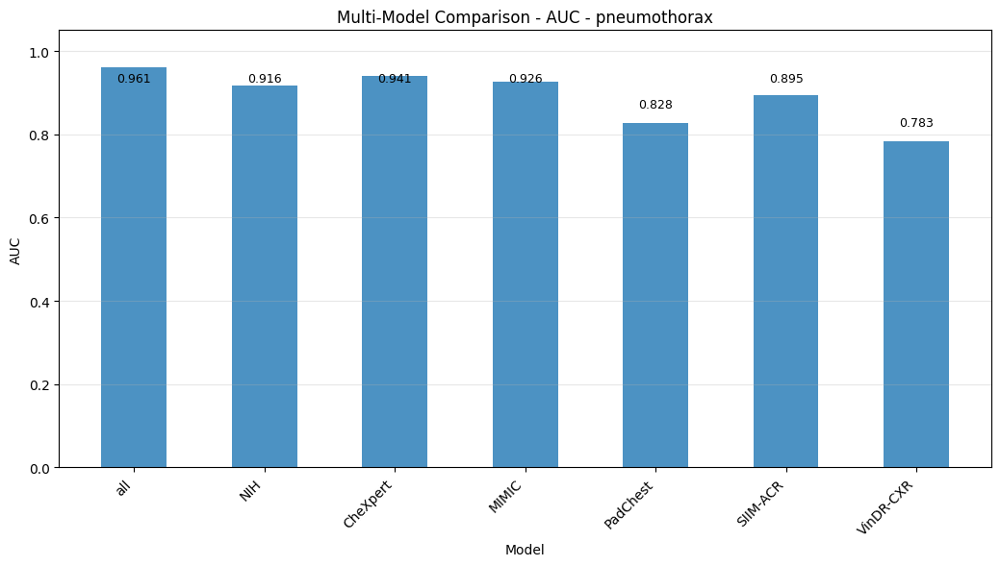

Saved plot: results/public_external_test/multi_model_comparison_AUC_support_devices.png


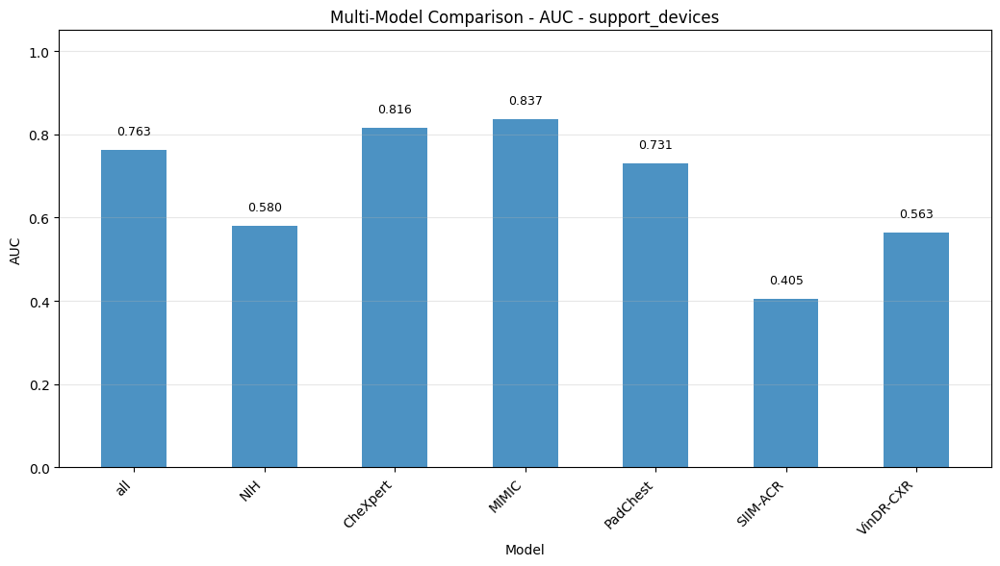

Saved plot: results/public_external_test/multi_model_comparison_AUC_no_finding.png


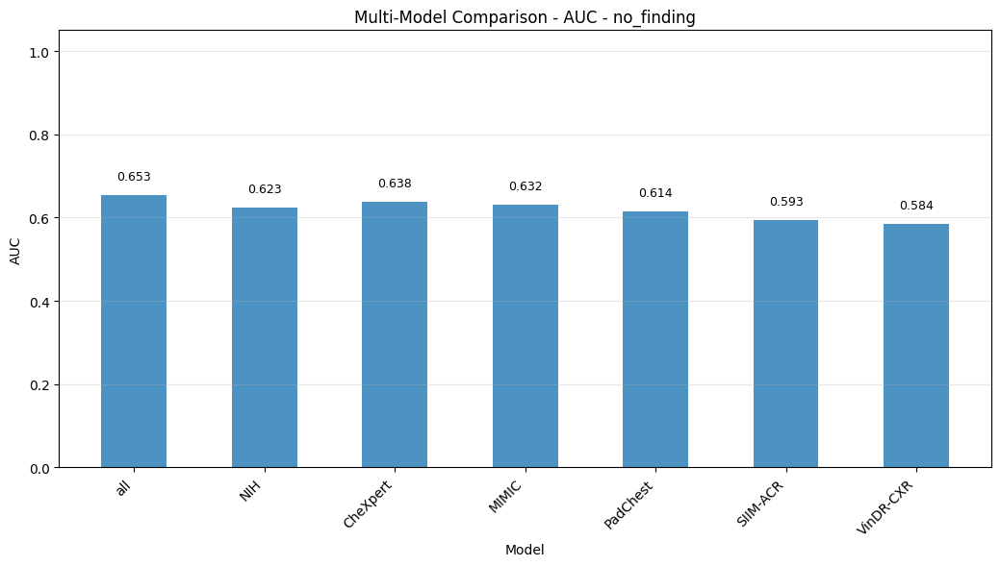

📊 Plotting Multi-Model Comparison - AP...
Saved plot: results/public_external_test/multi_model_comparison_AP_pneumothorax.png


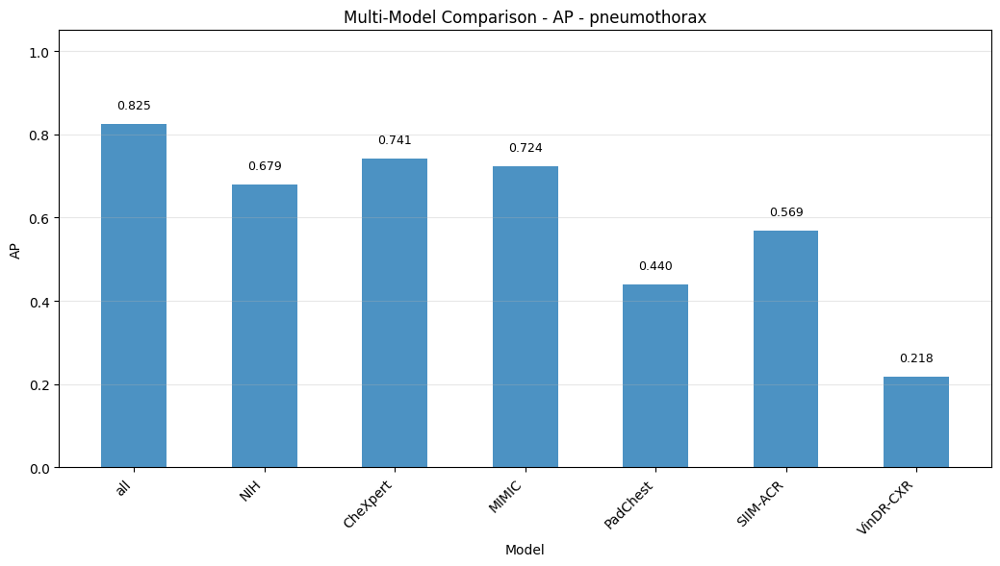

Saved plot: results/public_external_test/multi_model_comparison_AP_support_devices.png


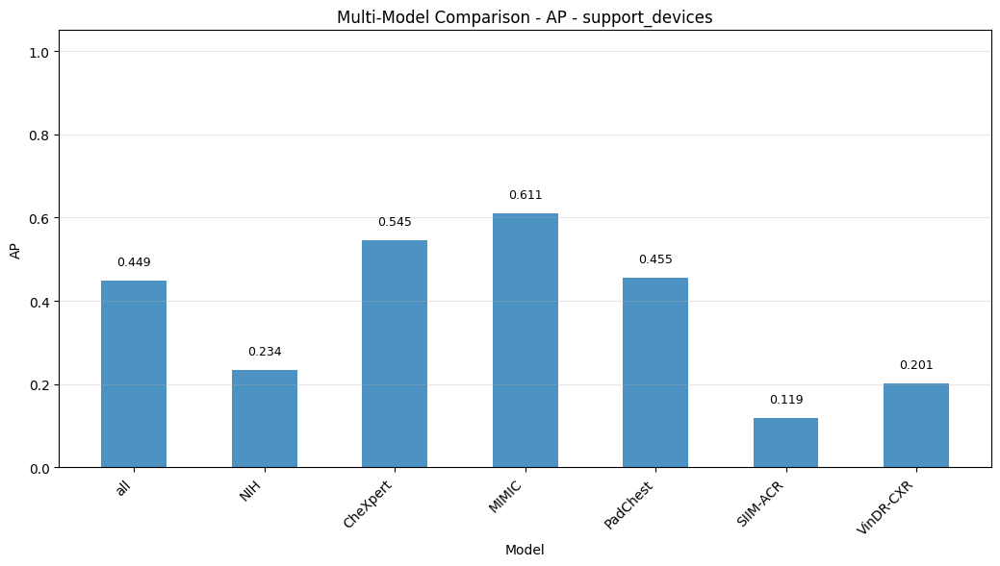

Saved plot: results/public_external_test/multi_model_comparison_AP_no_finding.png


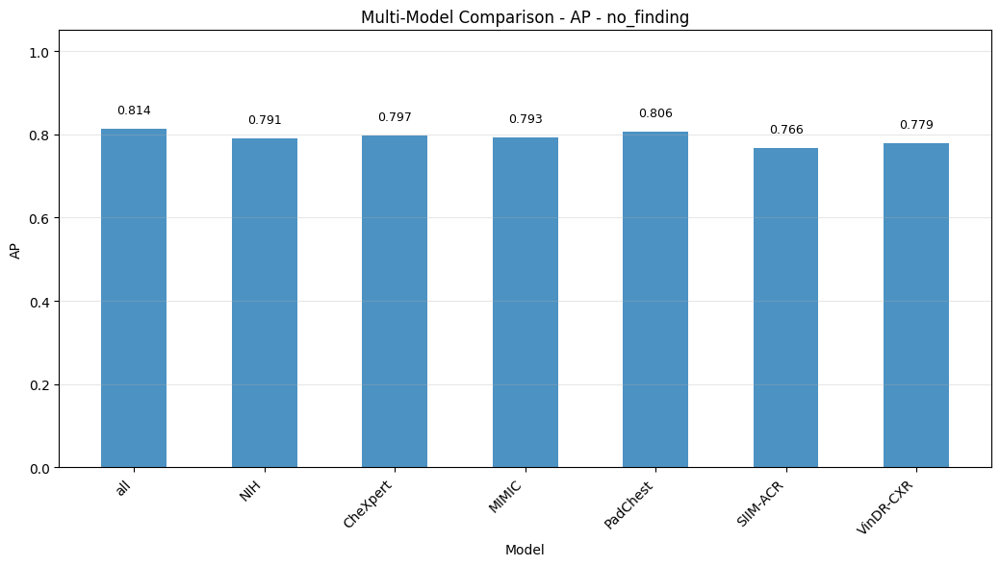

📊 Plotting Multi-Model Comparison - F1-score...
Saved plot: results/public_external_test/multi_model_comparison_F1-score_pneumothorax.png


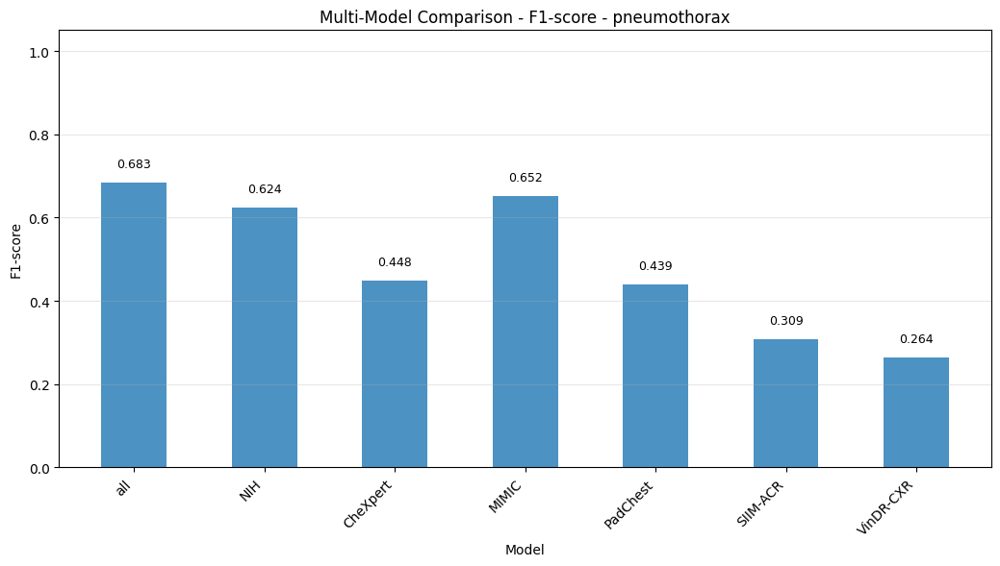

Saved plot: results/public_external_test/multi_model_comparison_F1-score_support_devices.png


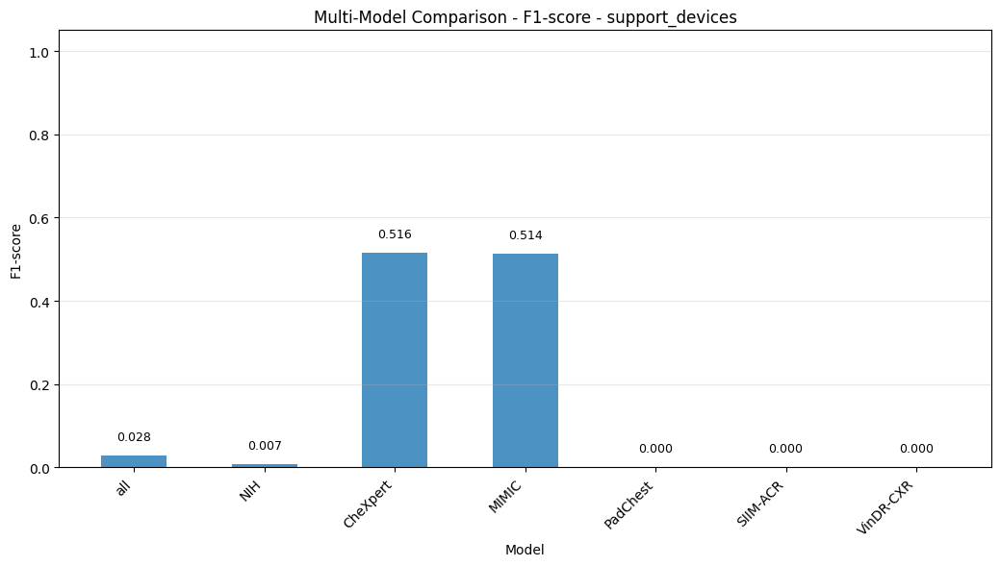

Saved plot: results/public_external_test/multi_model_comparison_F1-score_no_finding.png


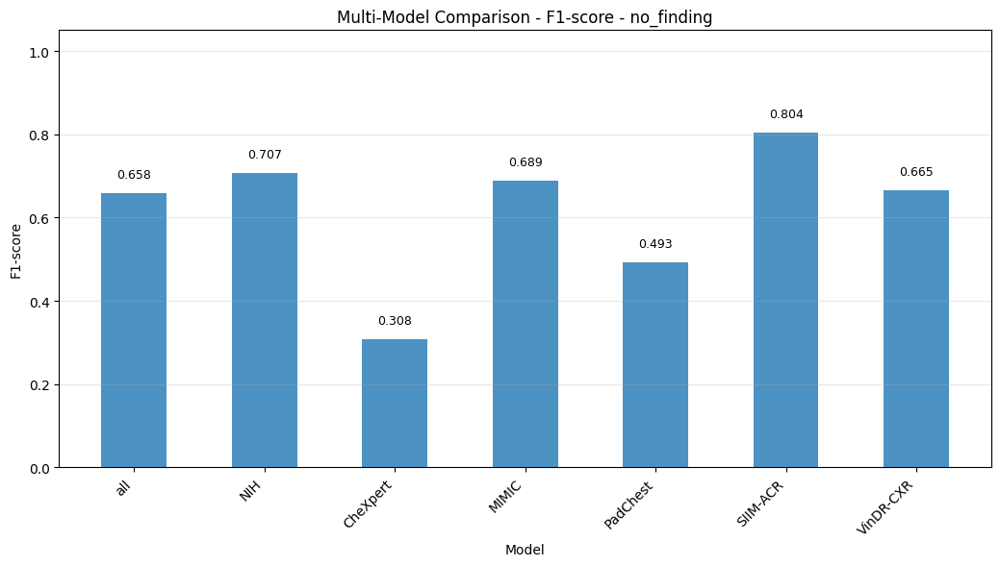

📊 Plotting Multi-Model Comparison - Sensitivity (Recall)...
Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_pneumothorax.png


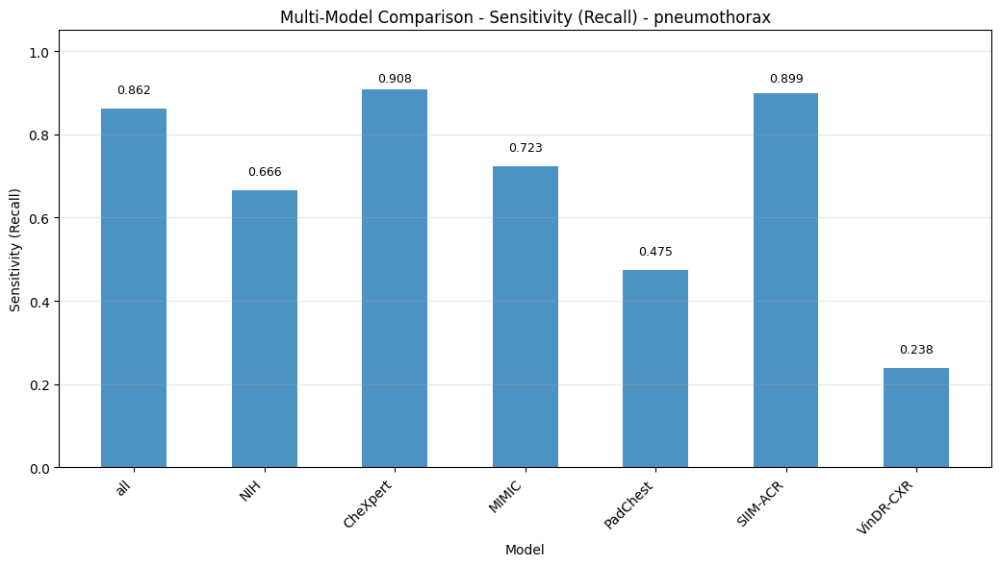

Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_support_devices.png


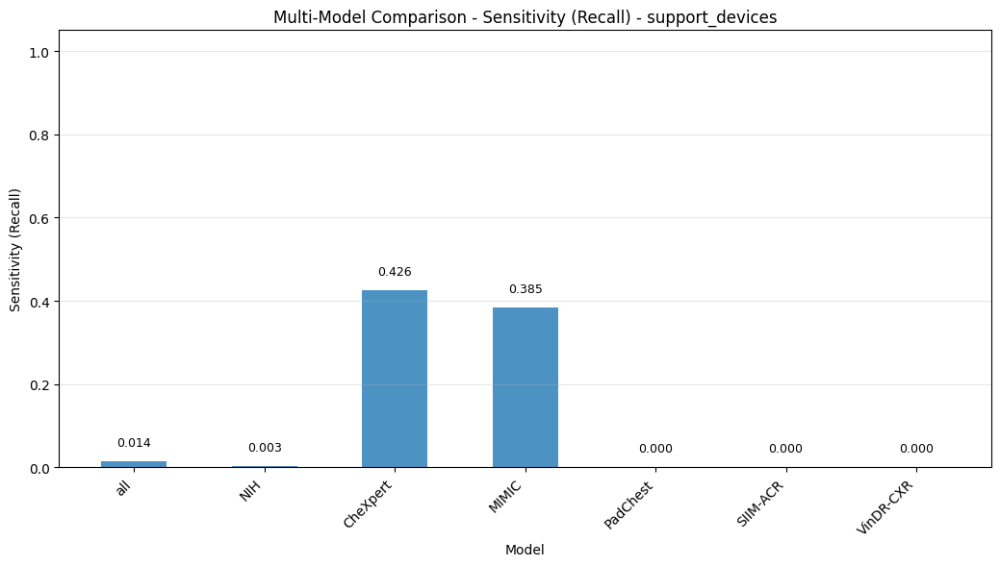

Saved plot: results/public_external_test/multi_model_comparison_Sensitivity_Recall_no_finding.png


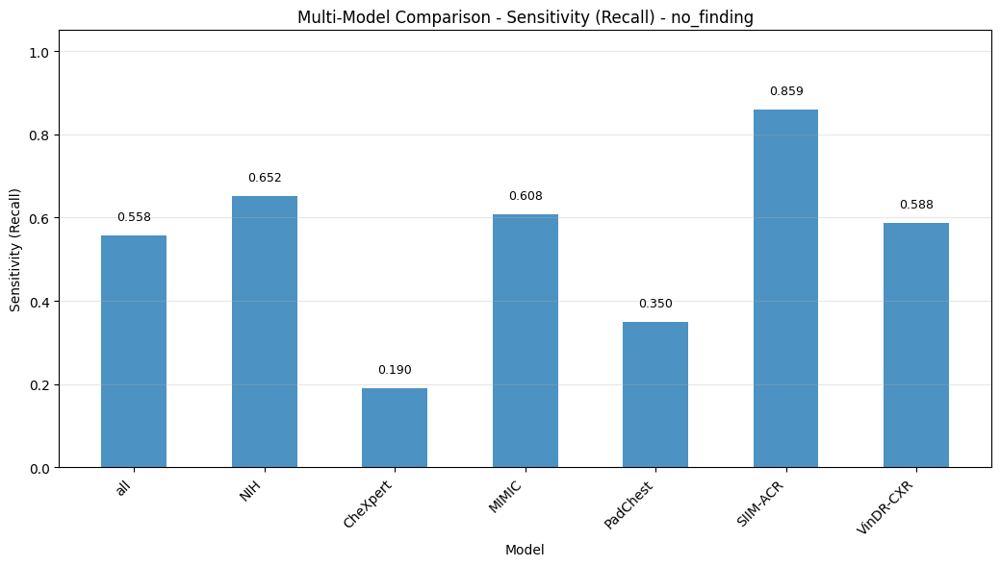

📊 Plotting Multi-Model Comparison - PPV (Precision)...
Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_pneumothorax.png


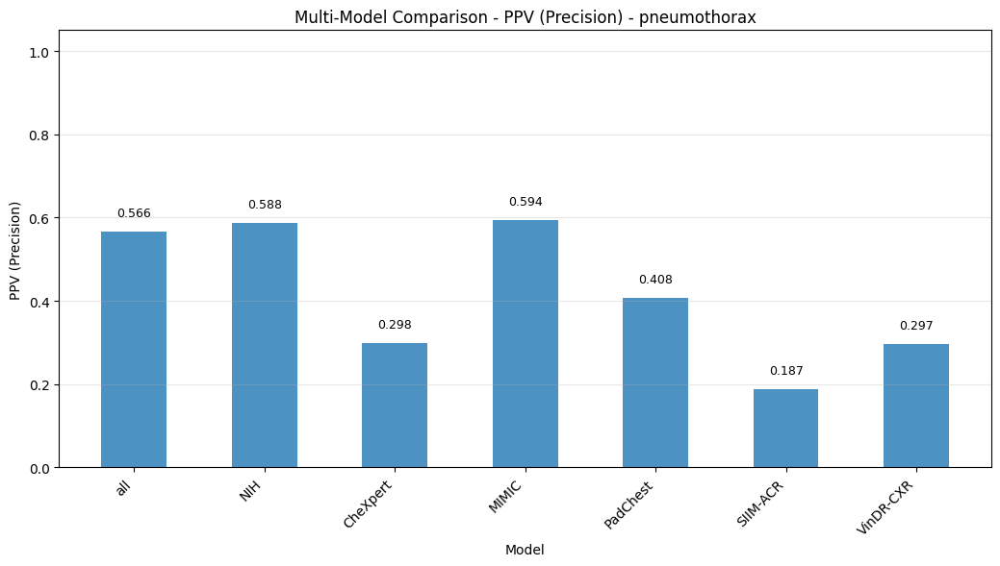

Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_support_devices.png


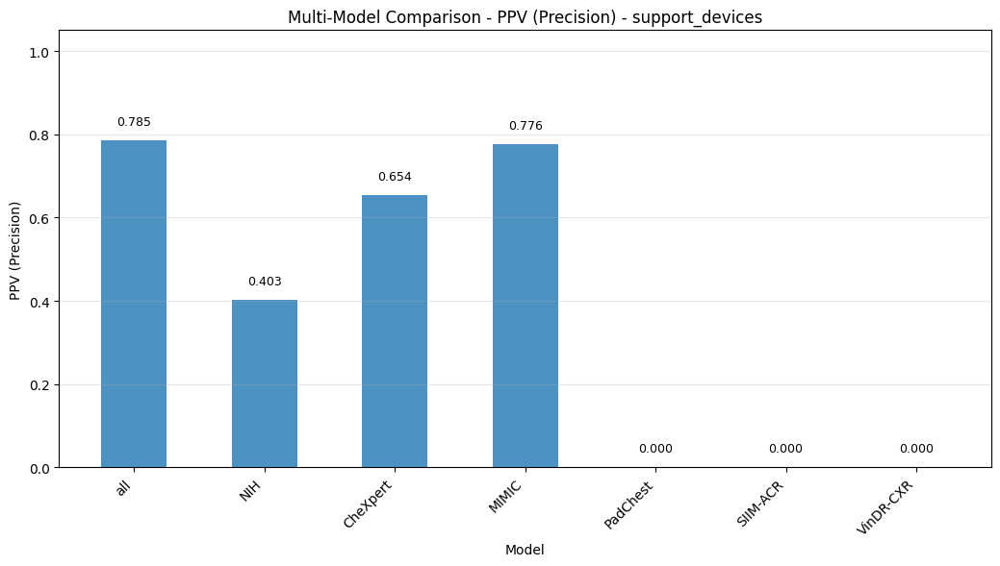

Saved plot: results/public_external_test/multi_model_comparison_PPV_Precision_no_finding.png


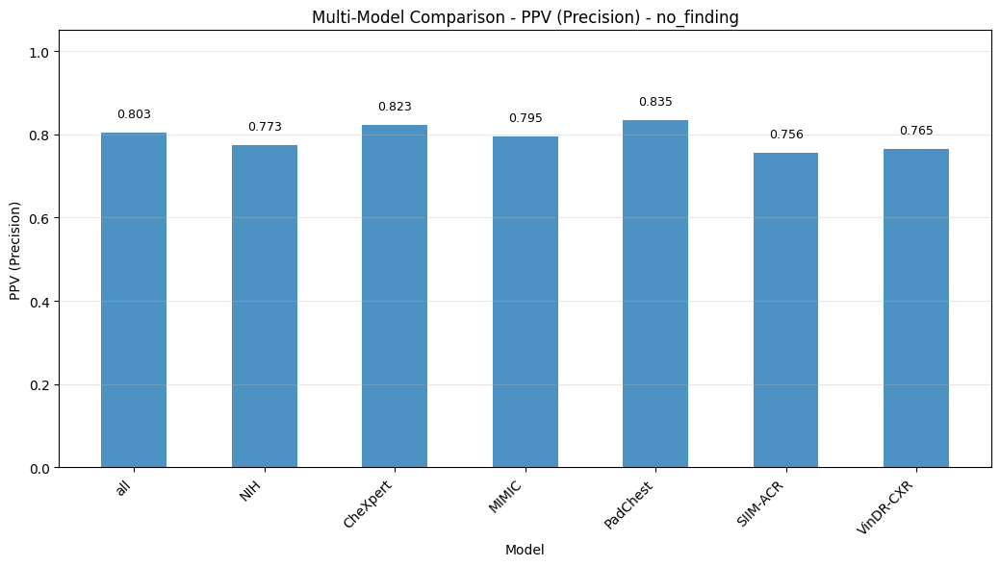

📊 Plotting Multi-Model Comparison - Specificity...
Saved plot: results/public_external_test/multi_model_comparison_Specificity_pneumothorax.png


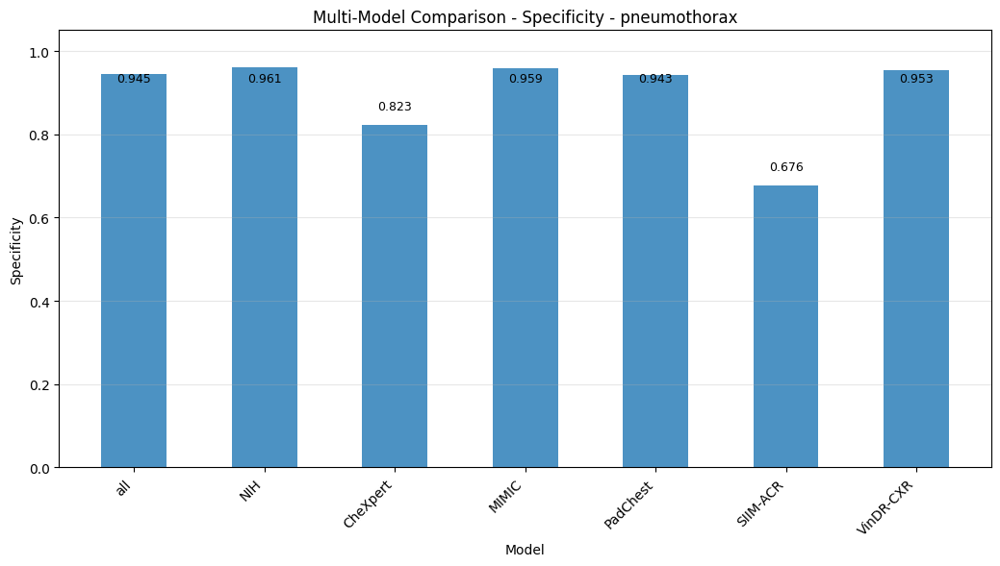

Saved plot: results/public_external_test/multi_model_comparison_Specificity_support_devices.png


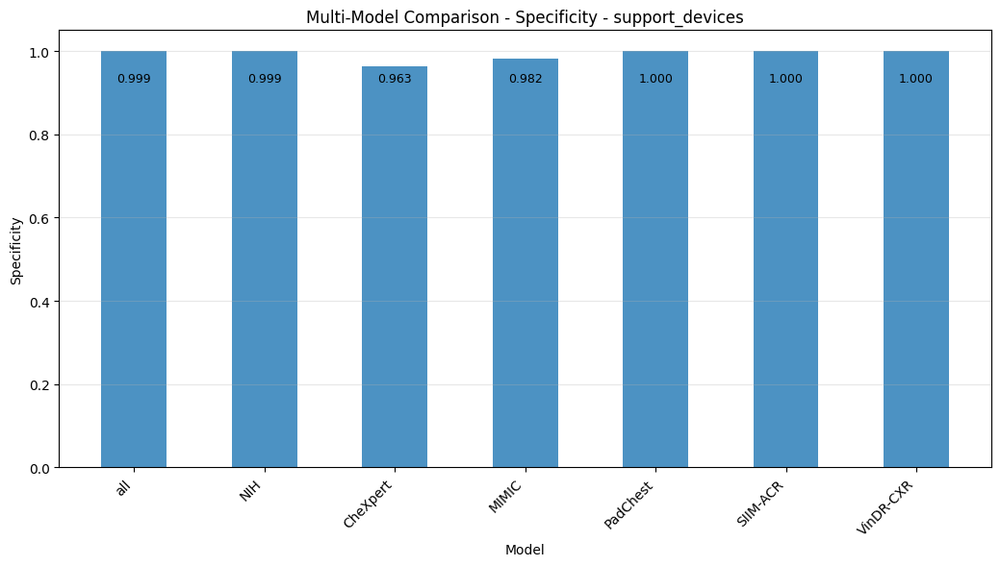

Saved plot: results/public_external_test/multi_model_comparison_Specificity_no_finding.png


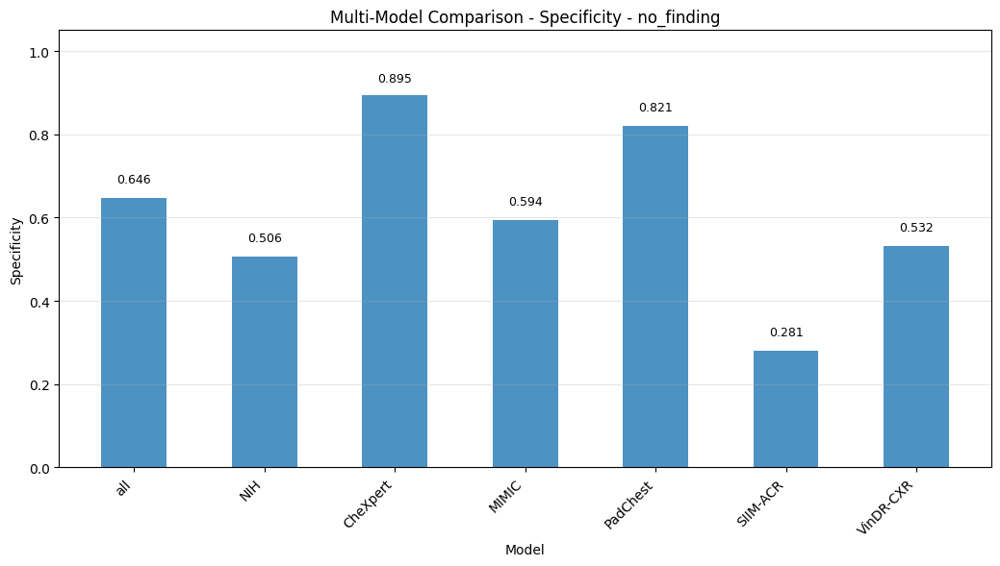

📊 Plotting Multi-Model Comparison - NPV...
Saved plot: results/public_external_test/multi_model_comparison_NPV_pneumothorax.png


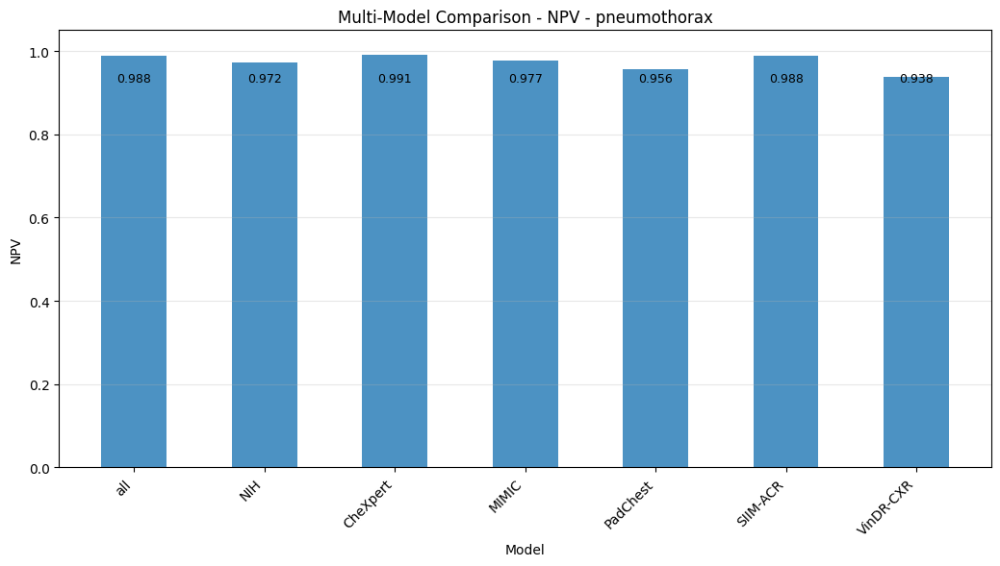

Saved plot: results/public_external_test/multi_model_comparison_NPV_support_devices.png


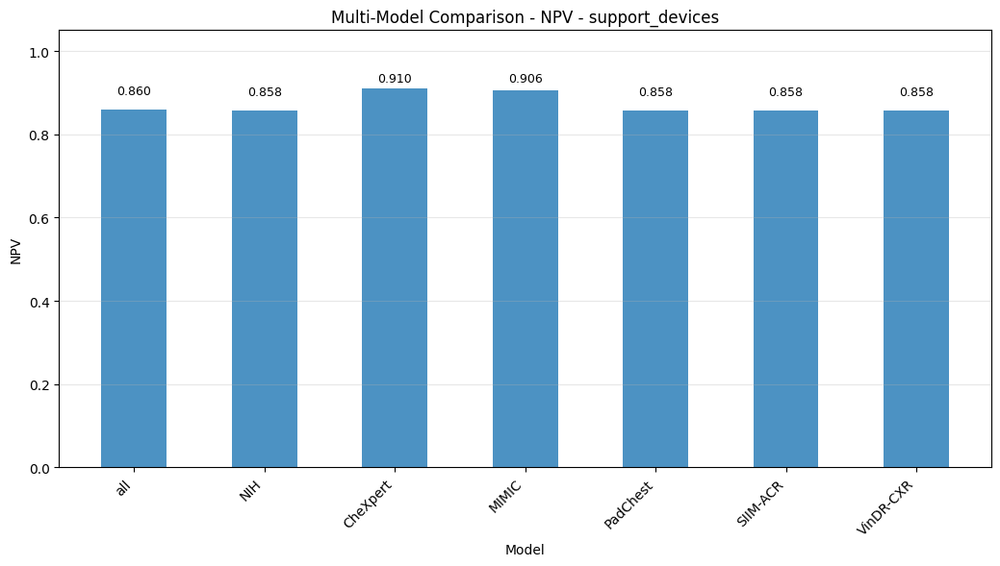

Saved plot: results/public_external_test/multi_model_comparison_NPV_no_finding.png


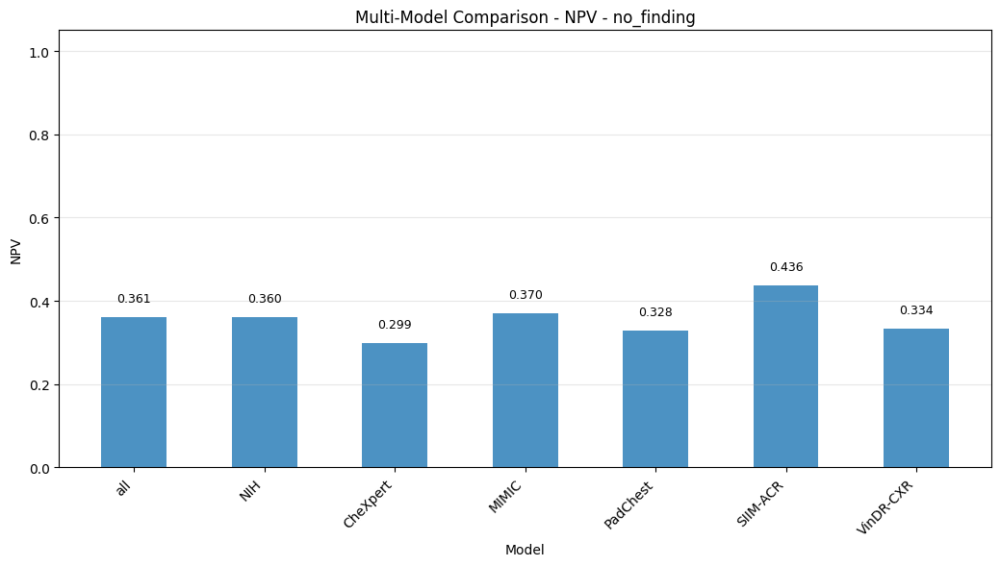

📊 Plotting Multi-Model Comprehensive Comparison...
Saved plot: results/public_external_test/multi_model_comprehensive_pneumothorax.png


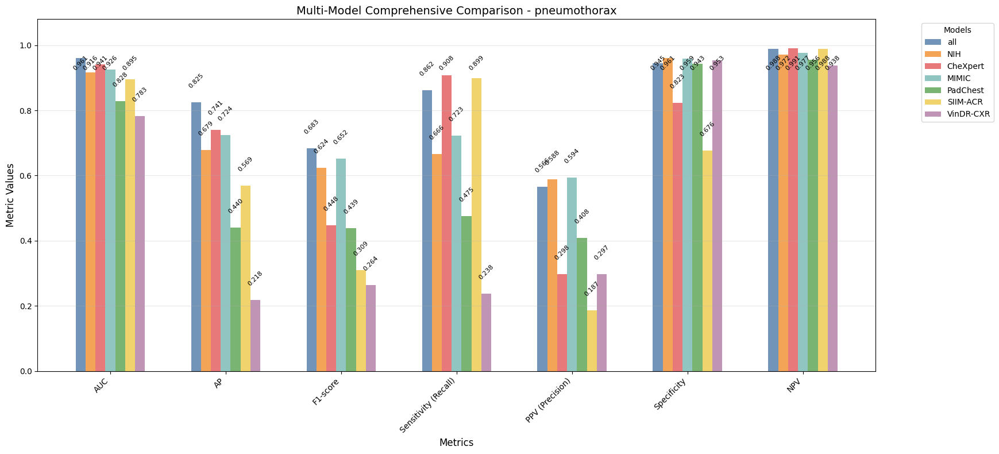

Saved plot: results/public_external_test/multi_model_comprehensive_support_devices.png


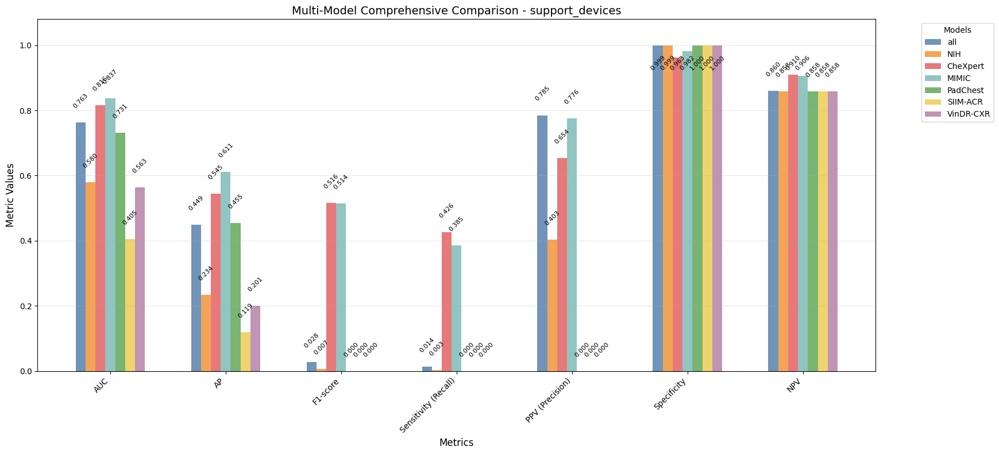

Saved plot: results/public_external_test/multi_model_comprehensive_no_finding.png


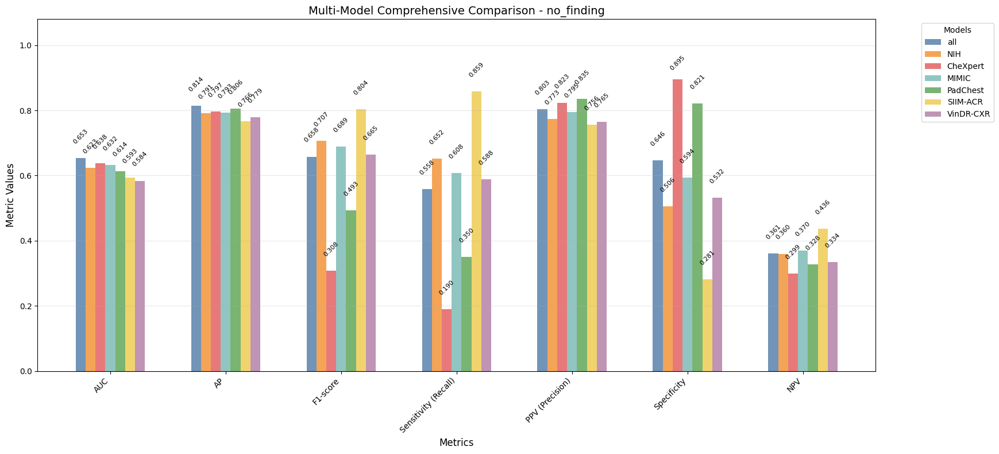

📊 Plotting Multi-Model Confusion Matrices...
Saved plot: results/public_external_test/multi_model_confusion_matrices_pneumothorax.png


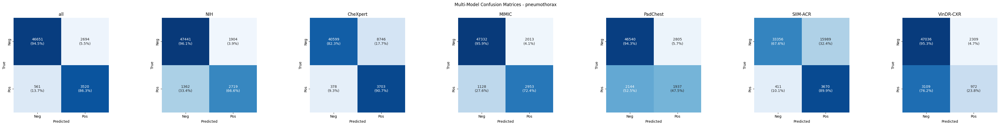

Saved plot: results/public_external_test/multi_model_confusion_matrices_support_devices.png


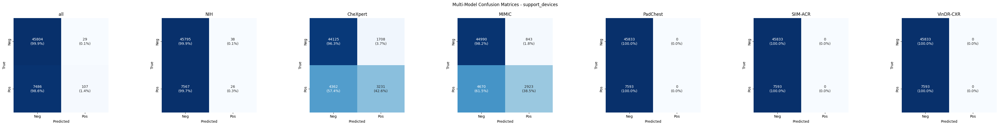

Saved plot: results/public_external_test/multi_model_confusion_matrices_no_finding.png


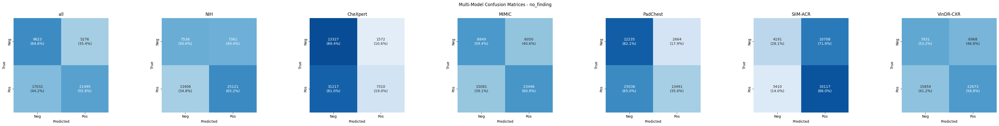

📊 Plotting Multi-Model Dataset Confusion Matrices...


cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_pneumothorax.png


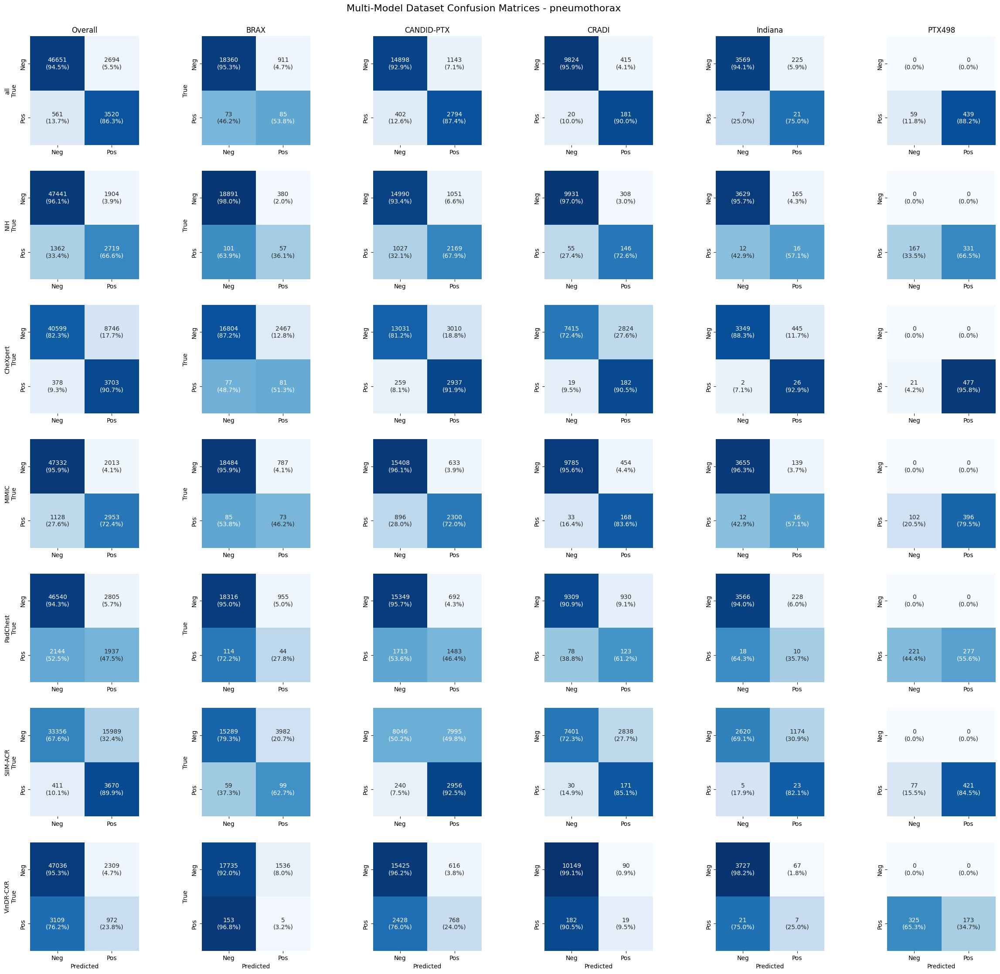

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_support_devices.png


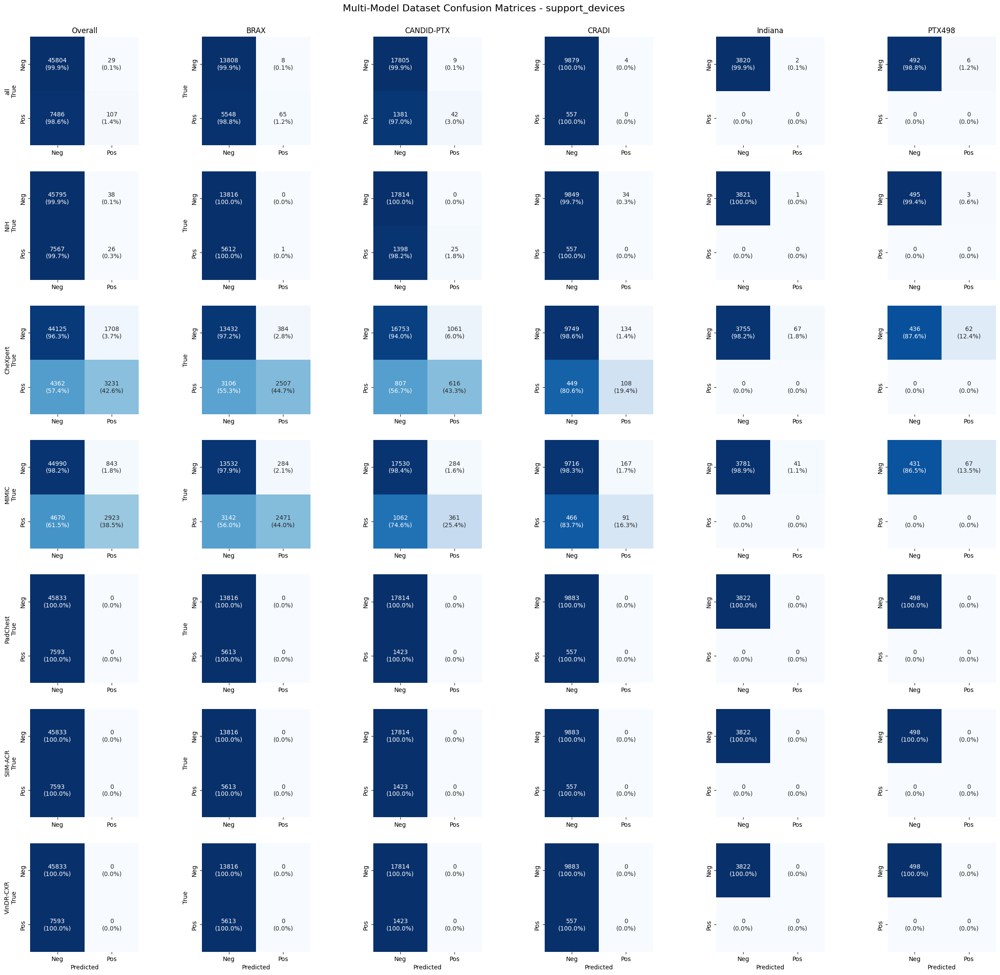

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/public_external_test/multi_model_dataset_confusion_matrices_no_finding.png


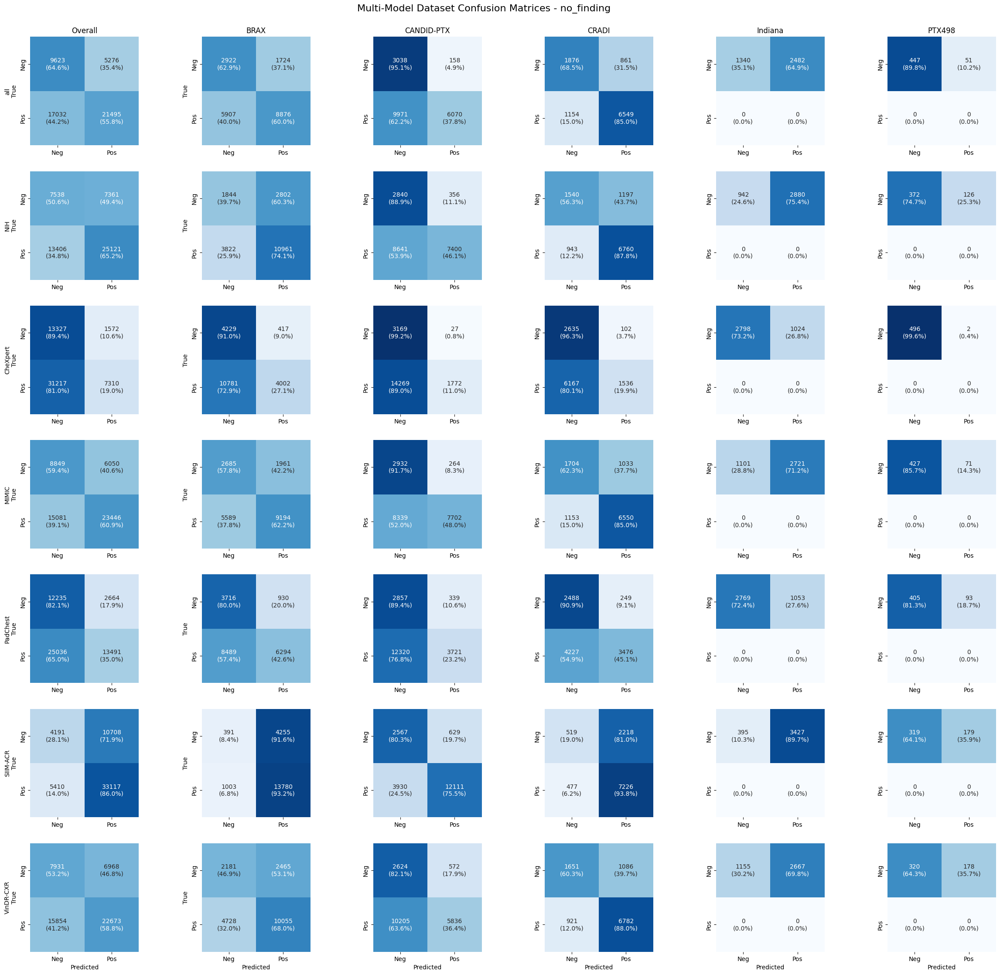


MULTI-MODEL COMPARISON SUMMARY
📊 Aggregated 7 models
📈 Generated ROC and PR comparison plots
📈 Generated ROC and PR plots with individual datasets
📊 Generated comparison plots for 7 metrics
📊 Generated confusion matrix comparison plots
💾 All results saved to: results/public_external_test


In [110]:
# Update aggregated metrics if needed
from cxr.evaluate import aggregate_and_compare_models
updated_aggregation = aggregate_and_compare_models(
    model_results=individual_results,
    class_names=class_names,
    save_dir="results/public_external_test",
    log_wandb=False,
    display=True,
    comparison_metrics=[]
)

In [38]:
import matplotlib.pyplot as plt
import numpy as np

def get_model_errors(y_true, y_probs, image_paths, class_names, threshold=0.5, top_k=10, images_per_row=5, show_errors=True):
    y_pred = (y_probs >= threshold).astype(int)
    errors = {}

    for i, class_name in enumerate(class_names):
        fp_idx = np.where((y_pred[:, i] == 1) & (y_true[:, i] == 0))[0]
        fn_idx = np.where((y_pred[:, i] == 0) & (y_true[:, i] == 1))[0]

        errors[class_name] = {
            "false_positives": [(image_paths[idx], y_probs[idx, i]) for idx in fp_idx],
            "false_negatives": [(image_paths[idx], y_probs[idx, i]) for idx in fn_idx],
        }

        if show_errors:
            print(f"\n🧪 Class: {class_name}")
            print(f"  ❌ False Positives: {len(fp_idx)} | ❌ False Negatives: {len(fn_idx)}")

            def show_imgs(indices, title):
                n = min(len(indices), top_k)
                rows = (n + images_per_row - 1) // images_per_row
                fig, axes = plt.subplots(rows, images_per_row, figsize=(images_per_row * 3, rows * 3))

                if rows == 1:
                    axes = np.expand_dims(axes, 0)  # make sure it's 2D
                axes = axes.flatten()

                for j in range(n):
                    idx = indices[j]
                    img = plt.imread(image_paths[idx])
                    axes[j].imshow(img, cmap='gray')
                    axes[j].set_title(f"{title}\nConf: {y_probs[idx, i]:.2f}")
                    axes[j].axis("off")

                for ax in axes[n:]:
                    ax.axis("off")

                plt.tight_layout()
                plt.show()

            if len(fp_idx) > 0:
                print("🔺 False Positives:")
                show_imgs(fp_idx, "FP")
            if len(fn_idx) > 0:
                print("🔻 False Negatives:")
                show_imgs(fn_idx, "FN")

    return errors


In [40]:
image_paths

['/path/to/ds-CXR/BRAX/1.1.0/images/id_b994b082-b6c73a7b-8814a396-98a6e40a-b7fa9bcf/Study_56633486.16087785.56521205.52706845.94638888/Series_98833432.59777342.84371328.14689963.92387700/image-09872401-24512055-03006861-80953593-95925493.png',
 '/path/to/ds-CXR/BRAX/1.1.0/images/id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-715ee928/Study_59079977.90444904.90062301.38804843.62627869/Series_35593723.22449412.30736547.94937025.18364404/image-62192350-54798697-62305166-18283897-16144875.png',
 '/path/to/ds-CXR/BRAX/1.1.0/images/id_c19146e8-7d3affaf-29f5891c-a93dc58d-7dc60587/Study_72168825.37991083.65146716.75234339.31943540/Series_93952143.60652101.40698325.27969570.70123776/image-07512885-51434008-93021318-73432689-61904685.png',
 '/path/to/ds-CXR/BRAX/1.1.0/images/id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3550b82/Study_74085579.94453418.47850482.42878141.24460460/Series_55520360.10393679.72505973.06789700.04998172/image-91589489-61085701-91078340-04363443-73041241.png',
 '/path/to/ds-CXR/BRAX/1

In [39]:
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=13
)



🧪 Class: pneumothorax
  ❌ False Positives: 2309 | ❌ False Negatives: 3109
🔺 False Positives:


<Figure size 1500x900 with 15 Axes>

🔻 False Negatives:


<Figure size 1500x900 with 15 Axes>


🧪 Class: support_devices
  ❌ False Positives: 1 | ❌ False Negatives: 7593
🔺 False Positives:


...

<Figure size 1500x900 with 15 Axes>


🧪 Class: no_finding
  ❌ False Positives: 9374 | ❌ False Negatives: 11088
🔺 False Positives:


<Figure size 1500x900 with 15 Axes>

🔻 False Negatives:


<Figure size 1500x900 with 15 Axes>

In [42]:
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=100
)



🧪 Class: pneumothorax
  ❌ False Positives: 2309 | ❌ False Negatives: 3109
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>


🧪 Class: support_devices
  ❌ False Positives: 1 | ❌ False Negatives: 7593
🔺 False Positives:


...

<Figure size 1500x6000 with 100 Axes>


🧪 Class: no_finding
  ❌ False Positives: 9374 | ❌ False Negatives: 11088
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>

In [62]:
df_brax = df.loc[df.dataset=='BRAX']
df_indiana = df.loc[df.dataset=='Indiana']
df_not_brax = df.loc[df.dataset!='BRAX']

In [47]:
# NOT BRAX only

In [63]:
df_to_use = df_indiana

In [64]:
y_true, y_probs = get_predictions_from_df(df_to_use, class_names, model_name=model_name, dataset=None)

In [65]:
_, external_test_generator, _ = create_generators(df_train = df_to_use, df_test = df_to_use, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

Found 3822 non-validated image filenames.
Found 3822 non-validated image filenames.
Found 3822 non-validated image filenames.


In [ ]:
# Without BRAX

In [61]:
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=100
)



🧪 Class: pneumothorax
  ❌ False Positives: 773 | ❌ False Negatives: 2956
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>


🧪 Class: support_devices
  ❌ False Positives: 0 | ❌ False Negatives: 1980
🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>


🧪 Class: no_finding
  ❌ False Positives: 6077 | ❌ False Negatives: 7849
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>

In [ ]:
# BRAX only

In [56]:
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=100
)



🧪 Class: pneumothorax
  ❌ False Positives: 1536 | ❌ False Negatives: 153
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>


🧪 Class: support_devices
  ❌ False Positives: 1 | ❌ False Negatives: 5613
🔺 False Positives:


...

<Figure size 1500x6000 with 100 Axes>


🧪 Class: no_finding
  ❌ False Positives: 3297 | ❌ False Negatives: 3239
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>

🔻 False Negatives:


<Figure size 1500x6000 with 100 Axes>

In [66]:

# indiana only
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=100
)



🧪 Class: pneumothorax
  ❌ False Positives: 67 | ❌ False Negatives: 21
🔺 False Positives:


<Figure size 1500x4200 with 70 Axes>

🔻 False Negatives:


<Figure size 1500x1500 with 25 Axes>


🧪 Class: support_devices
  ❌ False Positives: 0 | ❌ False Negatives: 0

🧪 Class: no_finding
  ❌ False Positives: 3201 | ❌ False Negatives: 0
🔺 False Positives:


<Figure size 1500x6000 with 100 Axes>